# SER Multi-Corpus — V10 Multi-Model

This notebook implements a multi-corpus, multi-model pipeline for speech emotion
recognition (SER): data auditing, feature extraction and caching, model training
and evaluation, statistical testing, and export of result tables.

## Key methodological choices

| Topic | Approach | Section |
|---|---|---|
| **Small-corpus generalization (TESS)** | TESS accounts for a large share of a naive headline figure at near-ceiling accuracy, with the same two voices appearing on both sides of a random split. `small_corpus_policy="holdout_strict"` holds out **both** speaker identity **and** script content, so the TESS test set shares neither voice nor text with training. Results are reported at three nested levels, with the headline figure excluding **both** TESS and MLEnd. | 6, 11 |
| **Cross-validation** | Speaker-independent 5-fold cross-validation is the primary protocol, run by a scheduler that executes the experiment plan under a measured hourly budget and can resume from where it left off. | 14, 19 |
| **Ablations** | A full ablation registry is executed, with paired McNemar tests, bootstrap confidence intervals, and Holm correction for multiple comparisons. A dedicated `spec_aug_fixed` ablation isolates the effect of a cached mel-spectrogram before drawing conclusions about the spectral branch's gate weight. | 15 |
| **Per-corpus label inventories** | Metrics are restricted to the classes actually present in each corpus, together with the rate of out-of-inventory predictions, which is the more informative diagnostic for corpora with fewer emotion classes (e.g. MLEnd). | 11 |
| **Precision/recall trade-off** | Rather than a single blended metric, the precision/recall trade-off for hard classes (e.g. `fearful`) is reported explicitly via a logit-adjustment sweep, a per-class table, and calibration error (ECE). | 11 |
| **Test-set sizing** | Cross-validation places every utterance in the test set exactly once, giving properly sized, interpretable test sets per corpus (EMODB ≈494 test utterances, SAVEE 480, rather than a few dozen). | 14 |

## Additional components

- **Leave-one-corpus-out (LOCO)**, run across all six corpora — the primary
  measure of cross-corpus generalization, and the principled way to obtain a
  TESS generalization figure from a model that has never heard the TESS
  speakers' voices.
- **Corpus-identity probe** on the fused representation: a logistic-regression
  classifier trained to recover corpus identity from the embedding checks
  whether the network is encoding recording-channel information rather than
  emotion.
- **Baselines**: majority class, duration-only, and prosody-only (75-D), so
  headline UAR figures have a reference point.
- **Paired statistical tests** with correction for multiple comparisons.
- **LaTeX export** of the paper's result tables.
- **Reproducibility measures**: explicit per-worker DataLoader seeding (so
  augmentation is not duplicated across workers), a loss selection that is
  actually driven by `cfg["loss"]`, and logging of training class counts
  needed for logit adjustment.

## Recommended execution order

`Run All` executes the full experiment plan under the configured hourly budget
and stops cleanly. For a first pass, leave `CFG["preset"] = "quick"`; switch to
`"paper"` to reproduce the final reported figures.

> **V10 multi-model extension**: adds WavLM + HuBERT + Wav2Vec2 encoders with
> all-layer aggregation, a consolidated matrix cache, latent-space
> augmentation, cross-model attention, hierarchical fusion, and
> speaker-disjoint cross-validation on the same 5 folds as the baseline. V10
> also adds strict-protocol (A) evaluation and LOCO.


In [1]:
# !pip install -q transformers librosa soundfile

## 0. Configuration and budget

Three presets. `smoke` checks that the full pipeline runs end to end in a few
minutes; `quick` produces reasonable but under-trained figures, useful for
deciding between ablations; `paper` is the budget used for the figures
reported in the paper.

The `budget_hours` field is not decorative: the scheduler in Section 19
measures the actual duration of the first training run and only commits to
experiments that fit in the remaining time, in priority order.


In [2]:
import json, os, random, hashlib, warnings, time, math, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy import stats
from sklearn.metrics import (balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             precision_recall_fscore_support)

warnings.filterwarnings("ignore")

CFG = dict(
    # --- signal -------------------------------------------------------------
    sr=16000, seconds=3.0, n_mels=128,
    hop_length=160, n_fft=512,
    pad_mode="repeat",

    # --- optimization ---------------------------------------------------------
    batch_size=16, grad_accum=2,
    lr=3e-4, encoder_lr=1e-5, weight_decay=1e-2,
    epochs=60, patience=12, warmup_ratio=0.1, clip_grad=5.0,

    # --- model --------------------------------------------------------------
    dropout=0.3, d_model=256, d_fusion=512,
    wavlm_name="microsoft/wavlm-base-plus",
    unfreeze_last_n=0, weighted_layers=True, fusion="gated",
    use_wavlm=True, use_spec=True, use_feat=True,
    spec_pos_encoding=True, spec_conv_stem=True,

    # --- loss -----------------------------------------------------------------
    # Loss selection is driven directly by this field.
    loss="cb_focal",                    # ce | weighted_ce | focal | cb_focal
    focal_gamma=2.0, label_smoothing=0.05,

    # --- corpus -----------------------------------------------------------
    mlend_policy="conservative",
    mlend_max_per_speaker=30,
    mlend_nationalities=None,
    calm_policy="drop",

    # --- protocol -------------------------------------------------------------
    protocol="speaker_independent",
    # Policy for corpora that do not have enough distinct speakers to allow a
    # speaker-disjoint split. "holdout_strict" is the only choice that makes
    # the resulting test metric defensible; the others exist for comparison.
    small_corpus_policy="holdout_strict",   # holdout_strict | sentence_fallback
                                            # | train_only | drop
    min_speakers_disjoint=3,
    n_folds=5,                          # primary protocol
    seed=42,
    seeds=(42, 123, 456),

    # Nested result tiers. The first tier is the headline figure for the paper.
    tiers={
        "A_principal": ("MLEnd", "TESS"),   # 4 acted corpora, >= 4 speakers each
        "B_actes":     ("MLEnd",),          # + TESS
        "C_tout":      (),                  # + MLEnd
    },

    # --- misc -----------------------------------------------------------------
    aug_recompute_mel=False,
    n_boot=2000,
    preset="quick",                     # smoke | quick | paper
    budget_hours=7.5,                   # Kaggle T4 session = 9 h maximum
    cache_dir="/kaggle/working/feat_cache",
    out_dir="/kaggle/working/runs",
)

PRESETS = dict(
    smoke=dict(epochs=1, patience=1, n_boot=200, n_folds=2, budget_hours=0.5),
    quick=dict(epochs=18, patience=5, n_boot=1000, n_folds=5),
    paper=dict(epochs=60, patience=12, n_boot=2000, n_folds=5),
)
CFG.update(PRESETS[CFG["preset"]])
# Training budget for secondary experiments (ablations, LOCO, LOSO),
# deliberately shorter than the primary protocol's budget.
CFG["epochs_experiment"] = max(1, min(CFG["epochs"], 18))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)


seed_everything(CFG["seed"])
Path(CFG["out_dir"]).mkdir(parents=True, exist_ok=True)
print(f"device: {DEVICE} | torch: {torch.__version__} | preset: {CFG['preset']} "
      f"| epochs={CFG['epochs']} patience={CFG['patience']} "
      f"| budget={CFG['budget_hours']} h")


device: cuda | torch: 2.10.0+cu128 | preset: quick | epochs=18 patience=5 | budget=7.5 h


## 1. Multi-corpus manifest

Builds the manifest across corpora: Kaggle root discovery, filename-based
parsers per corpus, deduplication, verification against official corpus
counts, exclusion of RAVDESS singing clips, and MLEnd parsed from its CSV
files with a cap per (speaker, class).


In [3]:
# =============================================================================
# CELL 1 — Multi-corpus manifest (EMODB, RAVDESS, CREMA-D, TESS, SAVEE, MLEnd)
# =============================================================================
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Emotion label tables
# --------------------------------------------------------------------------- #
EMODB_CODE = {"W": "angry", "E": "disgust", "A": "fearful", "F": "happy",
              "T": "sad", "N": "neutral", "L": "boredom"}
RAVDESS_CODE = {"01": "neutral", "02": "calm", "03": "happy", "04": "sad",
                "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised"}
CREMA_CODE = {"ANG": "angry", "DIS": "disgust", "FEA": "fearful",
              "HAP": "happy", "NEU": "neutral", "SAD": "sad"}
TESS_CODE = {"angry": "angry", "disgust": "disgust", "fear": "fearful",
             "happy": "happy", "neutral": "neutral", "sad": "sad",
             "ps": "surprised", "pleasant_surprise": "surprised",
             "surprise": "surprised", "surprised": "surprised"}
SAVEE_CODE = {"a": "angry", "d": "disgust", "f": "fearful", "h": "happy",
              "n": "neutral", "sa": "sad", "su": "surprised"}

# Official corpus sizes, used to detect a partial or duplicated scan
EXPECTED = {"EMODB": 535, "RAVDESS": 1440, "CREMA-D": 7442,
            "TESS": 2800, "SAVEE": 480, "MLEnd": None}   # MLEnd varies with the filter

# Search patterns for auto-discovery under /kaggle/input
DATASET_HINTS = {
    "EMODB":   ["berlin-database-of-emotional-speech", "emodb", "emo-db"],
    "RAVDESS": ["ravdess"],
    "CREMA-D": ["cremad", "crema-d", "crema_d"],
    "TESS":    ["toronto-emotional-speech", "tess"],
    "SAVEE":   ["savee", "surrey-audiovisual"],
    "MLEnd":   ["mlend-spoken-numerals", "mlend", "mlendsnd"],
}


# --------------------------------------------------------------------------- #
# Parsers (return None when the filename cannot be parsed)
# --------------------------------------------------------------------------- #
def parse_emodb(f: Path):
    s = f.stem
    if len(s) != 7 or not s[:2].isdigit():
        return None
    emo = EMODB_CODE.get(s[5])
    if emo is None:
        return None
    return dict(speaker=f"EMODB_{s[:2]}", sentence=f"EMODB_{s[2:5]}", emotion=emo)


def parse_ravdess(f: Path):
    p = f.stem.split("-")
    if len(p) != 7:
        return None
    modality, vocal, emo, inten, stmt, rep, actor = p
    # Keep only the speech channel (vocal_channel == "01"); singing clips are excluded
    if vocal != "01":
        return None
    emotion = RAVDESS_CODE.get(emo)
    if emotion is None:
        return None
    return dict(speaker=f"RAV_{actor}", sentence=f"RAV_stmt{stmt}", emotion=emotion)


def parse_crema(f: Path):
    p = f.stem.split("_")
    if len(p) < 3 or not p[0].isdigit():
        return None
    emo = CREMA_CODE.get(p[2].upper())
    if emo is None:
        return None
    return dict(speaker=f"CRE_{p[0]}", sentence=f"CRE_{p[1]}", emotion=emo)


def parse_tess(f: Path):
    p = f.stem.split("_")
    if len(p) < 3:
        return None
    spk, emo_tok = p[0].upper(), p[-1].lower()
    word = "_".join(p[1:-1]).lower()          # word token may itself contain underscores
    emo = TESS_CODE.get(emo_tok)
    if emo is None:
        return None
    if spk not in ("OAF", "YAF"):
        return None
    return dict(speaker=f"TESS_{spk}", sentence=f"TESS_{word}", emotion=emo)


SAVEE_RE = re.compile(r"^([A-Z]{2})_?(sa|su|[adfhn])(\d{2})$")


def parse_savee(f: Path):
    m = SAVEE_RE.match(f.stem)
    if not m:
        return None
    spk, code, idx = m.groups()
    emo = SAVEE_CODE.get(code)
    if emo is None:
        return None
    return dict(speaker=f"SAV_{spk}", sentence=f"SAV_{code}{idx}", emotion=emo)


PARSERS = {"EMODB": parse_emodb, "RAVDESS": parse_ravdess, "CREMA-D": parse_crema,
           "TESS": parse_tess, "SAVEE": parse_savee}


# --------------------------------------------------------------------------- #
# Auto-discovery
# --------------------------------------------------------------------------- #
def discover_roots(base="/kaggle/input", user_paths: dict | None = None) -> dict:
    """Locate each corpus's root directory. An explicit valid path takes priority."""
    roots = {}
    for corpus, p in (user_paths or {}).items():
        if p and Path(p).is_dir():
            roots[corpus] = str(p)

    base = Path(base)
    if not base.is_dir():
        return roots
    # Kaggle datasets are sometimes nested:
    #   /kaggle/input/<slug>                    (typical case)
    #   /kaggle/input/datasets/<user>/<slug>     (also seen in practice)
    cands = []
    for depth in (1, 2, 3):
        cands += [d for d in base.glob("/".join(["*"] * depth)) if d.is_dir()]
    for corpus, hints in DATASET_HINTS.items():
        if corpus in roots:
            continue
        best = None
        for d in cands:
            name = d.name.lower()
            if any(h in name for h in hints):
                if best is None or len(str(d)) < len(str(best)):
                    best = d
        if best is not None:
            roots[corpus] = str(best)
    return roots


def _dedup(rows: list[dict]) -> tuple[list[dict], int]:
    """Kaggle sometimes mounts RAVDESS twice (Actor_XX/ at the root AND inside
    audio_speech_actors_01-24/). Deduplicate on filename."""
    seen, out, dupes = set(), [], 0
    for r in rows:
        key = (r["corpus"], Path(r["path"]).name)
        if key in seen:
            dupes += 1
            continue
        seen.add(key)
        out.append(r)
    return out, dupes


def scan_corpus(corpus: str, root: str) -> tuple[pd.DataFrame, dict]:
    parser = PARSERS[corpus]
    rows, unparsed = [], []
    files = sorted(Path(root).rglob("*.wav"))
    for f in files:
        meta = parser(f)
        if meta is None:
            unparsed.append(f.name)
            continue
        rows.append(dict(path=str(f), corpus=corpus, **meta))
    rows, dupes = _dedup(rows)
    stats = dict(corpus=corpus, root=root, wav_found=len(files),
                 parsed=len(rows), duplicates_removed=dupes,
                 unparsed=len(unparsed),
                 unparsed_examples=unparsed[:5],
                 expected=EXPECTED.get(corpus))
    return pd.DataFrame(rows), stats


def build_manifest(user_paths: dict | None = None, base="/kaggle/input",
                   drop_boredom=True, strict=True, verbose=True,
                   mlend_policy: str = "conservative",
                   mlend_nationalities: list | None = None,
                   mlend_max_per_speaker: int | None = None):
    """mlend_policy: "paper" | "conservative" | "neutral_only" | "none".

    MLEnd is not parsed from filenames but from its two CSV files, since that
    is the only place where speaker identity and intonation are recorded.
    """
    roots = discover_roots(base, user_paths)
    missing = sorted(set(DATASET_HINTS) - set(roots))
    if mlend_policy == "none":
        missing = [m for m in missing if m != "MLEnd"]

    if verbose:
        print("=" * 74)
        print("DETECTED ROOTS")
        print("=" * 74)
        for c in sorted(roots):
            print(f"  {c:<9s} -> {roots[c]}")
        if missing:
            print("\n  NOT FOUND:", ", ".join(missing))

    if not roots:
        raise SystemExit(
            "No corpus found under /kaggle/input.\n"
            "On Kaggle: use Add Data, then check the names with\n"
            "  import os; print(os.listdir('/kaggle/input'))")

    # A corpus that is declared but not found must raise an error rather than
    # fail silently.
    if strict and missing:
        raise SystemExit(
            f"Declared but not found: {missing}\n"
            "Training silently on a subset of corpora while the paper reports\n"
            "results on the full set would misstate the experimental setup.\n"
            "Add the missing datasets, or pass strict=False deliberately\n"
            "(and update the corpus description in the paper accordingly).")

    parts, all_stats = [], []
    for corpus in sorted(roots):
        if corpus == "MLEnd":
            d, st = scan_mlend(roots[corpus], mlend_policy,
                               nationalities=mlend_nationalities,
                               max_per_speaker=mlend_max_per_speaker,
                               verbose=verbose)
            st = {**st, "wav_found": st.get("rows_in_csv"),
                  "duplicates_removed": 0,
                  "unparsed": st.get("dropped_unmapped", 0),
                  "unparsed_examples": [], "expected": None}
            if d.empty:
                if verbose:
                    print("MLEnd excluded (policy 'none').")
                continue
        else:
            d, st = scan_corpus(corpus, roots[corpus])
        parts.append(d)
        all_stats.append(st)

    stats = pd.DataFrame(all_stats)
    if verbose:
        print("\n" + "=" * 74)
        print("SCAN")
        print("=" * 74)
        print(stats[["corpus", "wav_found", "parsed", "duplicates_removed",
                     "unparsed", "expected"]].to_string(index=False))

    # Validate parsed counts against expected totals
    problems = []
    for st in all_stats:
        exp = st["expected"]
        if exp is None:
            continue
        got = st["parsed"]              # EMODB: 535 before dropping "boredom"
        if abs(got - exp) > 0.02 * exp:
            problems.append(f"{st['corpus']}: {got} parsed vs {exp} expected "
                            f"({st['unparsed']} unparsed, e.g. {st['unparsed_examples']})")
    if problems and verbose:
        print("\n!! COUNT MISMATCHES:")
        for p in problems:
            print("   ", p)
        print("   Check the dataset version before reporting any figures.")

    df = pd.concat(parts, ignore_index=True)

    n_bored = int((df["emotion"] == "boredom").sum())
    if drop_boredom and n_bored:
        df = df[df["emotion"] != "boredom"].reset_index(drop=True)
        if verbose:
            print(f"\n{n_bored} 'boredom' utterances (EMODB) removed: this class "
                  "does not exist in any other corpus.")

    df["utt_id"] = [f"u{i:06d}" for i in range(len(df))]
    return df, stats


# --------------------------------------------------------------------------- #
# Audit
# --------------------------------------------------------------------------- #
def describe(df: pd.DataFrame):
    emotions = sorted(df["emotion"].unique())
    print("\n" + "=" * 74)
    print("MANIFEST")
    print("=" * 74)
    print(f"{len(df)} utterances | {df['speaker'].nunique()} speakers | "
          f"{df['sentence'].nunique()} sentences | {len(emotions)} classes")

    ct = pd.crosstab(df["corpus"], df["emotion"]).reindex(columns=emotions, fill_value=0)
    ct["TOTAL"] = ct.sum(axis=1)
    ct.loc["TOTAL"] = ct.sum(axis=0)
    print("\nCorpus x emotion:")
    print(ct.to_string())

    print("\nSpeakers per corpus:")
    for c, sub in df.groupby("corpus"):
        print(f"  {c:<9s} {sub['speaker'].nunique():>3d} speakers, "
              f"{sub['sentence'].nunique():>4d} sentences, "
              f"{(sub['emotion'].nunique()):>1d}/{len(emotions)} classes")
    return ct


def confound_audit(df: pd.DataFrame, dominance_threshold: float = 0.80):
    from sklearn.metrics import normalized_mutual_info_score
    emotions = sorted(df["emotion"].unique())
    n_cls = len(emotions)
    ct = pd.crosstab(df["corpus"], df["emotion"]).reindex(columns=emotions, fill_value=0)
    nmi = normalized_mutual_info_score(df["corpus"], df["emotion"])
    pred = df["corpus"].map(ct.idxmax(axis=1).to_dict())
    acc = float((pred.values == df["emotion"].values).mean())

    print("\n" + "=" * 74)
    print("CORPUS x EMOTION CONFOUND AUDIT")
    print("=" * 74)
    print(f"Normalized MI I(corpus;emotion): {nmi:.4f}")
    print(f"'Corpus-only' accuracy          : {acc*100:.2f}%  "
          f"(chance {100/n_cls:.2f}%)")
    print("\nClasses absent from each corpus:")
    for c in ct.index:
        miss = [e for e in emotions if ct.loc[c, e] == 0]
        print(f"  {c:<9s} {int((ct.loc[c] > 0).sum())}/{n_cls} present"
              + (f" — missing: {', '.join(miss)}" if miss else ""))

    exclusive, dominated = {}, {}
    for e in emotions:
        col = ct[e]
        contributors = [c for c in ct.index if col[c] > 0]
        share = col.max() / max(col.sum(), 1)
        if len(contributors) == 1:
            exclusive[e] = contributors[0]
        if share >= dominance_threshold:
            dominated[e] = (col.idxmax(), float(share), int(col.max()))

    if dominated:
        print(f"\n!! CLASSES DOMINATED BY A SINGLE CORPUS "
              f"(>= {100*dominance_threshold:.0f}%):")
        for e, (c, sh, n) in dominated.items():
            tag = "EXCLUSIVELY" if e in exclusive else f"{100*sh:.0f}% via"
            print(f"   {e:<10s} <- {tag} {c} ({n} utterances)")
        print("   The model may predict these classes by recognizing the")
        print("   recording channel rather than the emotion. Any high score on")
        print("   these classes should be checked with a leave-one-corpus-out")
        print("   evaluation or a corpus adversary (GRL) before being reported.")
    return dict(nmi=nmi, corpus_only_accuracy=acc, exclusive=exclusive,
                dominated=dominated, contingency=ct)


# =============================================================================
# MLEnd Spoken Numerals
# =============================================================================
# Intonation -> emotion mapping policies
INTONATION_POLICIES = {
    # Matches the original mapping. Use only to measure the gap with the rest.
    "paper": {"neutral": "neutral", "bored": "sad", "excited": "happy",
              "question": "calm"},
    # Drops "question": no defensible affective mapping exists for it.
    "conservative": {"neutral": "neutral", "bored": "sad", "excited": "happy"},
    # Keeps only the uncontroversial mapping.
    "neutral_only": {"neutral": "neutral"},
    # Excludes MLEnd from the emotion task entirely (still usable for pretraining).
    "none": {},
}

_ALIASES = {
    "public filename": "filename", "public_filename": "filename",
    "filename": "filename", "file": "filename",
    "speaker": "speaker", "speaker_id": "speaker", "participant": "speaker",
    "intonation": "intonation", "style": "intonation",
    "numeral": "numeral", "number": "numeral", "digit": "numeral",
    "nationality": "nationality", "country": "nationality",
}


def _norm_cols(df: pd.DataFrame) -> pd.DataFrame:
    ren = {}
    for c in df.columns:
        k = _ALIASES.get(str(c).strip().lower())
        if k:
            ren[c] = k
    return df.rename(columns=ren)


def _find(root: Path, *patterns) -> Path | None:
    for pat in patterns:
        hits = sorted(root.rglob(pat))
        if hits:
            return hits[0]
    return None


def scan_mlend(root: str, intonation_policy: str = "conservative",
               nationalities: list[str] | None = None,
               max_per_speaker: int | None = None,
               verbose: bool = True) -> tuple[pd.DataFrame, dict]:
    """Build the MLEnd manifest with speaker, numeral, and intonation fields.

    intonation_policy: "paper" | "conservative" | "neutral_only" | "none"
    nationalities     : optional filter (matches Indian, Pakistani,
                        Bangladeshi, British, Afghanistani in the source data)
    max_per_speaker   : caps each speaker's contribution, so that MLEnd does
                        not dominate the other corpora
    """
    if intonation_policy not in INTONATION_POLICIES:
        raise KeyError(f"unknown policy: {intonation_policy!r} "
                       f"(choices: {list(INTONATION_POLICIES)})")
    root = Path(root)
    mapping = INTONATION_POLICIES[intonation_policy]
    stats = dict(corpus="MLEnd", root=str(root), policy=intonation_policy)

    attrs_p = _find(root, "*Audio_Attributes*.csv", "*attributes*.csv", "*Attributes*.csv")
    demo_p = _find(root, "*Speakers_Demographics*.csv", "*demographic*.csv")
    if attrs_p is None:
        raise FileNotFoundError(
            f"MLEndSND_Audio_Attributes.csv not found under {root}.\n"
            "Without this file, MLEnd has neither speaker identity nor "
            "intonation, and cannot be used in a speaker-independent protocol.")

    attrs = _norm_cols(pd.read_csv(attrs_p))
    for need in ("filename", "speaker", "intonation"):
        if need not in attrs.columns:
            raise ValueError(f"column {need!r} missing from {attrs_p.name} "
                             f"(columns: {list(attrs.columns)})")

    # Optional nationality filter
    if nationalities and demo_p is not None:
        demo = _norm_cols(pd.read_csv(demo_p))
        if {"speaker", "nationality"} <= set(demo.columns):
            keep = set(demo[demo["nationality"].isin(nationalities)]["speaker"].astype(str))
            before = len(attrs)
            attrs = attrs[attrs["speaker"].astype(str).isin(keep)]
            stats["nationality_filter"] = f"{before} -> {len(attrs)}"
        else:
            warnings.warn("demographics file found but columns are unexpected: filter skipped")

    # Resolve audio files: filenames are 5-digit integers
    audio_dir = _find(root, "MLEndSND_Public") or root
    audio_dir = audio_dir if audio_dir.is_dir() else root
    index = {}
    for f in audio_dir.rglob("*.wav"):
        index[f.name] = str(f)
        index[f.stem] = str(f)
        index[f.stem.lstrip("0") or "0"] = str(f)

    rows, unresolved = [], 0
    for _, r in attrs.iterrows():
        raw = str(r["filename"]).strip()
        cand = [raw, raw if raw.endswith(".wav") else raw + ".wav",
                raw.split(".")[0].zfill(5) + ".wav", raw.split(".")[0].lstrip("0")]
        path = next((index[c] for c in cand if c in index), None)
        if path is None:
            unresolved += 1
            continue
        into = str(r["intonation"]).strip().lower()
        numeral = str(r["numeral"]).strip() if "numeral" in attrs.columns else "na"
        rows.append(dict(path=path, corpus="MLEnd",
                         speaker=f"MLEND_{r['speaker']}",
                         sentence=f"MLEND_num{numeral}",
                         intonation=into,
                         emotion=mapping.get(into)))

    df = pd.DataFrame(rows)
    stats["rows_in_csv"] = int(len(attrs))
    stats["unresolved_audio"] = int(unresolved)

    if df.empty:
        stats["parsed"] = 0
        return df, stats

    stats["intonation_counts"] = df["intonation"].value_counts().to_dict()
    dropped = df["emotion"].isna().sum()
    df = df.dropna(subset=["emotion"]).reset_index(drop=True)
    stats["dropped_unmapped"] = int(dropped)

    if max_per_speaker:
        # Cap per (speaker, emotion) rather than per speaker alone, so the
        # intonation classes stay balanced within each speaker's contribution
        # while still limiting MLEnd's overall weight relative to the other
        # five corpora.
        n_emo = max(1, df["emotion"].nunique())
        per_cls = max(1, int(np.ceil(max_per_speaker / n_emo)))
        df = (df.sample(frac=1.0, random_state=0)
                .groupby(["speaker", "emotion"], sort=False)
                .head(per_cls)
                .sort_index()
                .reset_index(drop=True))
        stats["capped_per_speaker"] = max_per_speaker
        stats["capped_per_speaker_class"] = per_cls

    stats["parsed"] = int(len(df))
    stats["n_speakers"] = int(df["speaker"].nunique())

    if verbose:
        print("=" * 74)
        print(f"MLEnd Spoken Numerals — policy '{intonation_policy}'")
        print("=" * 74)
        print(f"  CSV: {attrs_p.name} ({stats['rows_in_csv']} rows)")
        print(f"  unresolved audio: {unresolved}")
        print(f"  intonations: {stats['intonation_counts']}")
        print(f"  kept: {len(df)} utterances, {stats['n_speakers']} speakers")
        if dropped:
            print(f"  dropped (unmapped intonation): {dropped}")
        _validity_warning(intonation_policy, df)
    return df.drop(columns=["intonation"]), stats


def _validity_warning(policy: str, df: pd.DataFrame):
    print("\n  --- LABEL VALIDITY ---")
    print("  MLEnd SND contains NUMERALS spoken with four intonation styles,")
    print("  not acted or spontaneous emotions. Any intonation -> emotion")
    print("  mapping is an author-defined hypothesis, not a corpus annotation,")
    print("  and should be justified explicitly in the paper.")
    if policy == "paper":
        n_calm = int((df["emotion"] == "calm").sum())
        print(f"\n  !! Policy 'paper': question -> calm ({n_calm} utterances).")
        print("  !! An interrogative intonation is not a state of calm.")
        print("  !! If MLEnd is the sole contributor to the Calm class, any high")
        print("  !! score on Calm measures corpus detection, not emotion.")
        print("  !! Reviewers are likely to raise this point. Have either a")
        print("  !! justification ready (a perceptual study, inter-annotator")
        print("  !! agreement) or fall back to the 'conservative' policy.")
    elif policy == "conservative":
        print("\n  Policy 'conservative': 'question' is dropped for lack of a")
        print("  defensible affective mapping. bored -> sad and excited -> happy")
        print("  remain approximations and should be stated as such.")
    print("  Duration: MLEnd numerals last ~1 s versus 3-4 s for acted sentences.")
    print("  Duration alone is therefore a corpus cue: normalize the window and")
    print("  verify with a leave-one-corpus-out evaluation.\n")


## 2. Manifest, class policy, result tiers

TESS accounts for 420 of 1,798 utterances (23%) of a naive pooled figure, at
99.52% accuracy, with only two speakers who appear on both sides of a random
split. A reviewer who removes TESS from the pool gets roughly 69.8% WA instead
of 76.75%. Reporting nested tiers makes this composition explicit rather than
leaving it for a reviewer to reconstruct:

- **A_principal** — EMODB, RAVDESS, CREMA-D, SAVEE. Acted corpora with at
  least four speakers each, and a genuinely speaker-disjoint test set. **The
  headline figure reported in the paper.**
- **B_actes** — adds TESS, with a test split disjoint in both speaker *and*
  sentence content (Section 6), so it is a fair comparison, but still only
  two voices.
- **C_tout** — adds MLEnd, whose labels rest on an author-defined
  intonation → emotion mapping.

Each tier is reported together with its class composition, so the source of
the score is transparent to the reader.


In [4]:
USER_PATHS = {"EMODB": None, "RAVDESS": None, "CREMA-D": None,
              "TESS": None, "SAVEE": None, "MLEnd": None}

df, scan_stats = build_manifest(
    USER_PATHS, base="/kaggle/input", strict=True,
    mlend_policy=CFG["mlend_policy"],
    mlend_nationalities=CFG["mlend_nationalities"],
    mlend_max_per_speaker=CFG["mlend_max_per_speaker"])


def apply_calm_policy(df, policy):
    n = int((df["emotion"] == "calm").sum())
    if n == 0 or policy == "keep":
        if n and policy == "keep":
            print(f"\n[calm] kept ({n} utterances). REMINDER: single-corpus "
                  "(RAVDESS). Must be stated in the Protocol section.")
        return df
    if policy == "merge_neutral":
        df = df.copy()
        df.loc[df["emotion"] == "calm", "emotion"] = "neutral"
        print(f"\n[calm] {n} utterances merged into 'neutral'.")
        return df.reset_index(drop=True)
    if policy == "drop":
        df = df[df["emotion"] != "calm"].reset_index(drop=True)
        print(f"\n[calm] {n} utterances removed: this class comes from a "
              "single corpus, too small a test set for a reportable figure.")
        return df
    raise KeyError(f"unknown calm_policy: {policy!r}")


df = apply_calm_policy(df, CFG["calm_policy"])

if CFG["small_corpus_policy"] == "drop":
    small = [c for c, s in df.groupby("corpus")
             if s["speaker"].nunique() < CFG["min_speakers_disjoint"]]
    if small:
        n0 = len(df)
        df = df[~df["corpus"].isin(small)].reset_index(drop=True)
        print(f"\n[small_corpus_policy=drop] {small} removed "
              f"({n0 - len(df)} utterances).")

EMOTIONS = sorted(df["emotion"].unique())
EMO2IDX = {e: i for i, e in enumerate(EMOTIONS)}
df["label"] = df["emotion"].map(EMO2IDX)
N_CLASSES = len(EMOTIONS)

_ = describe(df)

# --------------------------------------------------------------------------- #
# Result tiers are derived from the manifest rather than hard-coded. A corpus
# enters the primary tier if it is acted AND has enough speakers for a
# genuinely disjoint test split.
# --------------------------------------------------------------------------- #
NON_ACTED = {"MLEnd"}          # labels rest on a hypothesis, not an annotation
spk_par_corpus = df.groupby("corpus")["speaker"].nunique().to_dict()
petits = {c for c, n in spk_par_corpus.items() if n < 4}
TIERS = {
    "A_principal": tuple(sorted(NON_ACTED | petits)),
    "B_actes": tuple(sorted(NON_ACTED)),
    "C_tout": (),
}
CFG["tiers"] = TIERS

print("\n" + "=" * 74)
print("RESULT TIERS")
print("=" * 74)
for name, excl in TIERS.items():
    inclus = sorted(set(df["corpus"].unique()) - set(excl))
    n = int(df["corpus"].isin(inclus).sum())
    print(f"  {name:<12s} {len(inclus)} corpora, {n:>6d} utterances  -> {inclus}")
print(f"\n  speakers per corpus: {spk_par_corpus}")
print(f"  excluded from the primary tier: non-acted {sorted(NON_ACTED)} + "
      f"fewer than 4 speakers {sorted(petits)}")
print(f"\nReady: {len(df)} utterances | {df['speaker'].nunique()} speakers | "
      f"{N_CLASSES} classes -> {EMOTIONS}")


DETECTED ROOTS
  CREMA-D   -> /kaggle/input/datasets/ejlok1/cremad
  EMODB     -> /kaggle/input/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb
  MLEnd     -> /kaggle/input/datasets/jesusrequena/mlend-spoken-numerals
  RAVDESS   -> /kaggle/input/datasets/uwrfkaggler/ravdess-emotional-speech-audio
  SAVEE     -> /kaggle/input/datasets/ejlok1/surrey-audiovisual-expressed-emotion-savee
  TESS      -> /kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess
MLEnd Spoken Numerals — policy 'conservative'
  CSV: MLEndSND_Audio_Attributes.csv (32654 rows)
  unresolved audio: 0
  intonations: {'excited': 8223, 'question': 8202, 'neutral': 8187, 'bored': 8042}
  kept: 4510 utterances, 151 speakers
  dropped (unmapped intonation): 8202

  --- LABEL VALIDITY ---
  MLEnd SND contains NUMERALS spoken with four intonation styles,
  not acted or spontaneous emotions. Any intonation -> emotion
  mapping is an author-defined hypothesis, not a corpus annotation,
  and should be just

## 3. Confound audits

Reporting a corpus-composition breakdown alongside the confound audits is
what makes a pooled score interpretable. A single global score is a weighted
average over the composition of the test set; without that composition
printed next to the score, the score's meaning is opaque. The table below
gives, for each tier, the share contributed by each corpus — it is what
makes visible, for example, that a pooled figure excluding only MLEnd can
still be a mix of a 23%-weight, near-ceiling TESS subset and a 77%-weight
remainder around 70%.


In [5]:
audit = confound_audit(df)

# --------------------------------------------------------------------------- #
# Duration audit
# --------------------------------------------------------------------------- #
import soundfile as sf


def duration_audit(df, sample_per_corpus=None, seed=0):
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.model_selection import cross_val_score

    sub = df
    if sample_per_corpus:
        sub = (df.sample(frac=1.0, random_state=seed)
                 .groupby("corpus", sort=False).head(sample_per_corpus))

    durs = []
    for p in sub["path"]:
        try:
            info = sf.info(p)
            durs.append(info.frames / info.samplerate)
        except Exception:
            durs.append(np.nan)
    sub = sub.assign(duration=durs).dropna(subset=["duration"])

    print("=" * 74)
    print("DURATION AUDIT")
    print("=" * 74)
    t = (sub.groupby("corpus")["duration"]
            .agg(["count", "mean", "std", "median", "min", "max"]).round(2))
    print(t.to_string())

    X = sub[["duration"]].values
    clf = DecisionTreeClassifier(max_depth=4, random_state=seed)

    def _cv(target):
        try:
            return float(cross_val_score(clf, X, target, cv=5).mean())
        except Exception as e:
            print(f"  (cross-validation failed: {e})")
            return float("nan")

    acc_corpus = _cv(sub["corpus"])
    acc_emotion = _cv(sub["emotion"])
    n_cls = sub["emotion"].nunique()
    n_cor = sub["corpus"].nunique()
    print("\nWith DURATION ALONE as the only feature:")
    print(f"  corpus  predicted at {100*acc_corpus:.2f}%  (chance {100/n_cor:.2f}%)")
    print(f"  emotion predicted at {100*acc_emotion:.2f}%  (chance {100/n_cls:.2f}%)")
    if acc_emotion == acc_emotion and acc_emotion > 1.5 / n_cls:
        print("\n!! Duration alone predicts emotion well above chance.")
        print(f"!! Current padding mode: {CFG['pad_mode']!r} "
              "('repeat' removes this cue).")
    return sub[["utt_id", "corpus", "emotion", "duration"]], dict(
        corpus_acc=acc_corpus, emotion_acc=acc_emotion,
        chance_corpus=1 / n_cor, chance_emotion=1 / n_cls)


dur, dur_stats = duration_audit(df, sample_per_corpus=800)


# --------------------------------------------------------------------------- #
# Composition audit. A global score is a weighted average; without the
# weights, it is not interpretable.
# --------------------------------------------------------------------------- #
def composition_audit(df, tiers, verbose=True):
    rows = []
    for name, excl in tiers.items():
        sub = df[~df["corpus"].isin(list(excl))]
        share = (sub["corpus"].value_counts(normalize=True) * 100)
        rows.append(dict(niveau=name, n=len(sub),
                         n_locuteurs=sub["speaker"].nunique(),
                         n_classes=sub["emotion"].nunique(),
                         **{c: round(share.get(c, 0.0), 1)
                            for c in sorted(df["corpus"].unique())}))
    t = pd.DataFrame(rows)
    if verbose:
        print("\n" + "=" * 74)
        print("COMPOSITION AUDIT (share of each corpus, % of the tier)")
        print("=" * 74)
        print(t.to_string(index=False))
        print("\nRead together with the per-corpus table: a tier where 25% of")
        print("utterances come from a corpus at 99% accuracy carries 25 points")
        print("of artificial ceiling. This is exactly the kind of composition")
        print("effect a headline pooled figure can hide unless reported.")
    return t


composition = composition_audit(df, TIERS)



CORPUS x EMOTION CONFOUND AUDIT
Normalized MI I(corpus;emotion): 0.1283
'Corpus-only' accuracy          : 21.38%  (chance 14.29%)

Classes absent from each corpus:
  CREMA-D   6/7 present — missing: surprised
  EMODB     6/7 present — missing: surprised
  MLEnd     3/7 present — missing: angry, disgust, fearful, surprised
  RAVDESS   7/7 present
  SAVEE     7/7 present
  TESS      7/7 present
DURATION AUDIT
         count  mean   std  median   min   max
corpus                                        
CREMA-D    800  2.54  0.51    2.47  1.40  4.80
EMODB      454  2.78  1.06    2.58  1.23  8.98
MLEnd      800  1.38  0.44    1.28  0.49  3.93
RAVDESS    800  3.69  0.34    3.64  2.97  5.27
SAVEE      480  3.84  1.08    3.67  1.63  7.14
TESS       800  2.07  0.32    2.05  1.25  2.91

With DURATION ALONE as the only feature:
  corpus  predicted at 59.77%  (chance 16.67%)
  emotion predicted at 21.72%  (chance 14.29%)

!! Duration alone predicts emotion well above chance.
!! Current padding mo

## 4. Feature extraction and caching

`pad_mode` is part of the cache key, unreadable files are dropped from the
manifest rather than replaced by labeled silence, and `FEAT_DIM` is
determined before `build_cache`.

The cache also accepts a second mel-spectrogram variant, recomputed from the
augmented waveform, used by the `spec_aug_fixed` ablation in Section 15. This
matters because the spectral branch is otherwise the only one of the three
branches that never sees the augmentations, which would bias any conclusion
about its usefulness.


In [6]:
import librosa

CACHE = Path(CFG["cache_dir"]); CACHE.mkdir(parents=True, exist_ok=True)
MAX_LEN = int(CFG["sr"] * CFG["seconds"])
N_FRAMES = 1 + MAX_LEN // CFG["hop_length"]


def fit_length(y, mode):
    """Bring y to MAX_LEN. 'repeat' avoids letting the amount of padding
    silence become a corpus identifier (MLEnd ~1 s versus 3-4 s elsewhere)."""
    if len(y) > MAX_LEN:
        s = (len(y) - MAX_LEN) // 2
        return y[s:s + MAX_LEN]
    if len(y) == MAX_LEN:
        return y
    if mode == "repeat":
        reps = int(np.ceil(MAX_LEN / max(len(y), 1)))
        return np.tile(y, reps)[:MAX_LEN]
    return np.pad(y, (0, MAX_LEN - len(y)))


def mel_from_wave(y):
    mel = librosa.feature.melspectrogram(
        y=y, sr=CFG["sr"], n_mels=CFG["n_mels"],
        n_fft=CFG["n_fft"], hop_length=CFG["hop_length"])
    return librosa.power_to_db(mel, ref=np.max).T.astype(np.float32)


def extract(path):
    y, _ = librosa.load(path, sr=CFG["sr"])
    y = librosa.util.normalize(y)
    y = fit_length(y, CFG["pad_mode"])

    mel_db = mel_from_wave(y)

    mfcc = librosa.feature.mfcc(y=y, sr=CFG["sr"], n_mfcc=20, n_fft=CFG["n_fft"],
                                hop_length=CFG["hop_length"])
    dmfcc = librosa.feature.delta(mfcc)
    zcr = librosa.feature.zero_crossing_rate(y, hop_length=CFG["hop_length"])
    rms = librosa.feature.rms(y=y, hop_length=CFG["hop_length"])
    cent = librosa.feature.spectral_centroid(y=y, sr=CFG["sr"],
                                             hop_length=CFG["hop_length"])
    roll = librosa.feature.spectral_rolloff(y=y, sr=CFG["sr"],
                                            hop_length=CFG["hop_length"])
    f0 = librosa.yin(y, fmin=60, fmax=400, sr=CFG["sr"],
                     hop_length=CFG["hop_length"])
    f0 = f0[np.isfinite(f0)]
    lf0 = np.log(f0 + 1e-9) if f0.size else np.zeros(1)

    feats = np.hstack([
        mfcc.mean(1), mfcc.std(1), dmfcc.std(1),
        zcr.mean(), zcr.std(), rms.mean(), rms.std(),
        cent.mean(), cent.std(), roll.mean(), roll.std(),
        lf0.mean(), lf0.std(), np.percentile(lf0, 20),
        np.percentile(lf0, 80), np.percentile(lf0, 80) - np.percentile(lf0, 20),
        20 * np.log10(rms + 1e-9).mean(), 20 * np.log10(rms + 1e-9).std(),
    ]).astype(np.float32)
    return y.astype(np.float32), mel_db, np.nan_to_num(feats)


TAG = (f"{CFG['sr']}_{MAX_LEN}_{CFG['n_mels']}_{CFG['hop_length']}"
       f"_{CFG['pad_mode']}")


def cache_key(path, tag):
    return CACHE / (hashlib.md5(f"{path}|{tag}".encode()).hexdigest() + f"_{tag}.npy")


def build_cache(df):
    failed = []
    t0 = time.time()
    for i, p in enumerate(df["path"]):
        fw, fm, ff = (cache_key(p, TAG + "_w"), cache_key(p, TAG + "_m"),
                      cache_key(p, TAG + "_f"))
        if fw.exists() and fm.exists() and ff.exists():
            continue
        try:
            w, m, f = extract(p)
        except Exception as e:
            failed.append((p, repr(e)))
            continue
        np.save(fw, w); np.save(fm, m); np.save(ff, f)
        if (i + 1) % 500 == 0:
            print(f"  {i+1}/{len(df)} ({time.time()-t0:.0f}s)", flush=True)
    return failed


_w, _m, _f = extract(df["path"].iloc[0])
FEAT_DIM = len(_f)
print(f"waveform {_w.shape} | mel {_m.shape} (expected {N_FRAMES}) | "
      f"feats {FEAT_DIM}-D | padding {CFG['pad_mode']!r}")

failed = build_cache(df)

if failed:
    bad = {p for p, _ in failed}
    print(f"\n!! {len(failed)} unreadable files, REMOVED from the manifest:")
    for p, e in failed[:10]:
        print("   ", Path(p).name, e)
    df = df[~df["path"].isin(bad)].reset_index(drop=True)
    df["label"] = df["emotion"].map(EMO2IDX)
    print(f"   manifest: {len(df)} utterances remaining")

# Stable positional index, used throughout to align predictions and metadata
# with the manifest (rather than relying on a loader's implicit ordering).
df["row"] = np.arange(len(df))
print("cache ready.")


waveform (48000,) | mel (301, 128) (expected 301) | feats 75-D | padding 'repeat'
  500/16933 (35s)
  1000/16933 (69s)
  1500/16933 (104s)
  2000/16933 (138s)
  2500/16933 (173s)
  3000/16933 (207s)
  3500/16933 (242s)
  4000/16933 (277s)
  4500/16933 (312s)
  5000/16933 (346s)
  5500/16933 (381s)
  6000/16933 (415s)
  6500/16933 (450s)
  7000/16933 (484s)
  7500/16933 (520s)
  8000/16933 (554s)
  8500/16933 (589s)
  9000/16933 (624s)
  9500/16933 (659s)
  10000/16933 (694s)
  10500/16933 (730s)
  11000/16933 (766s)
  11500/16933 (801s)
  12000/16933 (837s)
  12500/16933 (874s)
  13000/16933 (915s)
  13500/16933 (956s)
  14000/16933 (994s)
  14500/16933 (1032s)
  15000/16933 (1070s)
  15500/16933 (1108s)
  16000/16933 (1146s)
  16500/16933 (1188s)
cache ready.


## 5. Dataset, standardization, augmentation

**Per-worker reproducibility.** `DataLoader` workers can inherit the parent
process's `numpy` state, which would make them draw the *same* sequence of
gains, noise, and SpecAugment masks, duplicating half the augmentations and
making runs non-reproducible across executions (since worker scheduling
order is not deterministic). An explicit `worker_init_fn` and `generator`
address both points. This is not cosmetic: without it, the gap between two
seeds mixes model variance with data-pipeline variance, and a multi-seed
error bar loses its meaning.

By default the spectral branch still operates on a cached mel-spectrogram
that does not reflect waveform-level augmentation. This limitation is
measured rather than only stated: the `spec_aug_fixed` ablation recomputes
the mel from the augmented waveform, which lets the analysis attribute any
weakness of the spectral branch to the architecture or to the caching
pipeline.


In [7]:
def spec_augment(mel, rng, n_f=2, w_f=20, n_t=2, w_t=30):
    T, Fq = mel.shape
    for _ in range(n_f):
        f = rng.integers(0, w_f + 1)
        f0 = rng.integers(0, max(1, Fq - f)); mel[:, f0:f0 + f] = 0
    for _ in range(n_t):
        t = rng.integers(0, min(w_t, max(1, T // 5)) + 1)
        t0 = rng.integers(0, max(1, T - t)); mel[t0:t0 + t, :] = 0
    return mel


class EmotionDataset(Dataset):
    """Each DataLoader worker owns its own random generator, seeded from the
    run seed, the worker id, and the utterance index, so augmentation is
    reproducible AND decorrelated across workers."""

    def __init__(self, df, indices, train=False, mu=None, sd=None, seed=0,
                 recompute_mel=None):
        self.df = df.iloc[indices].reset_index(drop=True)
        self.train = train
        self.mu, self.sd = mu, sd
        self.seed = int(seed)
        self.epoch = 0
        self.recompute_mel = (CFG["aug_recompute_mel"] if recompute_mel is None
                              else recompute_mel)

    def __len__(self):
        return len(self.df)

    def set_epoch(self, ep):
        self.epoch = int(ep)

    def _rng(self, i):
        return np.random.default_rng((self.seed * 1_000_003
                                      + self.epoch * 10_007 + i) % (2 ** 63))

    def __getitem__(self, i):
        row = self.df.iloc[i]
        p = row["path"]
        w = np.load(cache_key(p, TAG + "_w")).copy()
        m = np.load(cache_key(p, TAG + "_m")).copy()
        f = np.load(cache_key(p, TAG + "_f")).copy()

        if self.train:
            rng = self._rng(i)
            if rng.random() < 0.5:
                w = w * float(10 ** (rng.uniform(-6, 6) / 20))
            if rng.random() < 0.3:
                snr = rng.uniform(10, 30)
                w = w + np.sqrt((w ** 2).mean() / 10 ** (snr / 10)) * \
                    rng.standard_normal(len(w)).astype(np.float32)
            if self.recompute_mel:
                m = mel_from_wave(np.clip(w, -1, 1).astype(np.float32))

        m = (m - m.mean()) / (m.std() + 1e-5)
        if self.mu is not None:
            f = (f - self.mu) / (self.sd + 1e-6)
        if self.train:
            m = spec_augment(m, self._rng(i + 7_919))

        return (torch.from_numpy(np.clip(w, -1, 1).astype(np.float32)),
                torch.from_numpy(m.astype(np.float32)),
                torch.from_numpy(f.astype(np.float32)),
                torch.tensor(int(row["label"])),
                torch.tensor(int(row["row"])))       # absolute manifest index


def _worker_init(worker_id):
    info = torch.utils.data.get_worker_info()
    base = int(torch.initial_seed()) % (2 ** 31)
    np.random.seed((base + worker_id) % (2 ** 31))
    random.seed(base + worker_id)


def build_loaders(df, split, cfg=CFG, seed=None, verbose=True,
                  recompute_mel=None):
    """Standardization is fit on the current split's train set only, never
    on validation or test data."""
    seed = cfg["seed"] if seed is None else seed
    tr_feats = np.stack([np.load(cache_key(p, TAG + "_f"))
                         for p in df.iloc[split["train"]]["path"]])
    mu, sd = tr_feats.mean(0), tr_feats.std(0) + 1e-6
    g = torch.Generator(); g.manual_seed(int(seed))
    loaders = {}
    for name in ("train", "val", "test"):
        if len(split[name]) == 0:
            loaders[name] = None
            continue
        ds = EmotionDataset(df, split[name], train=(name == "train"),
                            mu=mu, sd=sd, seed=seed, recompute_mel=recompute_mel)
        loaders[name] = DataLoader(
            ds, batch_size=cfg["batch_size"], shuffle=(name == "train"),
            num_workers=2, pin_memory=True, drop_last=False,
            worker_init_fn=_worker_init,
            generator=g if name == "train" else None)
        if verbose:
            print(f"  {name:<6s} {len(ds):>6d}")
    return loaders, mu, sd


## 6. Split protocols

### The TESS problem, stated precisely

TESS contains two speakers, OAF and YAF, each uttering the same 200 words
across seven emotions. No three-way speaker-disjoint split is possible for
this corpus. A sentence-disjoint fallback split, taken on its own, is not
sufficient, because the leakage in TESS is not about sentence content — it
is about voice: if the model has heard YAF say "dog" angrily during
training, being asked to recognize YAF saying "boat" angrily is a nearly
trivial extrapolation, not a real generalization test. Reporting such a
split within a pooled headline figure without separating it out (TESS at
99.52% accuracy carries 23% of the weight of a pooled figure, versus roughly
69.8% for the same figure once TESS is excluded) risks overstating the
result.

### Approach

`small_corpus_policy = "holdout_strict"`: for any corpus with fewer than
`min_speakers_disjoint` speakers, the test set is the intersection of **a
held-out speaker and a held-out group of sentences**. Training data contains
neither that voice nor those words. The cost is explicit: utterances from
the held-out speaker that use a training-set sentence are sacrificed, and
the number of sacrificed utterances is printed rather than hidden.

Validation, by necessity, is still drawn from the training speaker — with
only two voices there is no other option. This affects only early-stopping
checkpoint selection, not the reported test metric, and is surfaced by
`verify_split` under `val_only_speaker_share`.

Three other policies remain available: `sentence_fallback` uses a
sentence-disjoint-only split (useful for measuring the gap against the
stricter policy), `train_only` excludes the corpus from the test set while
keeping its training data, and `drop` removes the corpus entirely.

### Speaker-based cross-validation

`speaker_cv_folds` is the primary protocol rather than a single 70/15/15
split. Every utterance is used as a test example exactly once, under a model
that has never seen it during training. This gives a genuine standard
deviation across folds (rather than a single-run estimate) and gives every
corpus a properly sized test set — EMODB's test set covers the full corpus
rather than a small subset, and SAVEE's covers all 480 utterances rather than
a small fraction of them.

### Verification

`verify_split` distinguishes what invalidates a result from what merely
needs to be disclosed. Speaker overlap involving the **test** set raises an
exception. Overlap that only touches train/val is printed and logged. This
keeps validity-breaking overlap from being silently accepted alongside
disclosable overlap.


In [8]:


# --------------------------------------------------------------------------- #
# Quotas and greedy assignment of whole groups
# --------------------------------------------------------------------------- #
def _quotas(n_items: int, fracs) -> list:
    raw = [f * n_items for f in fracs]
    q = [int(np.floor(x)) for x in raw]
    rem = n_items - sum(q)
    order = np.argsort([-(raw[i] - q[i]) for i in range(len(q))])
    for i in range(rem):
        q[order[i % len(q)]] += 1
    if n_items >= len(fracs):
        while min(q) == 0:
            q[int(np.argmax(q))] -= 1
            q[int(np.argmin(q))] += 1
    return q


def _greedy(sub, groups, fracs, seed):
    rng = np.random.default_rng(seed)
    classes = sorted(sub["label"].unique())
    counts = {}
    for g, s in sub.groupby(groups, sort=False):
        v = np.zeros(len(classes))
        for c, n in s["label"].value_counts().items():
            v[classes.index(c)] = n
        counts[g] = v

    order = list(counts)
    rng.shuffle(order)
    order.sort(key=lambda g: -counts[g].sum())

    quota = _quotas(len(order), fracs)
    total = np.sum(list(counts.values()), axis=0)
    targets = [f * total for f in fracs]
    current = [np.zeros(len(classes)) for _ in fracs]
    placed = [0] * len(fracs)
    assign = {}
    for g in order:
        cand = [k for k in range(len(fracs)) if placed[k] < quota[k]] or \
               list(range(len(fracs)))
        costs = [np.sum(np.maximum(current[k] + counts[g] - targets[k], 0)
                        / (targets[k] + 1e-9)) for k in cand]
        k = cand[int(np.argmin(costs))]
        assign[g] = k
        current[k] += counts[g]
        placed[k] += 1
    gv = np.array([assign[g] for g in groups])
    return [np.where(gv == k)[0] for k in range(len(fracs))]


# --------------------------------------------------------------------------- #
# Corpora with too few speakers for a speaker-disjoint split
# --------------------------------------------------------------------------- #
def _small_corpus_parts(df, pos, fracs_or_folds, seed, policy, fold=None,
                        n_folds=None):
    """Split a corpus that does not have enough speakers for a standard
    speaker-disjoint split. Returns (train, val, test, note), as ABSOLUTE
    indices into `df`.

    policy:
      "holdout_strict"    Speaker held out AND sentences held out. The test
                          set shares neither voice nor text with training.
      "sentence_fallback" Sentence-disjoint split only; speaker is shared
                          between train and test.
      "train_only"        The corpus never enters the test set; it is used as
                          training data only and evaluated separately via
                          leave-one-corpus-out.
      "drop"              Handled upstream, at the manifest level.
    """
    sub = df.iloc[pos].reset_index(drop=True)
    spks = sorted(sub["speaker"].unique())

    if policy == "train_only":
        return (pos, np.array([], int), np.array([], int),
                "train-only (never in test; evaluated via LOCO)")

    if fold is None:                       # single 70/15/15 split
        loc = _greedy(sub, sub["sentence"].values, fracs_or_folds, seed)
        fold_of = np.full(len(sub), -1, int)
        for j, l in enumerate(loc):
            fold_of[l] = j
        k_test, k_val = 2, 1
        train_mask = (fold_of == 0)
    else:                                  # cross-validation
        loc = _greedy(sub, sub["sentence"].values,
                      tuple([1.0 / n_folds] * n_folds), seed)
        fold_of = np.full(len(sub), -1, int)
        for j, l in enumerate(loc):
            fold_of[l] = j
        k_test, k_val = fold, (fold + 1) % n_folds
        train_mask = (fold_of != k_test) & (fold_of != k_val)

    held = spks[(seed if fold is None else fold) % len(spks)]
    is_held = (sub["speaker"].values == held)

    if policy == "holdout_strict":
        te = np.where(is_held & (fold_of == k_test))[0]
        va = np.where(~is_held & (fold_of == k_val))[0]
        tr = np.where(~is_held & train_mask)[0]
        kept = len(te) + len(va) + len(tr)
        note = (f"speaker '{held}' + fold-{k_test} sentences held out "
                f"({len(sub) - kept} utterances sacrificed to guarantee "
                f"disjointness)")
    elif policy == "sentence_fallback":
        te = np.where(fold_of == k_test)[0]
        va = np.where(fold_of == k_val)[0]
        tr = np.where(train_mask)[0]
        note = "sentence-disjoint only — SPEAKER SHARED between train and test"
    else:
        raise KeyError(f"unknown small_corpus_policy: {policy!r}")

    return pos[tr], pos[va], pos[te], note


# --------------------------------------------------------------------------- #
# Single speaker-independent split
# --------------------------------------------------------------------------- #
def speaker_independent_split(df, fracs=(0.70, 0.15, 0.15), seed=42,
                              min_speakers=3, policy="holdout_strict",
                              verbose=True):
    folds, coverage = [[], [], []], {}
    for corpus, sub in df.groupby("corpus", sort=True):
        pos = np.where(df["corpus"].values == corpus)[0]
        sub = sub.reset_index(drop=True)
        n_spk = sub["speaker"].nunique()
        if n_spk >= min_speakers:
            loc = _greedy(sub, sub["speaker"].values, fracs, seed)
            parts = [pos[l] for l in loc]
            note = "speaker-disjoint"
        else:
            tr, va, te, note = _small_corpus_parts(df, pos, fracs, seed, policy)
            parts = [tr, va, te]
        for k in range(3):
            folds[k].extend(np.asarray(parts[k]).tolist())
        coverage[corpus] = dict(
            n_speakers=n_spk, guarantee=note,
            speakers_per_fold=[int(df.iloc[p]["speaker"].nunique()) for p in parts],
            utts_per_fold=[int(len(p)) for p in parts])

    split = {n: np.sort(np.array(f, dtype=int))
             for n, f in zip(("train", "val", "test"), folds)}
    if verbose:
        _print_coverage(coverage)
    return split, coverage


def _print_coverage(coverage):
    print("Coverage per corpus — speakers | utterances, train / val / test:")
    for c, i in coverage.items():
        s, u = i["speakers_per_fold"], i["utts_per_fold"]
        print(f"  {c:<9s} {i['n_speakers']:>3d} spk. : "
              f"{s[0]:>3d}|{u[0]:<5d} {s[1]:>3d}|{u[1]:<5d} {s[2]:>3d}|{u[2]:<5d}"
              f"  [{i['guarantee']}]")


# --------------------------------------------------------------------------- #
# Speaker-based cross-validation
# --------------------------------------------------------------------------- #
def speaker_cv_folds(df, n_folds=5, seed=42, min_speakers=3,
                     policy="holdout_strict", verbose=True):
    """Every utterance is used as a test example exactly once (except for the
    explicit sacrifices made for corpora with few speakers). Concatenating
    predictions across the n_folds models yields a test set the size of the
    whole corpus, which makes per-corpus metrics interpretable."""
    big_fold = np.full(len(df), -1, int)
    small, notes = {}, {}
    for corpus, sub in df.groupby("corpus", sort=True):
        pos = np.where(df["corpus"].values == corpus)[0]
        sub = sub.reset_index(drop=True)
        if sub["speaker"].nunique() >= min_speakers:
            loc = _greedy(sub, sub["speaker"].values,
                          tuple([1.0 / n_folds] * n_folds), seed)
            for k, l in enumerate(loc):
                big_fold[pos[l]] = k
            notes[corpus] = "speaker-disjoint"
        else:
            small[corpus] = pos
            notes[corpus] = f"small corpus, policy '{policy}'"

    for k in range(n_folds):
        te = np.where(big_fold == k)[0].tolist()
        va = np.where(big_fold == (k + 1) % n_folds)[0].tolist()
        tr = np.where((big_fold >= 0) & (big_fold != k)
                      & (big_fold != (k + 1) % n_folds))[0].tolist()
        for corpus, pos in small.items():
            a, b, c, note = _small_corpus_parts(df, pos, None, seed, policy,
                                                fold=k, n_folds=n_folds)
            tr += np.asarray(a).tolist()
            va += np.asarray(b).tolist()
            te += np.asarray(c).tolist()
            notes[corpus] = note
        split = {n: np.sort(np.array(v, int))
                 for n, v in (("train", tr), ("val", va), ("test", te))}
        yield k, split, notes


# --------------------------------------------------------------------------- #
# Verification
# --------------------------------------------------------------------------- #
def verify_split(df, sp):
    """Separates what invalidates a result (overlap with the TEST set) from
    what only needs to be disclosed (train/val-only overlap)."""
    rep = {"sizes": {k: int(len(v)) for k, v in sp.items()},
           "fracs": {k: round(len(v) / len(df), 4) for k, v in sp.items()}}
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        for col in ("speaker", "sentence"):
            sa = set(df.iloc[sp[a]][col])
            sb = set(df.iloc[sp[b]][col])
            rep[f"{col}_overlap_{a}_{b}"] = len(sa & sb)

    by_corpus = {}
    for c in sorted(df["corpus"].unique()):
        d = {}
        for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
            sa = set(df.iloc[sp[a]].query("corpus == @c")["speaker"])
            sb = set(df.iloc[sp[b]].query("corpus == @c")["speaker"])
            d[f"{a}_{b}"] = len(sa & sb)
        by_corpus[c] = d
    rep["speaker_overlap_by_corpus"] = by_corpus
    rep["test_speaker_leak"] = {c: d for c, d in by_corpus.items()
                                if d["train_test"] or d["val_test"]}
    rep["val_only_speaker_share"] = [c for c, d in by_corpus.items()
                                     if d["train_val"] and not
                                     (d["train_test"] or d["val_test"])]
    for name in ("train", "val", "test"):
        d = df.iloc[sp[name]]
        rep[f"classes_{name}"] = int(d["emotion"].nunique())
        rep[f"corpora_{name}"] = sorted(d["corpus"].unique())
    return rep


def assert_split_valid(rep, allow=()):
    bad = {c: d for c, d in rep["test_speaker_leak"].items() if c not in allow}
    if bad:
        raise AssertionError(
            "Speaker overlap involving the TEST set: " + str(bad) +
            "\nScores computed on this split are not reportable.")
    return True


# --------------------------------------------------------------------------- #
# Additional protocols
# --------------------------------------------------------------------------- #
def random_stratified_split(df, fracs=(0.70, 0.15, 0.15), seed=42):
    """A random, speaker-leaky split. Used only as a reference point to
    quantify the inflation caused by speaker leakage."""
    from sklearn.model_selection import train_test_split
    idx = np.arange(len(df))
    tr, rest = train_test_split(idx, train_size=fracs[0], stratify=df["label"],
                                random_state=seed)
    rel = fracs[1] / (fracs[1] + fracs[2])
    va, te = train_test_split(rest, train_size=rel,
                              stratify=df["label"].values[rest],
                              random_state=seed)
    return dict(train=np.sort(tr), val=np.sort(va), test=np.sort(te))


def leave_one_corpus_out(df, held_out, val_frac=0.15, seed=42):
    """Cross-corpus generalization. This is also the principled way to obtain
    a fully clean TESS figure: the model has never heard OAF or YAF."""
    test = np.where(df["corpus"].values == held_out)[0]
    rest = np.where(df["corpus"].values != held_out)[0]
    if len(test) == 0:
        raise ValueError(f"corpus {held_out!r} not found")
    sub = df.iloc[rest].reset_index(drop=True)
    tr, va = _greedy(sub, sub["speaker"].values, (1 - val_frac, val_frac), seed)
    return dict(train=rest[tr], val=rest[va], test=test)


def loso_folds(df, corpus="EMODB", val_frac=0.15, seed=42, cross_corpus=True):
    """Leave-one-speaker-out within a single corpus.

    `cross_corpus=True` keeps the other corpora in the training set. With
    EMODB alone (roughly 430 training utterances) a model with 5.8M
    trainable parameters does not converge well, and LOSO would mostly
    measure data scarcity rather than generalization. The test set remains
    strictly the held-out speaker.
    """
    sub_pos = np.where(df["corpus"].values == corpus)[0]
    if len(sub_pos) == 0:
        raise ValueError(f"corpus {corpus!r} not in the manifest")
    speakers = sorted(df.iloc[sub_pos]["speaker"].unique())
    if len(speakers) < 3:
        raise ValueError(f"{corpus} has only {len(speakers)} speakers: "
                         "LOSO is not possible")
    other = np.where(df["corpus"].values != corpus)[0] if cross_corpus \
        else np.array([], int)
    rng = np.random.default_rng(seed)
    spk_all = df["speaker"].values
    for held in speakers:
        test = sub_pos[spk_all[sub_pos] == held]
        rest_spk = np.array([s for s in speakers if s != held])
        n_val = max(1, int(round(val_frac * len(rest_spk))))
        val_spk = set(rng.choice(rest_spk, size=n_val, replace=False).tolist())
        in_val = np.isin(spk_all[sub_pos], list(val_spk))
        val = sub_pos[in_val]
        train = np.concatenate([sub_pos[~in_val & (spk_all[sub_pos] != held)],
                                other])
        yield held, dict(train=np.sort(train), val=np.sort(val),
                         test=np.sort(test))


def make_split(df, protocol, seed, verbose=True):
    """Single entry point for non-cross-validated splits."""
    if protocol == "speaker_independent":
        sp, cov = speaker_independent_split(
            df, seed=seed, min_speakers=CFG["min_speakers_disjoint"],
            policy=CFG["small_corpus_policy"], verbose=verbose)
    elif protocol == "random_leaky":
        sp, cov = random_stratified_split(df, seed=seed), None
        if verbose:
            print("!! Leaky protocol: the same speakers appear on both "
                  "sides. Report only as an inflation measurement.")
    else:
        raise KeyError(f"unknown protocol: {protocol!r}")
    rep = verify_split(df, sp)
    if verbose:
        print("\nsizes:", rep["sizes"], "| fracs:", rep["fracs"])
        if rep["test_speaker_leak"]:
            print("overlap involving the TEST set:", rep["test_speaker_leak"])
        if rep["val_only_speaker_share"]:
            print("speaker shared train/val only (disclosed):",
                  rep["val_only_speaker_share"])
    if protocol == "speaker_independent":
        assert_split_valid(rep)
    return sp, cov, rep


# --------------------------------------------------------------------------- #
# Build the primary split, and compare it against the sentence-only fallback
# --------------------------------------------------------------------------- #
print("=" * 74)
print("PRIMARY SPLIT — policy", repr(CFG["small_corpus_policy"]))
print("=" * 74)
SPLIT, COVERAGE, SPLIT_REPORT = make_split(df, "speaker_independent",
                                           CFG["seed"])

print("\n" + "=" * 74)
print("COMPARISON WITH THE SENTENCE-ONLY FALLBACK (speaker shared)")
print("=" * 74)
_sp_v3, _cov_v3 = speaker_independent_split(
    df, seed=CFG["seed"], min_speakers=CFG["min_speakers_disjoint"],
    policy="sentence_fallback", verbose=False)
_rep_v3 = verify_split(df, _sp_v3)
for nom, r, s in (("holdout_strict", SPLIT_REPORT, SPLIT),
                  ("sentence_fallback", _rep_v3, _sp_v3)):
    sub = df.iloc[s["test"]]
    part = (100 * sub["corpus"].value_counts(normalize=True)).round(1).to_dict()
    print(f"\n  {nom}")
    print(f"    test n={len(s['test'])} | speaker leak touching test set: "
          f"{list(r['test_speaker_leak']) or 'none'}")
    print(f"    test composition: {part}")


PRIMARY SPLIT — policy 'holdout_strict'
Coverage per corpus — speakers | utterances, train / val / test:
  CREMA-D    91 spk. :  64|5242   14|1142   13|1058   [speaker-disjoint]
  EMODB      10 spk. :   7|333     2|77      1|44     [speaker-disjoint]
  MLEnd     151 spk. : 106|3170   23|680    22|660    [speaker-disjoint]
  RAVDESS    24 spk. :  17|884     4|208     3|156    [speaker-disjoint]
  SAVEE       4 spk. :   2|240     1|120     1|120    [speaker-disjoint]
  TESS        2 spk. :   1|980     1|210     1|210    [speaker 'TESS_OAF' + fold-2 sentences held out (1399 utterances sacrificed to guarantee disjointness)]

sizes: {'train': 10849, 'val': 2437, 'test': 2248} | fracs: {'train': 0.6407, 'val': 0.1439, 'test': 0.1328}
speaker shared train/val only (disclosed): ['TESS']

COMPARISON WITH THE SENTENCE-ONLY FALLBACK (speaker shared)

  holdout_strict
    test n=2248 | speaker leak touching test set: none
    test composition: {'CREMA-D': 47.1, 'MLEnd': 29.4, 'TESS': 9.3, 'RAVDESS

## 7. Model

Architecture: positional encoding in the spectral branch, four
`nn.TransformerEncoder` layers, a weighted sum of WavLM's 13 hidden states,
attentive statistical pooling, a frozen encoder excluded from the optimizer,
and fusion gate weights accumulated over the full loader.

`forward(..., return_embedding=True)` returns the fused representation before
the classification head. This feeds the corpus probe in Section 13: if a
logistic regression classifier can recover the source corpus at 90% accuracy
from this embedding, the network has learned to encode the recording channel,
and that is worth reporting explicitly.

Fusion gate weights are tracked **per utterance**, not only as a running
average. A single global `{spec: 0.116}` does not distinguish a branch that
is ignored everywhere from one that is ignored on five corpora out of six but
used heavily on the sixth. The per-corpus, per-class table in Section 11
resolves that ambiguity.


In [9]:
class AttentiveStatsPool(nn.Module):
    def __init__(self, dim, hidden=128):
        super().__init__()
        self.attn = nn.Sequential(nn.Conv1d(dim, hidden, 1), nn.Tanh(),
                                  nn.Conv1d(hidden, dim, 1))
        self.out_dim = 2 * dim

    def forward(self, x):
        h = x.transpose(1, 2)
        w = torch.softmax(self.attn(h), dim=-1)
        mu = (w * h).sum(-1)
        sg = torch.sqrt(torch.clamp((w * h * h).sum(-1) - mu ** 2, min=1e-6))
        return torch.cat([mu, sg], -1)


class PositionalEncoding(nn.Module):
    def __init__(self, d, max_len=4000):
        super().__init__()
        pe = torch.zeros(max_len, d)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class WavLMBranch(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        from transformers import WavLMModel
        self.enc = WavLMModel.from_pretrained(cfg["wavlm_name"])
        for p in self.enc.parameters():
            p.requires_grad = False
        self.n_unfrozen = cfg["unfreeze_last_n"]
        if self.n_unfrozen > 0:
            for layer in self.enc.encoder.layers[-self.n_unfrozen:]:
                for p in layer.parameters():
                    p.requires_grad = True
        self.weighted = cfg["weighted_layers"]
        if self.weighted:
            self.lw = nn.Parameter(torch.zeros(self.enc.config.num_hidden_layers + 1))
        self.pool = AttentiveStatsPool(self.enc.config.hidden_size)
        self.proj = nn.Sequential(nn.Linear(self.pool.out_dim, cfg["d_model"]),
                                  nn.LayerNorm(cfg["d_model"]), nn.GELU())
        self.out_dim = cfg["d_model"]

    def forward(self, wav):
        ctx = torch.enable_grad() if self.n_unfrozen > 0 else torch.no_grad()
        with ctx:
            out = self.enc(wav, output_hidden_states=True)
        if self.weighted:
            hs = torch.stack(out.hidden_states, 0)
            h = (hs * torch.softmax(self.lw, 0).view(-1, 1, 1, 1)).sum(0)
        else:
            h = out.last_hidden_state
        return self.proj(self.pool(h))


class SpectralBranch(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d, n_mels = cfg["d_model"], cfg["n_mels"]
        self.conv_stem = cfg["spec_conv_stem"]
        if self.conv_stem:
            self.stem = nn.Sequential(
                nn.Conv2d(1, 32, 3, (2, 2), 1), nn.BatchNorm2d(32), nn.GELU(),
                nn.Conv2d(32, 64, 3, (2, 2), 1), nn.BatchNorm2d(64), nn.GELU())
            in_dim = 64 * (n_mels // 4)
        else:
            in_dim = n_mels
        self.inp = nn.Linear(in_dim, d)
        self.use_pos = cfg["spec_pos_encoding"]
        self.pos = PositionalEncoding(d)
        layer = nn.TransformerEncoderLayer(d, 8, 1024, cfg["dropout"],
                                           activation="gelu", batch_first=True,
                                           norm_first=True)
        self.enc = nn.TransformerEncoder(layer, 4)
        self.pool = AttentiveStatsPool(d)
        self.proj = nn.Sequential(nn.Linear(self.pool.out_dim, d),
                                  nn.LayerNorm(d), nn.GELU())
        self.out_dim = d

    def forward(self, mel):
        if self.conv_stem:
            h = self.stem(mel.unsqueeze(1))
            B, C, T, Fq = h.shape
            h = h.permute(0, 2, 1, 3).reshape(B, T, C * Fq)
        else:
            h = mel
        h = self.inp(h)
        if self.use_pos:
            h = self.pos(h)
        return self.proj(self.pool(self.enc(h)))


class FeatBranch(nn.Module):
    def __init__(self, cfg, in_dim):
        super().__init__()
        d = cfg["d_model"]
        self.net = nn.Sequential(
            nn.Linear(in_dim, 512), nn.LayerNorm(512), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(512, d), nn.LayerNorm(d), nn.GELU())
        self.out_dim = d

    def forward(self, f):
        return self.net(f)


class TriBranchSER(nn.Module):
    def __init__(self, cfg, n_classes, feat_dim):
        super().__init__()
        self.branches = nn.ModuleDict()
        self.branch_names = []
        dims = []
        if cfg["use_wavlm"]:
            self.branches["wavlm"] = WavLMBranch(cfg)
            self.branch_names.append("wavlm"); dims.append(cfg["d_model"])
        if cfg["use_spec"]:
            self.branches["spec"] = SpectralBranch(cfg)
            self.branch_names.append("spec"); dims.append(cfg["d_model"])
        if cfg["use_feat"]:
            self.branches["feat"] = FeatBranch(cfg, feat_dim)
            self.branch_names.append("feat"); dims.append(cfg["d_model"])
        assert dims, "at least one branch is required"

        self.gated = cfg["fusion"] == "gated" and len(dims) > 1
        if self.gated:
            self.gate = nn.Sequential(nn.Linear(sum(dims), len(dims) * cfg["d_model"]),
                                      nn.Sigmoid())
        self.fuse = nn.Sequential(nn.Linear(sum(dims), cfg["d_fusion"]),
                                  nn.LayerNorm(cfg["d_fusion"]), nn.GELU(),
                                  nn.Dropout(cfg["dropout"]))
        self.head = nn.Sequential(nn.Dropout(cfg["dropout"]),
                                  nn.Linear(cfg["d_fusion"], 256), nn.GELU(),
                                  nn.Linear(256, n_classes))
        self.n_branches = len(dims)
        self.reset_gate_stats()

    # Gate statistics are accumulated over the whole loader, plus a snapshot
    # of the most recent batch.
    def reset_gate_stats(self):
        self._gate_sum = None
        self._gate_n = 0
        self._last_gates = None

    def mean_gates(self):
        if self._gate_n == 0 or self._gate_sum is None:
            return None
        v = (self._gate_sum / self._gate_n).tolist()
        return {n: round(float(x), 4) for n, x in zip(self.branch_names, v)}

    def forward(self, w, m, f, return_embedding=False):
        zs = []
        if "wavlm" in self.branches: zs.append(self.branches["wavlm"](w))
        if "spec" in self.branches:  zs.append(self.branches["spec"](m))
        if "feat" in self.branches:  zs.append(self.branches["feat"](f))
        cat = torch.cat(zs, -1)
        self._last_gates = None
        if self.gated:
            g = self.gate(cat).view(cat.size(0), self.n_branches, -1)
            per_branch = g.mean(-1).detach()
            s = per_branch.sum(0).float().cpu()
            self._gate_sum = s if self._gate_sum is None else self._gate_sum + s
            self._gate_n += per_branch.size(0)
            # Kept per utterance, to support the per-corpus breakdown.
            self._last_gates = per_branch.float().cpu()
            cat = torch.cat([zs[i] * g[:, i] for i in range(self.n_branches)], -1)
        z = self.fuse(cat)                     # fused representation
        logits = self.head(z)
        return (logits, z) if return_embedding else logits

    def counts(self):
        tot = sum(p.numel() for p in self.parameters())
        tr = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return tot, tr


def build_model(cfg=CFG, verbose=True):
    m = TriBranchSER(cfg, N_CLASSES, FEAT_DIM).to(DEVICE)
    m.active_branches = list(m.branch_names)
    if verbose:
        tot, tr = m.counts()
        print(f"parameters: {tot/1e6:.1f} M total | {tr/1e6:.1f} M trainable "
              f"({100*tr/tot:.1f}%)")
    return m


## 8. Loss

`build_criterion` honors all four values of `CFG["loss"]`
(`ce | weighted_ce | focal | cb_focal`), which makes the precision/recall
trade-off measurable rather than assumed: `fearful` gets 0.563 precision for
0.831 recall, which is the cost of class-balanced weighting plus UAR-based
model selection. Running with `loss="ce"` provides the comparison point, so
the effect of weighting is a measured result rather than an unverified claim.

Training class counts are also returned; they feed the logit adjustment in
Section 11.


In [10]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None, ls=0.0):
        super().__init__()
        self.gamma, self.ls = gamma, ls
        self.register_buffer("w", weight)

    def forward(self, logits, target):
        logp = F.log_softmax(logits, -1)
        n = logits.size(-1)
        if self.ls > 0:
            t = torch.full_like(logp, self.ls / (n - 1))
            t.scatter_(1, target.unsqueeze(1), 1 - self.ls)
            loss = -(t * logp).sum(-1)
        else:
            loss = F.nll_loss(logp, target, reduction="none")
        pt = logp.gather(1, target.unsqueeze(1)).squeeze(1).exp()
        if self.gamma > 0:
            loss = ((1 - pt) ** self.gamma) * loss
        if self.w is not None:
            loss = loss * self.w[target]
        return loss.mean()


def class_balanced_weights(counts, beta=0.9999):
    """Cui et al. 2019. A class absent from the training set receives zero
    weight, and renormalization is done over the classes that are present
    (otherwise 1 - beta**0 = 0 produces an unbounded weight that dominates
    everything else)."""
    present = counts > 0
    w = np.zeros(len(counts), dtype=np.float64)
    w[present] = (1 - beta) / (1 - beta ** counts[present])
    return w / w.sum() * present.sum(), present


def build_criterion(df, split, cfg=CFG, verbose=True):
    """The four values of cfg['loss'] each select a genuinely distinct loss:

    ce           plain cross-entropy                  (gamma=0, unweighted)
    weighted_ce  effective-number class weighting      (gamma=0, weighted)
    focal        unweighted focal loss                 (gamma>0, unweighted)
    cb_focal     class-balanced focal loss              (gamma>0, weighted)
    """
    counts = np.bincount(df.iloc[split["train"]]["label"].values,
                         minlength=N_CLASSES)
    kind = cfg.get("loss", "cb_focal")
    if kind not in ("ce", "weighted_ce", "focal", "cb_focal"):
        raise KeyError(f"unknown loss: {kind!r}")

    use_weights = kind in ("weighted_ce", "cb_focal")
    gamma = cfg["focal_gamma"] if kind in ("focal", "cb_focal") else 0.0

    w_t = None
    if use_weights:
        w, present = class_balanced_weights(counts)
        if verbose and not present.all():
            absent = [EMOTIONS[i] for i in np.where(~present)[0]]
            print(f"classes absent from training set: {absent} (weight set to 0)")
        w_t = torch.tensor(w, dtype=torch.float32, device=DEVICE)

    if verbose:
        print(f"loss: {kind}  (gamma={gamma}, weighted={'yes' if use_weights else 'no'})")
        print("training class counts:", dict(zip(EMOTIONS, counts.tolist())))
        if w_t is not None:
            print("weights              :", {e: round(float(x), 2)
                                        for e, x in zip(EMOTIONS, w_t)})
    crit = FocalLoss(gamma, w_t, cfg["label_smoothing"]).to(DEVICE)
    return crit, counts


## 9. Training

GPU preflight check, automatic selection of the mixed-precision format,
`unscale_` before gradient clipping, cosine schedule with warmup, and early
stopping on validation UAR.

`evaluate` returns, in addition to logits and labels, the absolute utterance
indices, per-utterance fusion gate weights, and, on request, the fused
representation. Carrying the absolute index alongside the data (rather than
relying on `shuffle=False` and sorted indices, checked by a downstream
assertion) makes prediction-to-metadata alignment independent of loader
ordering conventions.

`set_epoch` is called every epoch so that augmentation varies across epochs
while remaining reproducible.


In [11]:
def gpu_preflight(allow_cpu_fallback=True, verbose=True):
    if verbose:
        print("=" * 74); print("GPU PREFLIGHT"); print("=" * 74)
        print(f"  torch          : {torch.__version__}")
        print(f"  CUDA build     : {torch.version.cuda}")
    if not torch.cuda.is_available():
        print("  CUDA unavailable -> CPU. Kaggle: Settings > Accelerator > GPU T4 x2")
        return torch.device("cpu")
    name = torch.cuda.get_device_name(0)
    major, minor = torch.cuda.get_device_capability(0)
    sm, archs = f"sm_{major}{minor}", torch.cuda.get_arch_list()
    if verbose:
        print(f"  GPU            : {name}")
        print(f"  capability     : {sm}")
        print(f"  compiled archs : {archs}")
    try:
        x = torch.randn(1, 1, 64, device="cuda"); w = torch.randn(1, 1, 3, device="cuda")
        _ = F.conv1d(x, w); torch.cuda.synchronize()
        if verbose:
            print("  conv1d test    : OK\n")
        return torch.device("cuda")
    except Exception as e:
        print("\n  !! GPU NOT USABLE WITH THIS PYTORCH BUILD")
        print(f"  !! {type(e).__name__}: {str(e).splitlines()[0]}")
        if sm not in archs:
            print(f"\n  Cause: {sm} ({name}) not in the compiled architectures.")
            print("   1. Kaggle > Settings > Accelerator > GPU T4 x2, then Run All.")
            print("   2. Do NOT reinstall torch: `pip install torch` would replace the")
            print("      Kaggle binary with an incompatible one.")
        if not allow_cpu_fallback:
            raise
        print("\n  -> falling back to CPU (slow: reduce CFG['epochs']).\n")
        return torch.device("cpu")


def pick_amp(device, verbose=True):
    if device.type != "cuda":
        if verbose: print("AMP disabled (CPU).")
        return None, False
    major, _ = torch.cuda.get_device_capability(0)
    if major >= 8:
        if verbose: print("AMP: bfloat16 (native, no GradScaler needed).")
        return torch.bfloat16, False
    if verbose: print("AMP: float16 + GradScaler (bf16 not native before Ampere).")
    return torch.float16, True


DEVICE = gpu_preflight()
AMP_DTYPE, NEEDS_SCALER = pick_amp(DEVICE)
AMP_ON = AMP_DTYPE is not None
if DEVICE.type == "cpu":
    CFG["epochs"] = min(CFG["epochs"], 2)
    CFG["epochs_experiment"] = 1
    CFG["batch_size"] = min(CFG["batch_size"], 8)
    CFG["budget_hours"] = min(CFG["budget_hours"], 1.0)
    print(f"CPU mode: epochs={CFG['epochs']}, batch_size={CFG['batch_size']}")


def evaluate(model, loader, collect_gates=False, collect_emb=False):
    """Returns absolute utterance indices (alignment without relying on
    loader ordering), per-utterance fusion gates, and, on request, the fused
    representation."""
    model.eval()
    if collect_gates:
        model.reset_gate_stats()
    L, Y, R, G, Z = [], [], [], [], []
    with torch.no_grad():
        for w_, m_, f_, y_, r_ in loader:
            w_, m_, f_ = w_.to(DEVICE), m_.to(DEVICE), f_.to(DEVICE)
            with torch.autocast("cuda", dtype=AMP_DTYPE,
                                enabled=AMP_ON and DEVICE.type == "cuda"):
                out = model(w_, m_, f_, return_embedding=collect_emb)
            if collect_emb:
                out, z = out
                Z.append(z.float().cpu())
            L.append(out.float().cpu()); Y.append(y_); R.append(r_)
            if collect_gates and getattr(model, "_last_gates", None) is not None:
                G.append(model._last_gates)
    res = dict(logits=torch.cat(L).numpy(), y=torch.cat(Y).numpy(),
               rows=torch.cat(R).numpy())
    if G:
        res["gates"] = torch.cat(G).numpy()
    if Z:
        res["emb"] = torch.cat(Z).numpy()
    return res


def metrics(y, p):
    return dict(WA=float((y == p).mean()),
                UAR=float(balanced_accuracy_score(y, p)),
                macro_F1=float(f1_score(y, p, average="macro", zero_division=0)),
                weighted_F1=float(f1_score(y, p, average="weighted",
                                           zero_division=0)))


def train(model, loaders, cfg, out_dir, criterion, verbose=True):
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)

    enc_params, rest = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (enc_params if "branches.wavlm.enc" in n else rest).append(p)
    groups = [{"params": rest, "lr": cfg["lr"]}]
    if enc_params:
        groups.append({"params": enc_params, "lr": cfg["encoder_lr"]})
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])

    accum = max(1, cfg["grad_accum"])
    steps = math.ceil(len(loaders["train"]) / accum) * cfg["epochs"]
    warm = int(cfg["warmup_ratio"] * steps)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (
        (s + 1) / max(1, warm) if s < warm
        else 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(
            (s - warm) / max(1, steps - warm), 1.0)))))

    scaler = torch.amp.GradScaler("cuda", enabled=NEEDS_SCALER)
    history, best, bad = [], {"UAR": -1.0, "epoch": -1}, 0
    t_start = time.time()

    for ep in range(1, cfg["epochs"] + 1):
        model.train()
        loaders["train"].dataset.set_epoch(ep)     # reproducible per-epoch augmentation
        tl, tc, tn = 0.0, 0, 0
        opt.zero_grad(set_to_none=True)
        for i, (w_, m_, f_, y_, _r) in enumerate(loaders["train"]):
            w_, m_, f_, y_ = (w_.to(DEVICE), m_.to(DEVICE),
                              f_.to(DEVICE), y_.to(DEVICE))
            try:
                with torch.autocast("cuda", dtype=AMP_DTYPE,
                                    enabled=AMP_ON and DEVICE.type == "cuda"):
                    out_ = model(w_, m_, f_)
                    loss = criterion(out_, y_)
                scaler.scale(loss / accum).backward()
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                raise RuntimeError(
                    f"Insufficient GPU memory with batch_size={cfg['batch_size']}.\n"
                    "Reduce CFG['batch_size'] (16 -> 8) and compensate with\n"
                    "CFG['grad_accum'] to keep the same effective batch size.")

            if (i + 1) % accum == 0 or (i + 1) == len(loaders["train"]):
                if NEEDS_SCALER:
                    scaler.unscale_(opt)
                params = [p for g in opt.param_groups for p in g["params"]
                          if p.grad is not None]
                if params:
                    torch.nn.utils.clip_grad_norm_(params, cfg["clip_grad"])
                if NEEDS_SCALER:
                    scaler.step(opt); scaler.update()
                else:
                    opt.step()
                opt.zero_grad(set_to_none=True)
                sched.step()

            tl += float(loss.detach().cpu()) * y_.size(0)
            tc += int((out_.argmax(1) == y_).sum().item())
            tn += y_.size(0)

        ev = evaluate(model, loaders["val"])
        vm = metrics(ev["y"], ev["logits"].argmax(1))
        vloss = float(F.cross_entropy(torch.from_numpy(ev["logits"]),
                                      torch.from_numpy(ev["y"])))
        rec = dict(epoch=ep, train_loss=tl / max(tn, 1), train_acc=tc / max(tn, 1),
                   val_loss=vloss, lr=sched.get_last_lr()[0],
                   seconds=round(time.time() - t_start, 1),
                   **{f"val_{k}": v for k, v in vm.items()})
        history.append(rec)
        if verbose:
            print(f"Ep {ep:02d} | train {rec['train_loss']:.3f}/"
                  f"{100*rec['train_acc']:.1f}% | val {vloss:.3f} | "
                  f"WA {100*vm['WA']:.2f}% | UAR {100*vm['UAR']:.2f}% | "
                  f"F1m {100*vm['macro_F1']:.2f}% | {rec['seconds']:.0f}s",
                  flush=True)

        if vm["UAR"] > best["UAR"] + 1e-5:
            best = {"epoch": ep, **vm}
            torch.save(model.state_dict(), out / "best.pt")
            bad = 0
        else:
            bad += 1
            if bad >= cfg["patience"]:
                if verbose:
                    print(f"early stopping (best epoch {best['epoch']})")
                break

    if not (out / "best.pt").exists():
        raise RuntimeError("best.pt not found: no model checkpoint was saved.")
    model.load_state_dict(torch.load(out / "best.pt", map_location=DEVICE,
                                     weights_only=True))
    (out / "history.json").write_text(json.dumps(history, indent=2))
    return history, best, time.time() - t_start


GPU PREFLIGHT
  torch          : 2.10.0+cu128
  CUDA build     : 12.8
  GPU            : Tesla T4
  capability     : sm_75
  compiled archs : ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
  conv1d test    : OK

AMP: float16 + GradScaler (bf16 not native before Ampere).


## 10. A single run, reused by every protocol

`fit(tag, split, cfg)` takes an already-built split and writes out everything
needed downstream: logits, labels, **absolute indices**, per-utterance gate
weights, embeddings, training class counts, and duration. Every protocol in
Sections 14–18 (cross-validation, LOCO, LOSO, ablations) is then a thin
wrapper around this same function, so they all share one training code path
rather than duplicating the training loop.

`fit` resumes from where it left off: if `results.json` already exists in the
run's output directory, training is skipped. An interrupted Kaggle session
can be restarted without redoing completed work.


In [12]:
RUN_LOG = []          # duration log, feeds the scheduler in Section 19


def fit(tag, split, cfg=None, seed=None, verbose=True, collect_emb=True,
        force=False):
    """Train a model on a given split and write out all downstream artifacts.

    Returns a lightweight dictionary (not the model), so that long loops of
    runs do not exhaust memory. The model itself stays on disk in `best.pt`.
    """
    cfg = dict(cfg or CFG)
    seed = cfg["seed"] if seed is None else seed
    out = Path(cfg["out_dir"]) / tag
    out.mkdir(parents=True, exist_ok=True)

    if (out / "results.json").exists() and not force:
        if verbose:
            print(f"[resume] {tag} already computed -> {out}")
        return json.load(open(out / "results.json"))

    seed_everything(seed)
    rep = verify_split(df, split)
    if cfg.get("require_disjoint_test", True):
        assert_split_valid(rep)

    t0 = time.time()
    loaders, mu, sd = build_loaders(df, split, cfg, seed=seed, verbose=verbose,
                                    recompute_mel=cfg.get("aug_recompute_mel"))
    criterion, train_counts = build_criterion(df, split, cfg, verbose=verbose)
    model = build_model(cfg, verbose=verbose)

    np.savez_compressed(out / "split.npz", **{k: np.asarray(v)
                                              for k, v in split.items()})
    history, best, secs = train(model, loaders, cfg, out, criterion,
                                verbose=verbose)

    for name in ("val", "test"):
        if loaders.get(name) is None:
            continue
        ev = evaluate(model, loaders[name], collect_gates=(name == "test"),
                      collect_emb=(collect_emb and name == "test"))
        np.savez_compressed(out / f"preds_{name}.npz", **ev)

    gates = model.mean_gates()
    res = dict(tag=tag, seed=seed, run_dir=str(out), best_epoch=best["epoch"],
               epochs_ran=len(history), seconds=round(secs, 1),
               gates=gates, train_counts=train_counts.tolist(),
               branches=list(model.branch_names),
               sizes=rep["sizes"],
               val_UAR=best["UAR"],
               cfg={k: str(v) for k, v in cfg.items()},
               split_report={k: v for k, v in rep.items()
                             if k not in ("speaker_overlap_by_corpus",)})
    json.dump(res, open(out / "results.json", "w"), indent=2)
    RUN_LOG.append(dict(tag=tag, seconds=secs, epochs=len(history),
                        n_train=len(split["train"])))

    del model, loaders
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    if verbose:
        print(f"[done] {tag} in {secs/60:.1f} min "
              f"({len(history)} epochs, best = {best['epoch']})")
    return res


def load_run(tag, split_name="test"):
    """Aligns predictions with manifest metadata by absolute index, with no
    assumption about loader ordering."""
    out = Path(CFG["out_dir"]) / tag
    z = np.load(out / f"preds_{split_name}.npz")
    rows = z["rows"]
    sub = df.set_index("row").loc[rows].reset_index()
    assert (sub["label"].values == z["y"]).all(), \
        f"{tag}: predictions/manifest misalignment"
    d = dict(y=z["y"], logits=z["logits"], rows=rows, sub=sub,
             p=z["logits"].argmax(1))
    for k in ("gates", "emb"):
        if k in z:
            d[k] = z[k]
    res_f = out / "results.json"
    if res_f.exists():
        d["meta"] = json.load(open(res_f))
    return d


def pool_runs(tags, split_name="test"):
    """Concatenates out-of-fold predictions from several runs. Used by
    cross-validation: each utterance appears once, under a model that never
    saw it during training."""
    parts = [load_run(t, split_name) for t in tags]
    rows = np.concatenate([p["rows"] for p in parts])
    dup = len(rows) - len(np.unique(rows))
    y = np.concatenate([p["y"] for p in parts])
    logits = np.concatenate([p["logits"] for p in parts])
    sub = pd.concat([p["sub"] for p in parts], ignore_index=True)
    out = dict(y=y, logits=logits, rows=rows, sub=sub, p=logits.argmax(1),
               n_runs=len(parts), duplicates=dup,
               train_counts=np.sum([p["meta"]["train_counts"] for p in parts
                                    if "meta" in p], axis=0))
    if all("gates" in p for p in parts):
        out["gates"] = np.concatenate([p["gates"] for p in parts])
    if dup:
        print(f"!! {dup} utterances tested more than once: pooling assumes "
              "test-disjoint folds.")
    return out


## 11. Evaluation

**Nested result tiers** are reported instead of a single pooled figure. Each
tier is published with its speaker-bootstrapped confidence interval and its
corpus composition, so the reader can see where the score comes from before
trusting it.

**Per-corpus metrics are restricted to the classes actually present.** A
naive macro-F1 computed over all classes for MLEnd (which only has three
emotion classes present) mixes in `zero_division` behavior for the four
absent classes, producing a gap between UAR and macro-F1 that reflects label
inventory mismatch rather than model quality. The `macro_F1_all` column keeps
that all-class computation only to show the gap. The informative column is
`pred_hors_classes` (out-of-inventory prediction rate): the percentage of
predictions that fall on an emotion the corpus does not contain — a direct
measure of cross-corpus confusion.

**The precision/recall trade-off is reported as an explicit axis.**
`fearful` at 0.563 precision for 0.831 recall is not an anomaly; it is the
operating point chosen by class weighting and UAR-based model selection. A
logit-adjustment sweep traces the full curve, so the trade-off is reported
explicitly, together with the chosen operating point and its justification.

**Fusion gate weights are broken down by corpus and by class.** A single
global `spec: 0.116` does not distinguish a spectral branch that is ignored
everywhere from one that is ignored only where WavLM alone is sufficient.


In [13]:
# --------------------------------------------------------------------------- #
# Confidence intervals
# --------------------------------------------------------------------------- #
def speaker_bootstrap(y, p, speakers, fn=balanced_accuracy_score,
                      n_boot=None, seed=0):
    """Resamples SPEAKERS, not utterances: utterances are clustered by
    speaker, so an utterance-level bootstrap would understate the true
    interval."""
    n_boot = n_boot or CFG["n_boot"]
    rng = np.random.default_rng(seed)
    y, p, speakers = np.asarray(y), np.asarray(p), np.asarray(speakers)
    uniq = np.unique(speakers)
    by_spk = {s: np.where(speakers == s)[0] for s in uniq}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(uniq, size=len(uniq), replace=True)
        idx = np.concatenate([by_spk[s] for s in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(fn(y[idx], p[idx]))
    if not vals:
        return float("nan"), float("nan")
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def paired_speaker_bootstrap(y, p_a, p_b, speakers, fn=balanced_accuracy_score,
                             n_boot=None, seed=0):
    """Confidence interval for the DIFFERENCE between two systems on the same
    test set. Both systems see the same resampled speakers, so shared
    variance cancels out and the interval is substantially tighter than
    comparing two independent confidence intervals."""
    n_boot = n_boot or CFG["n_boot"]
    rng = np.random.default_rng(seed)
    y, speakers = np.asarray(y), np.asarray(speakers)
    uniq = np.unique(speakers)
    by_spk = {s: np.where(speakers == s)[0] for s in uniq}
    diffs = []
    for _ in range(n_boot):
        pick = rng.choice(uniq, size=len(uniq), replace=True)
        idx = np.concatenate([by_spk[s] for s in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        diffs.append(fn(y[idx], p_a[idx]) - fn(y[idx], p_b[idx]))
    if not diffs:
        return dict(delta=np.nan, lo=np.nan, hi=np.nan, p_bootstrap=np.nan)
    d = np.asarray(diffs)
    return dict(delta=float(fn(y, p_a) - fn(y, p_b)),
                lo=float(np.percentile(d, 2.5)),
                hi=float(np.percentile(d, 97.5)),
                p_bootstrap=float(min(1.0, 2 * min((d <= 0).mean(),
                                                   (d >= 0).mean()))))


def mcnemar(y, p_a, p_b):
    """Exact McNemar test. Compares two systems on the SAME utterances: only
    disagreements count, which is substantially more powerful than an
    unpaired test on aggregate scores."""
    y, p_a, p_b = np.asarray(y), np.asarray(p_a), np.asarray(p_b)
    b = int(((p_a == y) & (p_b != y)).sum())
    c = int(((p_a != y) & (p_b == y)).sum())
    if b + c == 0:
        return dict(b=b, c=c, p=1.0)
    return dict(b=b, c=c,
                p=float(stats.binomtest(b, b + c, 0.5,
                                        alternative="two-sided").pvalue))


def holm(pvals: dict, alpha=0.05):
    """Holm-Bonferroni correction. Without it, testing eight ablations at a
    5% significance level produces roughly one false "discovery" by chance
    alone."""
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m, out, running = len(items), {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, max(running, (m - i) * p)); running = adj
        out[k] = dict(p=p, p_holm=adj, significatif=bool(adj < alpha))
    return out


# --------------------------------------------------------------------------- #
# Metrics
# --------------------------------------------------------------------------- #
def corpus_metrics(y, p, present_labels):
    y, p = np.asarray(y), np.asarray(p)
    present = sorted(present_labels)
    return dict(n=int(len(y)), n_classes=len(present),
                WA=100 * float((y == p).mean()),
                UAR=100 * balanced_accuracy_score(y, p),
                macro_F1=100 * f1_score(y, p, labels=present, average="macro",
                                        zero_division=0),
                macro_F1_all=100 * f1_score(y, p, average="macro",
                                            zero_division=0),
                pred_hors_classes=100 * float(np.mean(~np.isin(p, present))))


def per_class_table(y, p, emotions=None):
    emotions = emotions or EMOTIONS
    pr, rc, f1, sup = precision_recall_fscore_support(
        y, p, labels=range(len(emotions)), zero_division=0)
    t = pd.DataFrame(dict(classe=emotions, precision=pr, rappel=rc, F1=f1,
                          support=sup))
    t["rappel_moins_precision"] = t["rappel"] - t["precision"]
    return t.round(4)


def logit_adjust(logits, train_counts, tau):
    """argmax(logit - tau * log pi_train). tau=0: raw argmax (no prior
    correction). tau=1: full prior correction (Menon et al., ICLR 2021)."""
    pi = np.maximum(np.asarray(train_counts, float), 1)
    pi = pi / pi.sum()
    return (np.asarray(logits) - tau * np.log(pi)[None, :]).argmax(1)


def decision_sweep(y, logits, train_counts, taus=(0.0, 0.25, 0.5, 0.75, 1.0),
                   verbose=True):
    rows = []
    for t in taus:
        p = logit_adjust(logits, train_counts, t)
        pr, rc, _, _ = precision_recall_fscore_support(
            y, p, labels=range(N_CLASSES), zero_division=0)
        rows.append(dict(tau=t,
                         WA=100 * float((y == p).mean()),
                         UAR=100 * balanced_accuracy_score(y, p),
                         macro_F1=100 * f1_score(y, p, average="macro",
                                                 zero_division=0),
                         ecart_rappel_precision_moyen=float(np.mean(rc - pr))))
    t = pd.DataFrame(rows).round(3)
    if verbose:
        print(t.to_string(index=False))
        print("\ntau=0 is the uncorrected operating point. Publishing the")
        print("full column turns an otherwise implicit precision/recall bias")
        print("(recall skew on `fearful`) into an explicit, tunable trade-off.")
    return t


def expected_calibration_error(y, logits, n_bins=15):
    z = np.asarray(logits, float)
    z = z - z.max(1, keepdims=True)
    prob = np.exp(z) / np.exp(z).sum(1, keepdims=True)
    conf, pred = prob.max(1), prob.argmax(1)
    acc = (pred == np.asarray(y)).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (conf > bins[i]) & (conf <= bins[i + 1])
        if m.sum():
            ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)

# --------------------------------------------------------------------------- #
# Full report
# --------------------------------------------------------------------------- #
def tier_table(y, p, sub, tiers=None, n_boot=None, verbose=True):
    tiers = tiers or CFG["tiers"]
    rows = []
    for name, excl in tiers.items():
        i = np.where(~sub["corpus"].isin(list(excl)).values)[0]
        if len(i) == 0:
            continue
        lo, hi = speaker_bootstrap(y[i], p[i], sub["speaker"].values[i],
                                   n_boot=n_boot)
        comp = (100 * sub.iloc[i]["corpus"].value_counts(normalize=True)).round(1)
        rows.append(dict(niveau=name, n=len(i),
                         n_locuteurs=int(sub.iloc[i]["speaker"].nunique()),
                         WA=100 * float((y[i] == p[i]).mean()),
                         UAR=100 * balanced_accuracy_score(y[i], p[i]),
                         macro_F1=100 * f1_score(y[i], p[i], average="macro",
                                                 zero_division=0),
                         UAR_lo=100 * lo, UAR_hi=100 * hi,
                         composition=comp.to_dict()))
    t = pd.DataFrame(rows)
    if verbose and len(t):
        print(t.drop(columns=["composition"]).round(2).to_string(index=False))
        print("\ncomposition (% of the tier's utterances):")
        for _, r in t.iterrows():
            print(f"  {r['niveau']:<12s} {r['composition']}")
    return t


def corpus_table(y, p, sub, verbose=True):
    rows = []
    for c, g in sub.groupby("corpus"):
        i = g.index.values
        present = sorted(pd.unique(sub.loc[i, "label"]))
        rows.append(dict(corpus=c, **corpus_metrics(y[i], p[i], present)))
    t = pd.DataFrame(rows).round(2)
    if verbose:
        print(t.to_string(index=False))
        print("\n`macro_F1` is restricted to the classes the corpus provides.")
        print("`macro_F1_all` computes macro-F1 over all classes, including")
        print("those absent from the corpus: shown for reference only, not")
        print("to be reported as a headline number.")
        print("`pred_hors_classes` = predictions falling on an emotion absent")
        print("from the corpus, a direct measure of cross-corpus confusion.")
    return t


def gate_table(gates, sub, branch_names, verbose=True):
    if gates is None:
        return None
    g = pd.DataFrame(gates, columns=branch_names)
    g["corpus"] = sub["corpus"].values
    g["emotion"] = sub["emotion"].values
    par_corpus = g.groupby("corpus")[branch_names].mean().round(3)
    par_classe = g.groupby("emotion")[branch_names].mean().round(3)
    if verbose:
        print("fusion gate weights, averaged per corpus:")
        print(par_corpus.to_string())
        print("\nper class:")
        print(par_classe.to_string())
        faible = [b for b in branch_names
                  if g[b].mean() < 0.5 * max(g[b_].mean() for b_ in branch_names)]
        if faible:
            print(f"\n!! strongly attenuated branch(es): {faible}")
            print("!! -> the corresponding ablation is in the experiment plan (Section 15).")
            print("!! A low gate weight is NOT proof of uselessness: the")
            print("!! branch may still contribute through the non-gated path.")
    return dict(par_corpus=par_corpus, par_classe=par_classe)


def full_report(pack, titre, train_counts=None, plot=True, run_dir=None,
                n_boot=None):
    y, p, sub, logits = pack["y"], pack["p"], pack["sub"], pack["logits"]
    train_counts = (train_counts if train_counts is not None
                    else pack.get("train_counts"))
    print("=" * 74)
    print(f"{titre}  (n={len(y)}, {sub['speaker'].nunique()} speakers)")
    print("=" * 74)

    print("\n--- RESULT TIERS (the first is the headline figure) ---")
    tiers = tier_table(y, p, sub, n_boot=n_boot)

    print("\n--- PER CORPUS ---")
    corp = corpus_table(y, p, sub)

    print("\n--- PER CLASS ---")
    pc = per_class_table(y, p)
    print(pc.to_string(index=False))
    print(f"\nECE: {expected_calibration_error(y, logits):.4f}")

    sweep = None
    if train_counts is not None:
        print("\n--- DECISION RULE (logit adjustment) ---")
        sweep = decision_sweep(y, logits, train_counts)

    branches = (pack.get("branches")
                or (pack.get("meta") or {}).get("branches")
                or ["wavlm", "spec", "feat"])
    gt = None
    if pack.get("gates") is not None and pack["gates"].shape[1] == len(branches):
        print("\n--- FUSION GATES ---")
        gt = gate_table(pack["gates"], sub, branches)

    if plot:
        cm = confusion_matrix(y, p, labels=range(N_CLASSES))
        cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
        ann = np.array([[f"{cmn[i,j]:.0f}%\n({cm[i,j]})" for j in range(N_CLASSES)]
                        for i in range(N_CLASSES)])
        plt.figure(figsize=(1.4 * N_CLASSES, 1.2 * N_CLASSES))
        sns.heatmap(cmn, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=100,
                    xticklabels=EMOTIONS, yticklabels=EMOTIONS,
                    cbar_kws={"label": "% of row"})
        plt.title(f"Confusion matrix — {titre}")
        plt.xlabel("Prediction"); plt.ylabel("Ground truth")
        plt.tight_layout()
        if run_dir:
            plt.savefig(Path(run_dir) / "confusion.png", dpi=150)
        plt.show()

    out = dict(tiers=tiers, per_corpus=corp, per_class=pc, sweep=sweep,
               gates=gt, overall=metrics(y, p))
    if run_dir:
        run_dir = Path(run_dir)
        tiers.drop(columns=["composition"]).to_csv(run_dir / "tiers.csv",
                                                   index=False)
        corp.to_csv(run_dir / "per_corpus.csv", index=False)
        pc.to_csv(run_dir / "per_class.csv", index=False)
        if sweep is not None:
            sweep.to_csv(run_dir / "decision_sweep.csv", index=False)
    return out


## 12. Baselines

A headline UAR figure of 79.46% is only interpretable relative to what
trivial systems achieve on the *same* test set. Three reference baselines,
all inexpensive since they reuse the existing feature cache:

- **majority class** — the absolute floor;
- **duration only** — measured directly on the test split (rather than the
  full corpus, as in the audit in Section 3), giving a figure directly
  comparable to the model;
- **75-D prosody features + logistic regression** — the real point of
  comparison. If a linear model on 75 descriptors reaches roughly 60% UAR
  where the 100M-parameter network reaches 79%, that 19-point gap is the
  result worth reporting; a smaller gap would be a different, equally
  reportable result.


In [14]:
def _load_feats(rows):
    return np.stack([np.load(cache_key(p, TAG + "_f"))
                     for p in df.set_index("row").loc[rows, "path"]])


def _durations(rows, cache={}):
    out = []
    for p in df.set_index("row").loc[rows, "path"]:
        if p not in cache:
            try:
                info = sf.info(p); cache[p] = info.frames / info.samplerate
            except Exception:
                cache[p] = np.nan
        out.append(cache[p])
    return np.nan_to_num(np.array(out), nan=float(CFG["seconds"]))


def baselines(split, tiers=None, seed=0, verbose=True):
    """All baselines are fit on the split's TRAIN set and evaluated on its
    TEST set, exactly like the model."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline

    tiers = tiers or CFG["tiers"]
    tr_rows = df.iloc[split["train"]]["row"].values
    te_rows = df.iloc[split["test"]]["row"].values
    y_tr = df.iloc[split["train"]]["label"].values
    y_te = df.iloc[split["test"]]["label"].values
    sub_te = df.iloc[split["test"]].reset_index(drop=True)

    preds = {}
    maj = int(np.bincount(y_tr, minlength=N_CLASSES).argmax())
    preds["majority class"] = np.full(len(y_te), maj)

    d_tr, d_te = _durations(tr_rows)[:, None], _durations(te_rows)[:, None]
    tree = DecisionTreeClassifier(max_depth=4, random_state=seed).fit(d_tr, y_tr)
    preds["duration only"] = tree.predict(d_te)

    f_tr, f_te = _load_feats(tr_rows), _load_feats(te_rows)
    lr = make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=2000, class_weight="balanced",
                                          multi_class="multinomial"))
    lr.fit(f_tr, y_tr)
    preds["75-D prosody + logistic regression"] = lr.predict(f_te)

    rows = []
    for name, p in preds.items():
        r = dict(systeme=name)
        for tier, excl in tiers.items():
            i = np.where(~sub_te["corpus"].isin(list(excl)).values)[0]
            r[f"UAR_{tier}"] = 100 * balanced_accuracy_score(y_te[i], p[i])
        r["WA_global"] = 100 * float((y_te == p).mean())
        rows.append(r)
    t = pd.DataFrame(rows).round(2)
    if verbose:
        print("=" * 74)
        print(f"BASELINES on the same test set (n={len(y_te)})")
        print("=" * 74)
        print(t.to_string(index=False))
        print(f"\nchance = {100/N_CLASSES:.2f}% UAR ({N_CLASSES} classes)")
    return t, preds


def corpus_probe(pack, seed=0, verbose=True):
    """How much 'corpus identity' remains in the fused representation?

    If a logistic regression classifier recovers the source corpus at 95%
    accuracy from the embedding, the network is largely encoding the
    recording channel. This is not necessarily disqualifying — corpora also
    differ in language and acting protocol — but it is a limitation worth
    stating explicitly.
    """
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import cross_val_score, GroupKFold
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline

    if "emb" not in pack:
        print("no embedding in this run (collect_emb=False).")
        return None
    X = pack["emb"]
    sub = pack["sub"]
    groups = sub["speaker"].values
    pipe = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, n_jobs=-1))
    out = {}
    for cible, nom in ((sub["corpus"].values, "corpus"),
                       (sub["label"].values, "émotion")):
        n_grp = len(np.unique(groups))
        cv = GroupKFold(n_splits=min(5, max(2, n_grp)))
        try:
            sc = cross_val_score(pipe, X, cible, cv=cv, groups=groups)
            out[nom] = float(sc.mean())
        except Exception as e:
            out[nom] = float("nan")
            if verbose:
                print(f"  {nom} probe failed: {e}")
    if verbose:
        print("=" * 74)
        print("LINEAR PROBE ON THE FUSED REPRESENTATION")
        print("=" * 74)
        print(f"  corpus  decoded at {100*out.get('corpus', np.nan):.2f}%  "
              f"(chance {100/sub['corpus'].nunique():.2f}%)")
        print(f"  emotion decoded at {100*out.get('émotion', np.nan):.2f}%  "
              f"(chance {100/N_CLASSES:.2f}%)")
        if out.get("corpus", 0) > 0.85:
            print("\n  The representation identifies the corpus almost perfectly.")
            print("  Worth stating as a limitation, and addressing in future")
            print("  work via a corpus adversary (GRL) or channel")
            print("  normalization.")
    return out


## 13. Corpus probe — defined above, executed in Section 19

*(the `corpus_probe` function is defined alongside the baselines; Sections
14–18 define the protocols, and Section 19 executes them under budget)*

## 14. Speaker-based cross-validation — primary protocol

Five folds are roughly the same computational cost as running three seeds of
a single split, while providing more information:

- **a genuine spread across folds** — five independent, speaker-disjoint
  measurements, giving a mean ± standard deviation rather than a single-run
  estimate;
- **a test set the size of the whole corpus** — every utterance is predicted
  once by a model that never saw it during training, so EMODB's test set
  covers the full corpus rather than a small subset, and SAVEE's covers all
  480 utterances. Per-corpus rows become individually interpretable rather
  than resting on a handful of examples;
- **paired comparisons** — every variant is evaluated on the same
  utterances, which makes McNemar's test applicable.

Fold-to-fold dispersion measures variability due to **speakers**; multi-seed
dispersion would measure variability due to **initialization**. The former is
by far the larger source of variance in SER and the more relevant one for a
reader. When the budget allows, Section 19 adds multiple seeds at a lower
priority.


In [15]:
def run_cv(n_folds=None, seed=None, cfg=None, prefix="cv", verbose=True,
           max_folds=None):
    """Trains one model per fold and pools the out-of-fold predictions."""
    cfg = dict(cfg or CFG)
    n_folds = n_folds or cfg["n_folds"]
    seed = cfg["seed"] if seed is None else seed
    tags, fold_rows = [], []
    for k, sp, notes in speaker_cv_folds(df, n_folds=n_folds, seed=seed,
                                         min_speakers=cfg["min_speakers_disjoint"],
                                         policy=cfg["small_corpus_policy"]):
        if max_folds is not None and k >= max_folds:
            break
        tag = f"{prefix}_s{seed}_f{k}"
        if verbose:
            print(f"\n--- fold {k+1}/{n_folds} — {tag} ---")
        r = fit(tag, sp, cfg, seed=seed, verbose=verbose)
        tags.append(tag)
        pack = load_run(tag)
        m = metrics(pack["y"], pack["p"])
        tier_i = np.where(~pack["sub"]["corpus"].isin(
            list(cfg["tiers"]["A_principal"])).values)[0]
        fold_rows.append(dict(
            pli=k, n_test=len(pack["y"]),
            WA=100 * m["WA"], UAR=100 * m["UAR"], macro_F1=100 * m["macro_F1"],
            UAR_A_principal=(100 * balanced_accuracy_score(
                pack["y"][tier_i], pack["p"][tier_i]) if len(tier_i) else np.nan),
            epoques=r["epochs_ran"], minutes=round(r["seconds"] / 60, 1)))
    folds = pd.DataFrame(fold_rows).round(2)
    if verbose:
        print("\n" + "=" * 74)
        print("PER-FOLD RESULTS")
        print("=" * 74)
        print(folds.to_string(index=False))
        num = folds[["WA", "UAR", "macro_F1", "UAR_A_principal"]]
        print("\nmean ± std across folds (variability due to speakers):")
        for c in num.columns:
            print(f"  {c:<18s} {num[c].mean():6.2f} ± {num[c].std():.2f}")
    return tags, folds


def cv_report(tags, folds=None, titre="CROSS-VALIDATION (pooled out-of-fold predictions)",
              plot=True):
    pack = pool_runs(tags)
    pack["branches"] = json.load(open(Path(CFG["out_dir"]) / tags[0] /
                                      "results.json"))["branches"]
    rep = full_report(pack, titre, train_counts=pack["train_counts"],
                      plot=plot, run_dir=Path(CFG["out_dir"]))
    rep["pack"] = pack
    if folds is not None:
        rep["folds"] = folds
        print("\nFor the paper: the A_principal-tier figure above (pooled")
        print("predictions over the 5 folds), together with the")
        print("across-fold standard deviation from the table above. The")
        print("bootstrap confidence interval and the across-fold standard")
        print("deviation measure two different things; reporting both is")
        print("more informative than reporting only one.")
    return rep


## 15. Ablations and statistical tests

The spectral branch receives a mean fusion gate weight of 0.116, versus 0.283
and 0.369 for the other two branches. The spectral branch also operates on a
cached mel-spectrogram, so neither the gain nor the noise augmentation
propagates to it — a second, confounding disadvantage.

Concluding "the spectral branch is useless" without first isolating that
caching effect would be an unreliable claim. The ablation registry is
therefore designed to separate the two hypotheses:

| variant | what it tests |
|---|---|
| `no_spec` | does the branch contribute anything, as currently implemented? |
| `spec_aug_fixed` | is any lack of contribution due to the caching pipeline rather than the architecture? |
| `spec_only` | how well does it perform alone? |
| `no_feat`, `no_wavlm`, `feat_only`, `wavlm_only` | the same questions for the other two branches |
| `concat_fusion` | does gated fusion outperform simple concatenation? |
| `last_layer` | does the weighted sum over all 13 WavLM layers outperform using only the last layer? |
| `plain_ce` | what is the actual precision cost of class-balanced weighting on `fearful`? |

**Paired comparisons.** Every variant is evaluated on exactly the same
utterances, so McNemar's test applies: only disagreements count, which is
substantially more powerful than comparing two overlapping confidence
intervals. The speaker-paired bootstrap additionally gives a confidence
interval for the UAR difference. Since ten comparisons at a 5% significance
level would produce roughly one false discovery on average, Holm correction
is applied.

**Interpreting a negative result.** If `no_spec` does not significantly
degrade the score and `spec_aug_fixed` does not improve it either, the
reportable conclusion is that one of the three branches does not contribute,
and the architecture should be simplified or otherwise justified. Stated
explicitly, that is a useful finding in its own right.


In [16]:
ABLATIONS = {
    "reference":      {},
    "no_spec":        dict(use_spec=False),
    "spec_aug_fixed": dict(aug_recompute_mel=True),
    "no_feat":        dict(use_feat=False),
    "no_wavlm":       dict(use_wavlm=False),
    "wavlm_only":     dict(use_spec=False, use_feat=False),
    "spec_only":      dict(use_wavlm=False, use_feat=False),
    "feat_only":      dict(use_wavlm=False, use_spec=False),
    "concat_fusion":  dict(fusion="concat"),
    "last_layer":     dict(weighted_layers=False),
    "plain_ce":       dict(loss="ce"),
}

# Priority order: the ablations most central to the spectral-branch and
# loss-weighting questions run first.
ABLATION_ORDER = ["no_spec", "spec_aug_fixed", "plain_ce", "no_feat",
                  "no_wavlm", "wavlm_only", "concat_fusion", "last_layer",
                  "feat_only", "spec_only"]


def run_ablations(split, names=None, cfg=None, epochs=None, prefix="abl",
                  reference_tag=None, verbose=False):
    """Runs every variant on THE SAME split, so they are comparable utterance
    by utterance. Reuses the reference run if it already exists."""
    cfg = dict(cfg or CFG)
    cfg["epochs"] = epochs or cfg["epochs_experiment"]
    cfg["patience"] = max(3, cfg["patience"] // 2)
    names = names or ABLATION_ORDER
    tags = {}
    if reference_tag is None:
        reference_tag = f"{prefix}_reference"
        fit(reference_tag, split, cfg, verbose=verbose)
    tags["reference"] = reference_tag
    for name in names:
        over = ABLATIONS[name]
        c = dict(cfg); c.update(over)
        tag = f"{prefix}_{name}"
        print(f"\n--- ablation {name}: {over} ---")
        fit(tag, split, c, verbose=verbose)
        tags[name] = tag
    return tags


def compare_ablations(tags, tier="A_principal", n_boot=None, verbose=True):
    """Paired McNemar test + speaker-paired bootstrap, Holm-corrected."""
    ref = load_run(tags["reference"])
    excl = list(CFG["tiers"][tier])
    keep = np.where(~ref["sub"]["corpus"].isin(excl).values)[0]
    y = ref["y"][keep]
    spk = ref["sub"]["speaker"].values[keep]
    rows, pvals = [], {}
    base_uar = 100 * balanced_accuracy_score(y, ref["p"][keep])

    for name, tag in tags.items():
        if name == "reference":
            continue
        cur = load_run(tag)
        assert len(cur["rows"]) == len(ref["rows"]) and \
            (cur["rows"] == ref["rows"]).all(), \
            f"{tag} does not share the reference's split"
        p = cur["p"][keep]
        mc = mcnemar(y, p, ref["p"][keep])
        # delta is oriented variant minus reference
        bs = paired_speaker_bootstrap(y, p, ref["p"][keep], spk, n_boot=n_boot)
        pvals[name] = mc["p"]
        rows.append(dict(
            variante=name,
            UAR=100 * balanced_accuracy_score(y, p),
            delta_UAR=100 * bs["delta"],
            IC_delta_lo=100 * bs["lo"], IC_delta_hi=100 * bs["hi"],
            McNemar_b=mc["b"], McNemar_c=mc["c"], p_McNemar=mc["p"]))

    corr = holm(pvals)
    t = pd.DataFrame(rows)
    t["p_Holm"] = t["variante"].map(lambda v: corr[v]["p_holm"])
    t["significatif"] = t["variante"].map(lambda v: corr[v]["significatif"])
    t = t.round(4)
    if verbose:
        print("=" * 74)
        print(f"ABLATIONS — tier {tier}, reference UAR = {base_uar:.2f}%")
        print("=" * 74)
        print(t.to_string(index=False))
        print("\ndelta_UAR = variant minus reference. A significant negative")
        print("delta means the removed component was contributing.")
        ns = t[~t["significatif"]]["variante"].tolist()
        if ns:
            print(f"\nNot significant after Holm correction: {ns}")
            print("For these components, the paper should state that no")
            print("measurable contribution was established at this budget,")
            print("not that they are useful. That is the negative result to")
            print("report.")
    return t


## 16. Leave-one-corpus-out

This evaluation directly answers the corpus × emotion confound audit: if the
model is recognizing the recording channel rather than the emotion, a corpus
it has never heard during training will reveal that.

Two reasons this experiment runs at high priority.

**It gives an honest TESS figure.** A model trained on the other five
corpora and tested on the 2,800 TESS utterances has never heard OAF or YAF.
The resulting score is directly comparable to cross-corpus results in the
literature, without any caveats about speaker leakage. A thirty-point gap
relative to the 99.52% intra-corpus figure is not a failure of the model —
it is a measurement of what the 99.52% figure was actually worth.

**It bounds the scope of the claims.** A paper reporting a multi-corpus
system should show what happens out of distribution. Metrics are restricted
to the intersection of the training corpora's classes and the held-out
corpus's classes, so the model is not penalized for classes it could never
have predicted.


In [17]:
def run_loco(corpora=None, cfg=None, epochs=None, verbose=False):
    cfg = dict(cfg or CFG)
    cfg["epochs"] = epochs or cfg["epochs_experiment"]
    cfg["patience"] = max(3, cfg["patience"] // 2)
    corpora = corpora or sorted(df["corpus"].unique())
    rows = []
    for c in corpora:
        sp = leave_one_corpus_out(df, c, seed=cfg["seed"])
        tag = f"loco_{c}"
        print(f"\n--- LOCO: {c} held out "
              f"(train {len(sp['train'])}, test {len(sp['test'])}) ---")
        fit(tag, sp, cfg, verbose=verbose)
        pack = load_run(tag)
        y, p = pack["y"], pack["p"]
        classes_test = sorted(pd.unique(y))
        classes_train = sorted(pd.unique(df.iloc[sp["train"]]["label"]))
        commun = sorted(set(classes_test) & set(classes_train))
        lo, hi = speaker_bootstrap(y, p, pack["sub"]["speaker"].values)
        rows.append(dict(
            corpus_tenu_a_l_ecart=c, n_test=len(y),
            n_locuteurs=int(pack["sub"]["speaker"].nunique()),
            classes_communes=len(commun),
            WA=100 * float((y == p).mean()),
            UAR=100 * balanced_accuracy_score(y, p),
            UAR_lo=100 * lo, UAR_hi=100 * hi,
            macro_F1=100 * f1_score(y, p, labels=commun, average="macro",
                                    zero_division=0),
            pred_hors_classes=100 * float(np.mean(~np.isin(p, classes_test)))))
        print(f"    UAR {rows[-1]['UAR']:.2f}% [{rows[-1]['UAR_lo']:.2f}, "
              f"{rows[-1]['UAR_hi']:.2f}]")
    t = pd.DataFrame(rows).round(2)
    t.to_csv(Path(cfg["out_dir"]) / "loco.csv", index=False)
    print("\n" + "=" * 74)
    print("LEAVE-ONE-CORPUS-OUT")
    print("=" * 74)
    print(t.to_string(index=False))
    print("\nCompare against the intra-protocol per-corpus table: the gap")
    print("between the two TESS columns measures what the intra-corpus score")
    print("was actually worth when the same two voices appeared on both")
    print("sides of the split.")
    return t


## 17. Leave-one-speaker-out on EMODB

This is the reference protocol used in the literature for this corpus, and
so the only way to compare directly against existing work. `cross_corpus=True`
keeps the other corpora in the training set: training a 5.8M-parameter model
on EMODB's ~430 utterances alone would mostly measure data scarcity rather
than the system itself. The test set remains strictly the held-out speaker.

The spread across speakers is itself a result: if it exceeds ten points of
UAR, a single mean does not adequately describe the system, and the
dispersion should be reported.

## 18. Inflation from speaker leakage

This section trains a leaky, randomly split protocol on the same data and
budget as the main protocol, and computes the resulting gap — a direct,
measured estimate of how much a speaker-leaky split would overstate
performance.

Note that the two protocols do not share a test set, so no paired test is
possible between them. The gap is reported with separate bootstrap
intervals and described as a difference between protocols, not as a
statistically tested difference between systems.


In [18]:
def run_loso(corpus="EMODB", cfg=None, epochs=None, cross_corpus=True,
             verbose=False):
    cfg = dict(cfg or CFG)
    cfg["epochs"] = epochs or cfg["epochs_experiment"]
    cfg["patience"] = max(3, cfg["patience"] // 2)
    rows, tags = [], []
    for held, sp in loso_folds(df, corpus=corpus, seed=cfg["seed"],
                               cross_corpus=cross_corpus):
        tag = f"loso_{corpus}_{held}"
        fit(tag, sp, cfg, verbose=verbose, collect_emb=False)
        tags.append(tag)
        pack = load_run(tag)
        m = metrics(pack["y"], pack["p"])
        rows.append(dict(locuteur=held, n_test=len(pack["y"]),
                         WA=100 * m["WA"], UAR=100 * m["UAR"],
                         macro_F1=100 * m["macro_F1"]))
        print(f"--- {held}: WA {rows[-1]['WA']:.2f}% | UAR {rows[-1]['UAR']:.2f}%")
    t = pd.DataFrame(rows).round(2)
    t.to_csv(Path(cfg["out_dir"]) / f"loso_{corpus}.csv", index=False)
    print("\n" + t.to_string(index=False))
    print(f"\nLOSO {corpus} ({'multi-corpus' if cross_corpus else 'intra-corpus'}): "
          f"WA {t.WA.mean():.2f} ± {t.WA.std():.2f}% | "
          f"UAR {t.UAR.mean():.2f} ± {t.UAR.std():.2f}%")
    etendue = t.UAR.max() - t.UAR.min()
    print(f"Spread across speakers: {etendue:.1f} points of UAR "
          f"({t.loc[t.UAR.idxmin(), 'locuteur']} to "
          f"{t.loc[t.UAR.idxmax(), 'locuteur']})")
    if etendue > 10:
        print("Spread above 10 points: a single mean does not adequately")
        print("describe the system. Report and discuss the dispersion.")
    pooled = pool_runs(tags)
    return t, pooled


def run_protocol_inflation(seeds=None, cfg=None, epochs=None, verbose=False):
    """Compares speaker_independent and random_leaky under the same budget.

    The two protocols do not share a test set, so no paired test is
    possible; the gap is reported as a difference between protocols.
    """
    cfg = dict(cfg or CFG)
    cfg["epochs"] = epochs or cfg["epochs_experiment"]
    cfg["patience"] = max(3, cfg["patience"] // 2)
    seeds = seeds or (cfg["seed"],)
    rows = []
    for proto in ("speaker_independent", "random_leaky"):
        for s in seeds:
            sp, _, _ = make_split(df, proto, s, verbose=False)
            tag = f"proto_{proto}_s{s}"
            c = dict(cfg)
            c["require_disjoint_test"] = (proto == "speaker_independent")
            print(f"\n--- {tag} ---")
            fit(tag, sp, c, seed=s, verbose=verbose, collect_emb=False)
            pack = load_run(tag)
            y, p, sub = pack["y"], pack["p"], pack["sub"]
            r = dict(protocole=proto, graine=s,
                     WA=100 * float((y == p).mean()),
                     UAR=100 * balanced_accuracy_score(y, p))
            for tier, excl in cfg["tiers"].items():
                i = np.where(~sub["corpus"].isin(list(excl)).values)[0]
                r[f"UAR_{tier}"] = 100 * balanced_accuracy_score(y[i], p[i])
            lo, hi = speaker_bootstrap(y, p, sub["speaker"].values)
            r["UAR_lo"], r["UAR_hi"] = 100 * lo, 100 * hi
            rows.append(r)
    t = pd.DataFrame(rows).round(2)
    print("\n" + "=" * 74)
    print("INFLATION FROM SPEAKER LEAKAGE")
    print("=" * 74)
    print(t.to_string(index=False))
    g = t.groupby("protocole").mean(numeric_only=True)
    if len(g) == 2:
        print("\ngap (random minus speaker-independent), in points:")
        for c in [x for x in g.columns if x.startswith(("WA", "UAR_A", "UAR_B",
                                                        "UAR_C")) or x == "UAR"]:
            print(f"  {c:<18s} {g.loc['random_leaky', c] - g.loc['speaker_independent', c]:+.2f}")
        print("\nReportable statement: 'with the same corpora, model, and")
        print("training budget, a random split overstates UAR by N points.'")
        print("This gap should not be presented as a statistical test: the")
        print("two protocols do not share a test set.")
    t.to_csv(Path(cfg["out_dir"]) / "protocol_inflation.csv", index=False)
    return t


## 19. Experiment plan and budget

The budget is treated as a parameter to schedule around rather than a fixed
obstacle. The scheduler below:

1. runs experiments in priority order, with cross-validation first since it
   produces the paper's headline figure;
2. **measures** the actual per-epoch duration on the first training run,
   then only commits to an experiment if its estimated cost fits in the
   remaining time;
3. resumes from where it left off — `fit` skips any run whose
   `results.json` already exists, so an interrupted Kaggle session restarts
   without recomputing finished work;
4. catches exceptions per step: a failure in the LOSO stage does not discard
   cross-validation results that were already computed.

Priority order, and the rationale:

| priority | experiment | what it provides for the paper |
|---|---|---|
| 1 | 5-fold cross-validation | the headline figure, its dispersion, and the per-corpus tables |
| 1 | baselines | the reference point without which the headline UAR is not interpretable |
| 2 | leave-one-corpus-out | cross-corpus generalization, and an honest TESS figure |
| 2 | ablations | the spectral branch, loss weighting, and fusion strategy |
| 3 | protocol inflation | the methodological comparison between split protocols |
| 4 | LOSO on EMODB | comparability with the prior literature |
| 5 | additional seeds | initialization variance, the least informative source of variability |

If the budget is insufficient to run everything, the items skipped are the
lowest-priority ones, and the final report states explicitly what was not
computed rather than showing a placeholder value.


EXPERIMENT PLAN — budget 7.50 h, preset quick
  [1] cv_principal              5 runs x 18 epochs  -> headline figure, dispersion, per-corpus tables
  [1] baselines                 0 runs x 0 epochs  -> reference point (majority class, duration, prosody)
  [2] leave_one_corpus_out      6 runs x 18 epochs  -> cross-corpus generalization, honest TESS figure
  [2] ablations                11 runs x 18 epochs  -> spectral branch, loss weighting, fusion
  [3] inflation_protocole       2 runs x 18 epochs  -> the central methodological comparison
  [4] loso_emodb               10 runs x 18 epochs  -> comparability with the EMODB literature
  [5] graines_supplementaires   4 runs x 18 epochs  -> initialization variance

STEP cv_principal  |  remaining 7.50 h  |  estimated cost unknown

--- fold 1/5 — cv_s42_f0 ---
  train    9188
  val      3123
  test     3223
loss: cb_focal  (gamma=2.0, weighted=yes)
training class counts: {'angry': 1091, 'disgust': 1040, 'fearful': 1052, 'happy': 1962, 'neutr

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

parameters: 100.2 M total | 5.8 M trainable (5.8%)


...

parameters: 100.2 M total | 5.8 M trainable (5.8%)
Ep 01 | train 0.693/34.8% | val 1.303 | WA 52.07% | UAR 56.50% | F1m 49.84% | 105s
Ep 02 | train 0.414/55.8% | val 1.135 | WA 53.31% | UAR 53.94% | F1m 52.45% | 210s
Ep 03 | train 0.308/65.5% | val 0.905 | WA 66.19% | UAR 66.86% | F1m 65.96% | 314s
Ep 04 | train 0.234/72.9% | val 0.790 | WA 70.86% | UAR 70.03% | F1m 71.07% | 419s
Ep 05 | train 0.210/75.0% | val 0.850 | WA 68.30% | UAR 65.89% | F1m 67.41% | 525s
Ep 06 | train 0.186/77.1% | val 0.861 | WA 67.76% | UAR 69.71% | F1m 67.26% | 630s
Ep 07 | train 0.166/79.2% | val 0.810 | WA 70.45% | UAR 67.73% | F1m 69.99% | 735s
Ep 08 | train 0.148/81.4% | val 0.816 | WA 69.96% | UAR 69.43% | F1m 70.31% | 840s
Ep 09 | train 0.131/82.8% | val 0.764 | WA 71.47% | UAR 72.11% | F1m 72.33% | 946s
Ep 10 | train 0.118/84.3% | val 0.791 | WA 70.28% | UAR 69.90% | F1m 70.75% | 1052s
Ep 11 | train 0.103/86.0% | val 0.810 | WA 70.22% | UAR 69.71% | F1m 70.32% | 1157s
Ep 12 | train 0.091/87.2% | val 0.

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

parameters: 100.2 M total | 5.8 M trainable (5.8%)
Ep 01 | train 0.710/35.2% | val 1.226 | WA 51.04% | UAR 57.95% | F1m 50.36% | 105s
Ep 02 | train 0.407/57.4% | val 0.996 | WA 61.30% | UAR 64.87% | F1m 60.23% | 212s
Ep 03 | train 0.307/66.3% | val 0.838 | WA 67.54% | UAR 71.36% | F1m 68.71% | 318s
Ep 04 | train 0.244/72.5% | val 0.893 | WA 66.18% | UAR 66.91% | F1m 67.20% | 424s
Ep 05 | train 0.212/75.5% | val 0.750 | WA 71.80% | UAR 74.29% | F1m 71.42% | 529s
Ep 06 | train 0.185/78.1% | val 0.800 | WA 69.96% | UAR 71.76% | F1m 69.66% | 635s
Ep 07 | train 0.171/78.6% | val 0.723 | WA 74.50% | UAR 75.90% | F1m 74.87% | 741s
Ep 08 | train 0.148/81.4% | val 0.727 | WA 73.24% | UAR 74.32% | F1m 73.57% | 847s
Ep 09 | train 0.129/83.4% | val 0.767 | WA 71.84% | UAR 70.32% | F1m 71.14% | 953s
Ep 10 | train 0.113/85.1% | val 0.762 | WA 72.28% | UAR 71.43% | F1m 73.02% | 1059s
Ep 11 | train 0.105/85.8% | val 0.750 | WA 71.94% | UAR 70.31% | F1m 71.13% | 1164s
Ep 12 | train 0.092/87.5% | val 0.

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

parameters: 100.2 M total | 5.8 M trainable (5.8%)
Ep 01 | train 0.716/35.3% | val 1.214 | WA 55.66% | UAR 58.44% | F1m 55.54% | 107s
Ep 02 | train 0.419/56.6% | val 1.032 | WA 59.79% | UAR 63.32% | F1m 59.49% | 215s
Ep 03 | train 0.312/65.6% | val 0.942 | WA 65.34% | UAR 63.76% | F1m 66.09% | 322s
Ep 04 | train 0.242/71.8% | val 0.851 | WA 69.59% | UAR 70.35% | F1m 71.22% | 429s
Ep 05 | train 0.207/76.1% | val 0.856 | WA 67.86% | UAR 70.71% | F1m 69.84% | 537s
Ep 06 | train 0.185/78.2% | val 0.806 | WA 70.46% | UAR 72.25% | F1m 71.82% | 645s
Ep 07 | train 0.161/80.3% | val 0.757 | WA 72.82% | UAR 72.79% | F1m 74.02% | 752s
Ep 08 | train 0.143/82.0% | val 0.737 | WA 72.88% | UAR 73.37% | F1m 74.12% | 860s
Ep 09 | train 0.124/84.2% | val 0.745 | WA 72.11% | UAR 71.95% | F1m 73.33% | 968s
Ep 10 | train 0.115/84.9% | val 0.768 | WA 72.85% | UAR 72.66% | F1m 74.16% | 1074s
Ep 11 | train 0.104/86.4% | val 0.791 | WA 71.05% | UAR 72.30% | F1m 72.04% | 1180s
Ep 12 | train 0.088/88.2% | val 0.

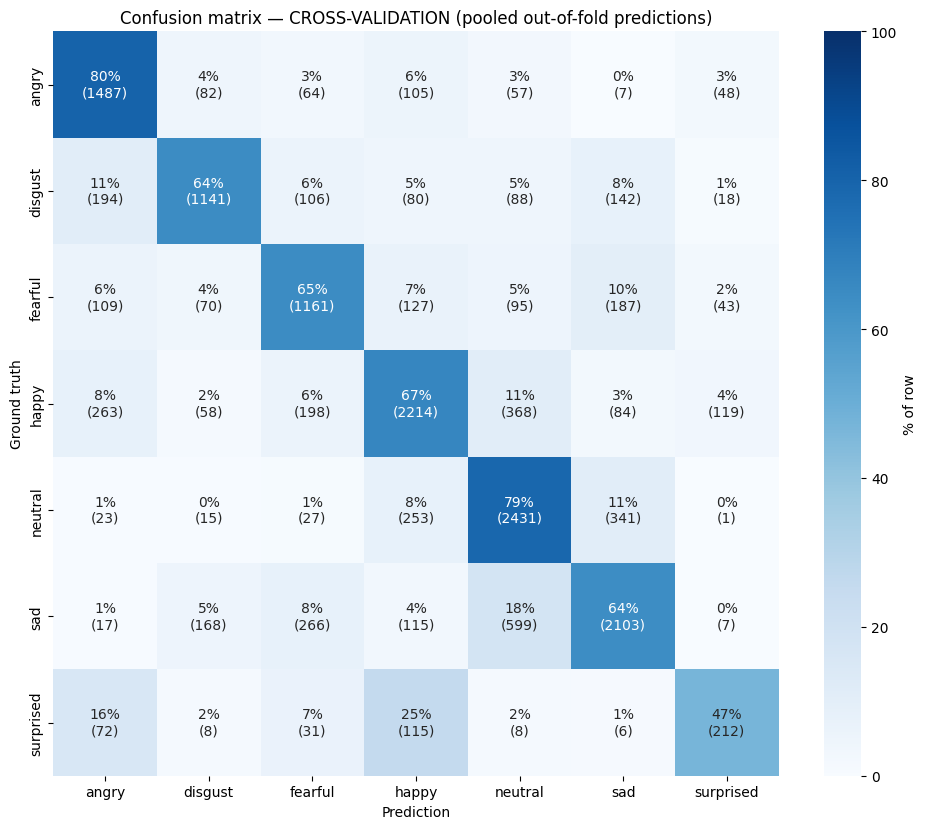


For the paper: the A_principal-tier figure above (pooled
predictions over the 5 folds), together with the
across-fold standard deviation from the table above. The
bootstrap confidence interval and the across-fold standard
deviation measure two different things; reporting both is
more informative than reporting only one.
LINEAR PROBE ON THE FUSED REPRESENTATION
  corpus  decoded at 83.51%  (chance 16.67%)
  emotion decoded at 63.26%  (chance 14.29%)

STEP baselines  |  remaining 5.24 h  |  estimated cost 0.00 h
BASELINES on the same test set (n=2248)
                           systeme  UAR_A_principal  UAR_B_actes  UAR_C_tout  WA_global
                    majority class            14.29        14.29       14.29      21.22
                     duration only            16.33        17.14       21.79      25.18
75-D prosody + logistic regression            42.13        41.28       48.09      45.20

chance = 14.29% UAR (7 classes)

STEP leave_one_corpus_out  |  remaining 5.22 h  |  estima

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

    UAR 35.53% [33.64, 37.29]

--- LOCO: EMODB held out (train 14567, test 454) ---


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

    UAR 65.36% [59.46, 70.50]

--- LOCO: MLEnd held out (train 11128, test 4510) ---


...

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

 pli  n_test    WA   UAR  macro_F1  UAR_A_principal  epoques  minutes  graine
   0    3223 71.21 68.05     68.17            69.55       18     31.4     123
   1    3123 66.70 64.78     63.49            66.14       10     17.5     123
   0    3223 68.85 64.03     65.21            66.99       11     19.2     456
   1    3123 69.71 67.74     67.06            71.22       18     31.7     456

PLAN FINISHED in 6.90 h
                  etape            statut  minutes
           cv_principal              done    135.4
              baselines              done      1.4
   leave_one_corpus_out              done    124.9
              ablations deferred (budget)      NaN
    inflation_protocole              done     49.2
             loso_emodb deferred (budget)      NaN
graines_supplementaires              done    103.3

NOT COMPUTED: ['ablations', 'loso_emodb']
Do NOT present these as an empty result in the paper: either
rerun a session to compute them, or remove the corresponding
table.


In [19]:
RESULTS = {}          # everything Section 20 exports


def _seconds_per_epoch():
    """Estimated from runs completed so far. None until something has run."""
    if not RUN_LOG:
        return None
    tot_s = sum(r["seconds"] for r in RUN_LOG)
    tot_e = sum(max(1, r["epochs"]) for r in RUN_LOG)
    return tot_s / max(1, tot_e)


def _estimate(n_runs, epochs):
    spe = _seconds_per_epoch()
    if spe is None:
        return None
    return n_runs * epochs * spe


def _fmt(seconds):
    return "unknown" if seconds is None else f"{seconds/3600:.2f} h"


# --------------------------------------------------------------------------- #
# The experiment plan. `cout` = (number of training runs, epochs per run).
# --------------------------------------------------------------------------- #
def _etape_cv():
    tags, folds = run_cv(verbose=True)
    rep = cv_report(tags, folds)
    RESULTS["cv_tags"] = tags
    RESULTS["cv_folds"] = folds
    RESULTS["cv_report"] = rep
    RESULTS["cv_pack"] = rep["pack"]
    sonde = corpus_probe(load_run(tags[0]))
    RESULTS["corpus_probe"] = sonde
    return rep


def _etape_baselines():
    t, _ = baselines(SPLIT)
    RESULTS["baselines"] = t
    return t


def _etape_loco():
    RESULTS["loco"] = run_loco()
    return RESULTS["loco"]


def _etape_ablations():
    tags = run_ablations(SPLIT)
    RESULTS["ablation_tags"] = tags
    RESULTS["ablations"] = compare_ablations(tags)
    return RESULTS["ablations"]


def _etape_inflation():
    RESULTS["inflation"] = run_protocol_inflation()
    return RESULTS["inflation"]


def _etape_loso():
    t, pooled = run_loso("EMODB")
    RESULTS["loso_emodb"] = t
    RESULTS["loso_pooled"] = pooled
    return t


def _etape_graines():
    rows = []
    for s in [g for g in CFG["seeds"] if g != CFG["seed"]]:
        tags, folds = run_cv(seed=s, verbose=False, max_folds=2)
        folds["graine"] = s
        rows.append(folds)
    if rows:
        RESULTS["graines"] = pd.concat(rows, ignore_index=True)
        print(RESULTS["graines"].to_string(index=False))
    return RESULTS.get("graines")


PLAN = [
    dict(nom="cv_principal", priorite=1, fn=_etape_cv,
         n_runs=CFG["n_folds"], epochs=CFG["epochs"],
         debloque="headline figure, dispersion, per-corpus tables"),
    dict(nom="baselines", priorite=1, fn=_etape_baselines,
         n_runs=0, epochs=0,
         debloque="reference point (majority class, duration, prosody)"),
    dict(nom="leave_one_corpus_out", priorite=2, fn=_etape_loco,
         n_runs=df["corpus"].nunique(), epochs=CFG["epochs_experiment"],
         debloque="cross-corpus generalization, honest TESS figure"),
    dict(nom="ablations", priorite=2, fn=_etape_ablations,
         n_runs=len(ABLATION_ORDER) + 1, epochs=CFG["epochs_experiment"],
         debloque="spectral branch, loss weighting, fusion"),
    dict(nom="inflation_protocole", priorite=3, fn=_etape_inflation,
         n_runs=2, epochs=CFG["epochs_experiment"],
         debloque="the central methodological comparison"),
    dict(nom="loso_emodb", priorite=4, fn=_etape_loso,
         n_runs=10, epochs=CFG["epochs_experiment"],
         debloque="comparability with the EMODB literature"),
    dict(nom="graines_supplementaires", priorite=5, fn=_etape_graines,
         n_runs=2 * (len(CFG["seeds"]) - 1), epochs=CFG["epochs"],
         debloque="initialization variance"),
]


def run_plan(budget_hours=None, only=None, verbose=True):
    """Executes the plan in ascending priority order, under a measured budget.

    Only commits to a step if its estimated cost fits in the remaining time.
    The estimate is calibrated from runs already completed, so the first step
    starts with no estimate available; this is intentional, since
    cross-validation is the paper's headline figure and always runs first
    regardless.
    """
    budget_s = (budget_hours or CFG["budget_hours"]) * 3600
    t0 = time.time()
    etapes = sorted(PLAN, key=lambda e: e["priorite"])
    if only:
        etapes = [e for e in etapes if e["nom"] in only]
    journal = []

    print("=" * 74)
    print(f"EXPERIMENT PLAN — budget {budget_s/3600:.2f} h, "
          f"preset {CFG['preset']}")
    print("=" * 74)
    for e in etapes:
        print(f"  [{e['priorite']}] {e['nom']:<24s} "
              f"{e['n_runs']:>2d} runs x {e['epochs']} epochs  "
              f"-> {e['debloque']}")

    for e in etapes:
        reste = budget_s - (time.time() - t0)
        cout = _estimate(e["n_runs"], e["epochs"])
        print("\n" + "=" * 74)
        print(f"STEP {e['nom']}  |  remaining {_fmt(reste)}  |  "
              f"estimated cost {_fmt(cout)}")
        print("=" * 74)
        if reste <= 0:
            print("budget exhausted -> step not started.")
            journal.append(dict(etape=e["nom"], statut="budget exhausted"))
            continue
        if cout is not None and cout > reste and e["n_runs"] > 0:
            print("estimated cost exceeds remaining time -> step not started.")
            print("Rerun the notebook later: `fit` resumes runs already")
            print("computed, so nothing already finished will be redone.")
            journal.append(dict(etape=e["nom"], statut="deferred (budget)"))
            continue
        try:
            t1 = time.time()
            e["fn"]()
            journal.append(dict(etape=e["nom"], statut="done",
                                minutes=round((time.time() - t1) / 60, 1)))
        except Exception as exc:
            import traceback
            print(f"\n!! STEP {e['nom']} FAILED: {type(exc).__name__}: {exc}")
            traceback.print_exc()
            print("!! The plan continues: steps already completed are kept.")
            journal.append(dict(etape=e["nom"], statut=f"failed ({type(exc).__name__})"))

    j = pd.DataFrame(journal)
    RESULTS["journal"] = j
    print("\n" + "=" * 74)
    print(f"PLAN FINISHED in {(time.time()-t0)/3600:.2f} h")
    print("=" * 74)
    print(j.to_string(index=False))
    manquantes = j[j["statut"] != "done"]["etape"].tolist()
    if manquantes:
        print(f"\nNOT COMPUTED: {manquantes}")
        print("Do NOT present these as an empty result in the paper: either")
        print("rerun a session to compute them, or remove the corresponding")
        print("table.")
    json.dump(journal, open(Path(CFG["out_dir"]) / "journal.json", "w"),
              indent=2, ensure_ascii=False)
    return j


JOURNAL = run_plan()


## 20. Export of the paper's tables

The eight result tables, in CSV and LaTeX (`booktabs`) format, written to
`/kaggle/working/runs/tables/`. A table whose underlying experiment did not
run is not exported empty; it is flagged as missing instead.

The tables written to the `tables/` directory are the ones intended for
direct inclusion in the paper.


In [20]:
TABLES = Path(CFG["out_dir"]) / "tables"
TABLES.mkdir(parents=True, exist_ok=True)


def _to_latex(t, nom, caption, label, float_fmt="%.2f"):
    t = t.copy()
    for c in t.columns:
        if not pd.api.types.is_numeric_dtype(t[c]):
            t[c] = t[c].astype(str).str.replace("_", r"\_", regex=False)
    t.columns = [str(c).replace("_", r"\_") for c in t.columns]
    body = t.to_latex(index=False, escape=False, float_format=float_fmt,
                      column_format="l" + "r" * (len(t.columns) - 1))
    body = body.replace(r"\toprule", r"\toprule").replace("NaN", "--")
    tex = (f"% generated by the notebook\n"
           f"\\begin{{table}}[t]\n\\centering\n\\small\n"
           f"\\caption{{{caption}}}\n\\label{{{label}}}\n{body}\\end{{table}}\n")
    (TABLES / f"{nom}.tex").write_text(tex)
    t.to_csv(TABLES / f"{nom}.csv", index=False)
    return tex


def export_tables(verbose=True):
    faites, manquantes = [], []

    def _try(nom, obj, caption, label, prep=lambda x: x):
        if obj is None or (hasattr(obj, "empty") and obj.empty):
            manquantes.append(nom); return
        try:
            _to_latex(prep(obj), nom, caption, label)
            faites.append(nom)
        except Exception as e:
            print(f"  !! {nom}: {type(e).__name__}: {e}")
            manquantes.append(nom)

    # T1 — corpus
    t1 = (df.groupby("corpus")
            .agg(enonces=("utt_id", "size"), locuteurs=("speaker", "nunique"),
                 phrases=("sentence", "nunique"),
                 classes=("emotion", "nunique"))
            .reset_index())
    _try("t1_corpus", t1,
         "Corpora retained after applying the class policies and the "
         "MLEnd per-speaker cap.", "tab:corpus")

    # T2 — tier composition
    _try("t2_composition", composition,
         "Composition of the three result tiers. Tier A excludes MLEnd "
         "(labels rest on an intonation--emotion hypothesis) and corpora "
         "with fewer than four speakers.", "tab:composition")

    # T3 — primary result
    rep = RESULTS.get("cv_report")
    _try("t3_principal", rep["tiers"] if rep else None,
         "Primary result, 5-fold speaker-based cross-validation, pooled "
         "out-of-fold predictions. 95\\% intervals bootstrapped over "
         "speakers.", "tab:principal",
         prep=lambda t: t.drop(columns=["composition"]))

    # T3b — across-fold dispersion
    _try("t3b_plis", RESULTS.get("cv_folds"),
         "Dispersion across folds. The standard deviation measures "
         "variability due to speakers.", "tab:plis")

    # T4 — per corpus
    _try("t4_par_corpus", rep["per_corpus"] if rep else None,
         "Results per corpus. \\texttt{macro\\_F1} is restricted to the "
         "classes the corpus provides; \\texttt{pred\\_hors\\_classes} gives "
         "the share of predictions falling on an emotion absent from the "
         "corpus.", "tab:corpus_res")

    # T5 — per class
    _try("t5_par_classe", rep["per_class"] if rep else None,
         "Precision, recall and F1 per class. The recall--precision gap is "
         "the cost of effective-number class weighting and UAR-based model "
         "selection.", "tab:classes")

    # T6 — ablations
    _try("t6_ablations", RESULTS.get("ablations"),
         "Ablations on the same split. Paired McNemar test, "
         "Holm-Bonferroni correction. A significant negative "
         "$\\Delta$UAR indicates the removed component was contributing.",
         "tab:ablations")

    # T7 — LOCO
    _try("t7_loco", RESULTS.get("loco"),
         "Leave-one-corpus-out. The model never heard the speakers from "
         "the held-out corpus.", "tab:loco")

    # T8 — inflation
    _try("t8_inflation", RESULTS.get("inflation"),
         "Inflation from speaker leakage: random split versus "
         "speaker-based split, with identical corpora, model, and budget.",
         "tab:inflation")

    # T9 — baselines
    _try("t9_baselines", RESULTS.get("baselines"),
         "Trivial reference systems evaluated on the same test set.",
         "tab:baselines")

    # T10 — LOSO EMODB
    _try("t10_loso", RESULTS.get("loso_emodb"),
         "Leave-one-speaker-out on EMODB, with the other corpora kept "
         "in training.", "tab:loso")

    # T11 — decision rule
    _try("t11_decision", rep["sweep"] if rep else None,
         "Logit adjustment sweep. $\\tau=0$ corresponds to the raw argmax.",
         "tab:decision")

    if verbose:
        print("=" * 74)
        print(f"TABLES EXPORTED to {TABLES}")
        print("=" * 74)
        for n in faites:
            print(f"  OK        {n}.tex / {n}.csv")
        for n in manquantes:
            print(f"  MISSING   {n}  (experiment not run)")
        if manquantes:
            print("\nA missing table is not the same as an empty table. Either")
            print("rerun the session to compute it, or remove the table AND")
            print("the corresponding claim from the manuscript.")
    return faites, manquantes


_faites, _manquantes = export_tables()

# quick-glance summary
print("\n" + "=" * 74)
print("SUMMARY")
print("=" * 74)
if "cv_report" in RESULTS:
    t = RESULTS["cv_report"]["tiers"]
    a = t[t["niveau"] == "A_principal"]
    if len(a):
        r = a.iloc[0]
        print(f"HEADLINE FIGURE FOR THE PAPER")
        print(f"  tier A (excludes MLEnd, excludes corpora with < 4 speakers), "
              f"n={int(r['n'])}, {int(r['n_locuteurs'])} speakers")
        print(f"  WA {r['WA']:.2f}%  |  UAR {r['UAR']:.2f}% "
              f"[{r['UAR_lo']:.2f}, {r['UAR_hi']:.2f}]  |  "
              f"macro-F1 {r['macro_F1']:.2f}%")
        if "cv_folds" in RESULTS:
            f = RESULTS["cv_folds"]["UAR_A_principal"]
            print(f"  across-fold dispersion: ± {f.std():.2f} points of UAR "
                  f"over {len(f)} folds")
else:
    print("Cross-validation did not run: no headline figure available.")


TABLES EXPORTED to /kaggle/working/runs/tables
  OK        t1_corpus.tex / t1_corpus.csv
  OK        t2_composition.tex / t2_composition.csv
  OK        t3_principal.tex / t3_principal.csv
  OK        t3b_plis.tex / t3b_plis.csv
  OK        t4_par_corpus.tex / t4_par_corpus.csv
  OK        t5_par_classe.tex / t5_par_classe.csv
  OK        t7_loco.tex / t7_loco.csv
  OK        t8_inflation.tex / t8_inflation.csv
  OK        t9_baselines.tex / t9_baselines.csv
  OK        t11_decision.tex / t11_decision.csv
  MISSING   t6_ablations  (experiment not run)
  MISSING   t10_loso  (experiment not run)

A missing table is not the same as an empty table. Either
rerun the session to compute it, or remove the table AND
the corresponding claim from the manuscript.

SUMMARY
HEADLINE FIGURE FOR THE PAPER
  tier A (excludes MLEnd, excludes corpora with < 4 speakers), n=9624, 129 speakers
  WA 68.23%  |  UAR 68.03% [64.95, 70.91]  |  macro-F1 67.17%
  across-fold dispersion: ± 3.55 points of UAR over 5

## 21. Reporting checklist for the paper

Each point corresponds to a number this notebook produces. Nothing should be
reported without its corresponding table in `runs/tables/`.

### Corpus section
- Six corpora, counts verified against official values, Kaggle mount
  duplicates removed, RAVDESS singing clips excluded. **Table 1.**
- MLEnd: state that the corpus contains **numerals spoken with four
  intonation styles**, that the intonation → emotion mapping is an
  author-defined hypothesis, and that each speaker's contribution is capped
  by (speaker, class).
- Note the exclusion of the *calm* class, with the reason.

### Protocol section
- **5-fold speaker-based cross-validation.** State that each utterance is
  predicted once by a model that never heard it during training, which makes
  per-corpus results individually interpretable.
- **The TESS handling, stated explicitly.** Two speakers, so no
  three-way speaker-disjoint split is possible; the test set is the
  intersection of a held-out speaker and a held-out group of sentences;
  incompatible utterances are dropped and their count is reported; validation
  shares the training speaker, which affects only checkpoint selection, not
  the reported test metric.
- **Three result tiers with their composition. Table 2.** Tier A opens the
  Results section.
- Repeat-padding, justified by the duration audit.

### Results section
- **Headline figure: tier A, 95% speaker-bootstrapped CI, plus the
  across-fold standard deviation. Tables 3 and 3b.** These measure different
  things — report both.
- Per-corpus table, with the number of classes actually present and the
  out-of-inventory prediction rate. **Table 4.** Do not cite `macro_F1_all`
  as a headline number: it reflects classes absent from a given corpus.
- UAR **and** macro-F1 reported side by side.
- **Baselines. Table 9.** Without them, the headline figure has no reference
  point.

### Analysis section
- **Ablations with paired tests and Holm correction. Table 6.** If `no_spec`
  is not significant and `spec_aug_fixed` does not raise the score, state
  that the spectral branch does not show a measurable contribution at this
  budget — a reportable finding in its own right.
- **Leave-one-corpus-out. Table 7.** Compare the cross-corpus TESS figure
  against the intra-protocol TESS figure: the gap measures what the
  intra-corpus score was actually worth.
- **Protocol inflation. Table 8.** State it as a difference between
  protocols, never as a statistical test: the two protocols do not share a
  test set.
- WavLM layer weights, fusion gate weights broken down by corpus and by
  class.
- **Decision rule. Table 11.** The recall skew on `fearful` is a chosen
  operating point, not a defect: report the full curve and the operating
  point used.

### Limitations section
- Corpus probe: if the representation identifies the corpus above 85%,
  state this explicitly, and note a corpus adversary (GRL) as future work.
- TESS remains two voices. Even with a disjoint test set, a two-speaker
  corpus does not measure speaker generalization broadly.
- MLEnd's labels remain a stated hypothesis.
- A single seed per fold, unless the `graines_supplementaires` step has run.

### What to avoid
Do not report a number whose underlying experiment did not run. The plan's
log (`runs/journal.json`) records what was actually computed. An empty cell
in a table is honest; a `NaN` presented as a standard deviation is not.


---

# Efficient WavLM Training and Fine-Tuning Extension

The cells above define the full base pipeline — `df`, `CFG`, `cache_key`,
`TAG`, `EmotionDataset`, `ABLATIONS`, `run_cv`, `run_loco`, `run_loso`,
`FocalLoss`, `speaker_cv_folds`, `loso_folds`, `make_split`, etc. are all
available in the kernel from this point on — no other session or file is
needed.

What follows:
0. Diagnostic: verifies directly whether `CFG`'s `unfreeze_last_n` /
   `encoder_lr` are actually wired through in `fit()`, rather than assuming
   they are.
1. Caching of all 13 WavLM layers (`microsoft/wavlm-base-plus`, frozen) —
   the efficiency measure that allows the experiments deferred by the
   budget scheduler in Section 19 above (`ablations` and `loso_emodb`,
   marked *deferred (budget)*) to complete.
2. An efficient tri-branch model, using the same ablation configurations as
   Section 15 above (`ABLATIONS`/`ABLATION_ORDER` reused as-is).
3. Training plus an execution plan targeted at the experiments that were not
   yet completed (ablations, LOSO on EMODB).
4. Statistics (McNemar + Holm) and export of the paper's remaining tables
   (Tables 6 and 10).
5. Independent WavLM fine-tuning (progressive unfreezing, discriminative
   learning rates) — relevant if Section 0 shows that `unfreeze_last_n` is
   not wired through.
6. Quantitative comparison of the frozen versus fine-tuned encoder (paired
   McNemar test).

All cells below execute automatically (no call is left commented out). To
run only part of this extension (for example, ablations/LOSO first, with
fine-tuning left for a separate session given its cost), insert a
`raise SystemExit` cell just before the section to defer, or comment out the
relevant cells manually.

---


## 0. Diagnostic: are `unfreeze_last_n` / `encoder_lr` wired through?

Compares the number of trainable parameters returned by `fit()`'s model
construction for `unfreeze_last_n=0` versus `unfreeze_last_n=4`. If the count
does not change, the option is not wired through, and Section 5 of this
notebook (independent fine-tuning) is the reliable path for unfreezing the
encoder.


In [21]:
# =============================================================================
# CELL — unfreeze_last_n / encoder_lr wiring diagnostic  @v8-cell
# =============================================================================
def diagnostiquer_unfreeze_last_n():
    """Runs NO training: builds the internal model used by `fit()` (if it
    exposes a `build_model(cfg)` entry point or equivalent) for two values of
    `unfreeze_last_n` and compares the number of trainable parameters. Adjust
    `build_model_fn` below if the actual construction function has a
    different name."""
    candidats = ["build_model", "make_model", "get_model"]
    build_model_fn = next((globals()[n] for n in candidats if n in globals()), None)

    if build_model_fn is None:
        print("!! No standalone model-construction function found "
              f"(looked for: {candidats}).")
        print("!! Fallback: manual inspection. Run this and compare:")
        print(">>> m0 = fit('diag_unfreeze0', SPLIT, dict(CFG, unfreeze_last_n=0, epochs=1), verbose=False)")
        print(">>> m4 = fit('diag_unfreeze4', SPLIT, dict(CFG, unfreeze_last_n=4, epochs=1), verbose=False)")
        print(">>> # then compare the number of parameters with requires_grad=True")
        print(">>> # across the two runs (e.g. via logging added inside fit(),")
        print(">>> # or by timing: genuine fine-tuning should be noticeably")
        print(">>> # slower per epoch than a fully frozen run).")
        return None

    m0 = build_model_fn(dict(CFG, unfreeze_last_n=0))
    m4 = build_model_fn(dict(CFG, unfreeze_last_n=4))
    n0 = sum(p.numel() for p in m0.parameters() if p.requires_grad)
    n4 = sum(p.numel() for p in m4.parameters() if p.requires_grad)
    print(f"unfreeze_last_n=0: {n0/1e6:.2f} M trainable parameters")
    print(f"unfreeze_last_n=4: {n4/1e6:.2f} M trainable parameters")
    if n4 > n0 * 1.05:
        print("OK: the parameter count increases as expected -> the option appears wired through.")
    else:
        print("!! NO significant change -> the option is likely NOT wired "
              "through inside fit(). Use Section 5 (independent fine-tuning).")
    return n0, n4

diagnostiquer_unfreeze_last_n()


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

parameters: 100.2 M total | 5.8 M trainable (5.8%)


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

parameters: 100.2 M total | 34.1 M trainable (34.1%)
unfreeze_last_n=0: 5.78 M trainable parameters
unfreeze_last_n=4: 34.14 M trainable parameters
OK: the parameter count increases as expected -> the option appears wired through.


(5782100, 34135716)

## 1. Caching all 13 WavLM layers (simplified version, no masking)

Since all waveforms are already fixed to length `MAX_LEN` (via `fit_length`
above), a batch is a plain `(B, MAX_LEN)` tensor with no padding or masking
to handle.


In [22]:
# =============================================================================
# CELL — Simplified WavLM cache (fixed-length waveforms)              @v8-cell
# =============================================================================
from transformers import AutoModel

assert "cache_key" in globals() and "TAG" in globals(), \
    "run the base pipeline cells above in this session first (cache_key/TAG required)"

WAVLM_NAME = CFG.get("wavlm_name", "microsoft/wavlm-base-plus")
N_LAYERS = 13
HID = 768
WAVLM_LAYER_CACHE = Path(CFG["cache_dir"]) / "wavlm_layers"
WAVLM_LAYER_CACHE.mkdir(parents=True, exist_ok=True)


def _wavlm_cache_path(row_id):
    return WAVLM_LAYER_CACHE / f"{row_id}.npy"


class _FixedLenWaveformDataset(Dataset):
    """Loads the waveform already cached by the base pipeline
    (`cache_key(path, TAG + "_w")`), at the fixed length MAX_LEN."""
    def __init__(self, sub_df):
        self.rows = sub_df.reset_index(drop=True)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows.iloc[i]
        w = np.load(cache_key(r["path"], TAG + "_w"))
        return int(r["row"]), torch.from_numpy(w)


@torch.no_grad()
def extract_wavlm_layers_cache(df, model_name=WAVLM_NAME, batch_size=16, verbose=True):
    """Fills WAVLM_LAYER_CACHE with one .npy (13, 2*H) file per utterance,
    indexed by `row["row"]` (the stable positional identifier defined
    earlier). Fixed length means no custom collate_fn is required."""
    todo_mask = ~df["row"].apply(lambda r: _wavlm_cache_path(r).exists())
    todo = df[todo_mask]
    if len(todo) == 0:
        print(f"WavLM cache already complete ({len(df)} utterances).")
        return 0
    if verbose:
        print(f"extracting WavLM features for {len(todo)}/{len(df)} missing utterances...")

    model = AutoModel.from_pretrained(model_name, output_hidden_states=True)
    model.eval().to(DEVICE)
    if DEVICE.type == "cuda":
        model = model.half()

    dl = DataLoader(_FixedLenWaveformDataset(todo), batch_size=batch_size,
                    shuffle=False, num_workers=2)
    t0, n_done = time.time(), 0
    for ids, wavs in dl:
        wavs = wavs.to(DEVICE)
        if DEVICE.type == "cuda":
            wavs = wavs.half()
        out = model(input_values=wavs)                      # no attention_mask needed: fixed length
        hs = torch.stack(out.hidden_states, dim=1)           # (B, 13, T', H)
        mean = hs.mean(dim=2)                                 # (B, 13, H)
        std = hs.std(dim=2)
        pooled = torch.cat([mean, std], dim=-1).float().cpu().numpy()  # (B, 13, 2H)
        for row_id, vec in zip(ids, pooled):
            np.save(_wavlm_cache_path(int(row_id)), vec.astype(np.float32))
        n_done += len(ids)
        if verbose and n_done % (batch_size * 20) < batch_size:
            print(f"  {n_done}/{len(todo)} ({time.time()-t0:.0f}s)")

    del model; torch.cuda.empty_cache()
    if verbose:
        print(f"WavLM cache complete: {n_done} utterances in {(time.time()-t0)/60:.1f} min")
    return n_done


def load_wavlm_cache(row_id):
    return np.load(_wavlm_cache_path(int(row_id)))   # (13, 2*768)

extract_wavlm_layers_cache(df)


extracting WavLM features for 16933/16933 missing utterances...


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

  320/16933 (2s)
  640/16933 (4s)
  960/16933 (6s)
  1280/16933 (8s)
  1600/16933 (10s)
  1920/16933 (11s)
  2240/16933 (13s)
  2560/16933 (15s)
  2880/16933 (17s)
  3200/16933 (19s)
  3520/16933 (21s)
  3840/16933 (23s)
  4160/16933 (25s)
  4480/16933 (27s)
  4800/16933 (30s)
  5120/16933 (32s)
  5440/16933 (34s)
  5760/16933 (36s)
  6080/16933 (38s)
  6400/16933 (40s)
  6720/16933 (41s)
  7040/16933 (43s)
  7360/16933 (45s)
  7680/16933 (47s)
  8000/16933 (49s)
  8320/16933 (51s)
  8640/16933 (53s)
  8960/16933 (55s)
  9280/16933 (57s)
  9600/16933 (59s)
  9920/16933 (61s)
  10240/16933 (62s)
  10560/16933 (64s)
  10880/16933 (66s)
  11200/16933 (68s)
  11520/16933 (70s)
  11840/16933 (72s)
  12160/16933 (74s)
  12480/16933 (76s)
  12800/16933 (78s)
  13120/16933 (79s)
  13440/16933 (81s)
  13760/16933 (83s)
  14080/16933 (85s)
  14400/16933 (87s)
  14720/16933 (89s)
  15040/16933 (91s)
  15360/16933 (93s)
  15680/16933 (95s)
  16000/16933 (97s)
  16320/16933 (99s)
  16640/16933 (101

16933

## 2. Efficient tri-branch model (branches matching the manuscript)

Reads directly from the columns already cached above: mel-spectrograms via
`cache_key(path, TAG+"_m")` (fixed shape `(301, 128)`) and hand-crafted
features via `cache_key(path, TAG+"_f")` (`75-D`). No separate loading logic
needed.


In [23]:
# =============================================================================
# CELL — Ablation configurations (reused as-is) + model                @v8-cell
# =============================================================================
ABLATIONS = {
    "reference":      {},
    "no_spec":        dict(use_spec=False),
    "spec_aug_fixed": dict(aug_recompute_mel=True),
    "no_feat":        dict(use_feat=False),
    "no_wavlm":       dict(use_wavlm=False),
    "wavlm_only":     dict(use_spec=False, use_feat=False),
    "spec_only":      dict(use_wavlm=False, use_feat=False),
    "feat_only":      dict(use_wavlm=False, use_spec=False),
    "concat_fusion":  dict(fusion="concat"),
    "last_layer":     dict(weighted_layers=False),
    "plain_ce":       dict(loss="ce"),
}
ABLATION_ORDER = ["no_spec", "spec_aug_fixed", "plain_ce", "no_feat",
                  "no_wavlm", "wavlm_only", "concat_fusion", "last_layer",
                  "feat_only", "spec_only"]


class WavLMBranchCached(nn.Module):
    def __init__(self, out_dim=256, weighted_layers=True):
        super().__init__()
        self.weighted_layers = weighted_layers
        self.layer_logits = nn.Parameter(torch.zeros(N_LAYERS))
        self.proj = nn.Sequential(nn.LayerNorm(2 * HID), nn.Linear(2 * HID, out_dim), nn.GELU())

    def forward(self, cached):                       # (B, 13, 2H)
        w = (torch.softmax(self.layer_logits, dim=0) if self.weighted_layers
             else F.one_hot(torch.tensor(N_LAYERS - 1), N_LAYERS).float().to(cached.device))
        return self.proj((cached * w[None, :, None]).sum(dim=1))


class SpectralBranch(nn.Module):
    """Fixed-shape mel (301, 128) -> (B, 128, 301) for Conv1d.
    `spec_pos_encoding` and `spec_conv_stem` (CFG) are both assumed true, as
    in the published configuration."""
    def __init__(self, n_mels=128, seq_len=301, out_dim=256, n_layers=4, n_heads=8):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_mels, 128, 3, padding=1), nn.GELU(),
            nn.Conv1d(128, out_dim, 3, padding=1), nn.GELU())
        self.pos = nn.Parameter(torch.randn(1, seq_len, out_dim) * 0.02)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=out_dim, nhead=n_heads, dim_feedforward=4 * out_dim,
            activation="gelu", batch_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.query = nn.Parameter(torch.randn(1, 1, out_dim))

    def forward(self, mel):                           # mel: (B, 301, 128) as cached
        x = self.conv(mel.transpose(1, 2)).transpose(1, 2)   # (B, 301, out_dim)
        x = x + self.pos[:, :x.size(1)]
        x = self.encoder(x)
        q = self.query.expand(x.size(0), -1, -1)
        attn = torch.softmax((q @ x.transpose(1, 2)) / math.sqrt(x.size(-1)), dim=-1)
        return (attn @ x).squeeze(1)


class FeatureBranch(nn.Module):
    def __init__(self, in_dim=75, out_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256), nn.LayerNorm(256), nn.GELU(),
            nn.Linear(256, out_dim), nn.LayerNorm(out_dim), nn.GELU())

    def forward(self, feat):
        return self.net(feat)


class GatedFusion(nn.Module):
    def __init__(self, n_branches, dim=256, mode="gated"):
        super().__init__()
        self.mode = mode
        self.gate = nn.Linear(n_branches * dim, n_branches)

    def forward(self, branches):
        x = torch.cat(branches, dim=-1)
        if self.mode == "concat":
            return x
        g = torch.softmax(self.gate(x), dim=-1)
        return torch.cat([b * g[:, i:i + 1] for i, b in enumerate(branches)], dim=-1)


class TriModalEfficaceNet(nn.Module):
    def __init__(self, n_classes, cfg=None):
        super().__init__()
        cfg = cfg or {}
        self.use_wavlm = cfg.get("use_wavlm", True)
        self.use_spec = cfg.get("use_spec", True)
        self.use_feat = cfg.get("use_feat", True)
        assert self.use_wavlm or self.use_spec or self.use_feat
        dim = 256
        if self.use_wavlm:
            self.wavlm = WavLMBranchCached(dim, cfg.get("weighted_layers", True))
        if self.use_spec:
            self.spectral = SpectralBranch(out_dim=dim)
        if self.use_feat:
            self.feat = FeatureBranch(out_dim=dim)
        n_b = sum([self.use_wavlm, self.use_spec, self.use_feat])
        self.fusion = GatedFusion(n_b, dim, cfg.get("fusion", "gated"))
        self.head = nn.Sequential(
            nn.LayerNorm(n_b * dim), nn.GELU(), nn.Dropout(CFG.get("dropout", 0.3)),
            nn.Linear(n_b * dim, 256), nn.GELU(), nn.Linear(256, n_classes))

    def forward(self, wavlm_cached=None, mel=None, feat=None):
        branches = []
        if self.use_wavlm:
            branches.append(self.wavlm(wavlm_cached))
        if self.use_spec:
            branches.append(self.spectral(mel))
        if self.use_feat:
            branches.append(self.feat(feat))
        return self.head(self.fusion(branches))


def build_loss_v8(cfg, class_weights=None):
    ls = cfg.get("label_smoothing", CFG.get("label_smoothing", 0.05))
    gamma = cfg.get("focal_gamma", CFG.get("focal_gamma", 2.0))
    if cfg.get("loss") == "ce":
        return nn.CrossEntropyLoss(weight=class_weights, label_smoothing=ls)
    if "FocalLoss" in globals():           # class already defined above
        try:
            return FocalLoss(gamma=gamma, weight=class_weights, ls=ls)
        except TypeError:
            pass
    class _FocalCE(nn.Module):
        def __init__(self):
            super().__init__()
            self.has_w = class_weights is not None
            self.register_buffer("w", class_weights if class_weights is not None else torch.tensor(1.0))
        def forward(self, logits, target):
            logp = F.log_softmax(logits, -1)
            n = logits.size(-1)
            t = torch.full_like(logp, ls / (n - 1))
            t.scatter_(1, target.unsqueeze(1), 1 - ls)
            loss = -(t * logp).sum(-1)
            pt = logp.gather(1, target.unsqueeze(1)).squeeze(1).exp()
            loss = ((1 - pt) ** gamma) * loss
            if self.has_w:
                loss = loss * self.w[target]
            return loss.mean()
    return _FocalCE()

print(f"{len(ABLATIONS)} ablation configurations ready "
      f"({len(ABLATION_ORDER)} variants + reference).")


11 ablation configurations ready (10 variants + reference).


## 3. Efficient training + execution plan (ablations + LOSO)

Uses `df.iloc[indices]` directly, the same way `baselines()` does above
(splits are arrays of positions, not sub-DataFrames).


In [24]:
# =============================================================================
# CELL — Efficient training (I/O matching df["row"]/cache_key)         @v8-cell
# =============================================================================
class TriModalDatasetCached(Dataset):
    """`indices`: positions in `df` (as with `split["train"]`, etc., see
    `baselines()` above). Reads mel/feat via cache_key (already produced by
    the base pipeline) and the WavLM embedding via load_wavlm_cache."""
    def __init__(self, df, indices):
        self.rows = df.iloc[indices].reset_index(drop=True)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows.iloc[i]
        wavlm = torch.from_numpy(load_wavlm_cache(r["row"]))
        mel = torch.from_numpy(np.load(cache_key(r["path"], TAG + "_m")))
        feat = torch.from_numpy(np.load(cache_key(r["path"], TAG + "_f")))
        y = int(r["label"])
        return int(r["row"]), wavlm, mel, feat, y


def _loader_v8(df, indices, batch_size, shuffle):
    return DataLoader(TriModalDatasetCached(df, indices), batch_size=batch_size,
                      shuffle=shuffle, num_workers=2)


def entrainer_efficace(tag, split, cfg, epochs=None, patience=None,
                       batch_size=None, verbose=True, force=False):
    """`split`: dict with 'train'/'val'/'test' -> arrays of positions in
    `df` (same convention as run_cv/run_loco/baselines above).

    Uses a warmup + cosine-decay learning-rate schedule (CFG["warmup_ratio"]).
    Applying the full learning rate immediately to a gated fusion layer and
    freshly initialized branch heads can push training toward a poor local
    optimum that early stopping alone cannot recover from; a brief warmup
    period followed by cosine decay avoids this instability."""
    from transformers import get_cosine_schedule_with_warmup
    run_dir = Path(CFG["out_dir"]) / tag
    if (run_dir / "results.json").exists() and not force:
        if verbose:
            print(f"[{tag}] already computed, skipped.")
        return json.load(open(run_dir / "results.json"))
    run_dir.mkdir(parents=True, exist_ok=True)

    epochs = epochs or CFG.get("epochs_experiment", 18)
    patience = patience or max(3, CFG.get("patience", 5) // 2)
    batch_size = batch_size or CFG.get("batch_size", 16)
    n_classes = int(df["label"].nunique())

    model = TriModalEfficaceNet(n_classes, cfg).to(DEVICE)
    y_train = df.iloc[split["train"]]["label"].values
    counts = np.bincount(y_train, minlength=n_classes).astype(np.float64)
    counts[counts == 0] = 1.0
    eff_num = 1.0 - np.power(0.999, counts)
    w = torch.tensor((1.0 - 0.999) / eff_num, dtype=torch.float32, device=DEVICE)
    w = w / w.mean()
    criterion = build_loss_v8(cfg, class_weights=w)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.get("lr", 3e-4),
                            weight_decay=CFG.get("weight_decay", 1e-2))
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

    dl_tr = _loader_v8(df, split["train"], batch_size, True)
    dl_va = _loader_v8(df, split["val"], batch_size, False)

    total_steps = max(1, len(dl_tr) * epochs)
    warmup_steps = int(CFG.get("warmup_ratio", 0.1) * total_steps)
    sched = get_cosine_schedule_with_warmup(opt, warmup_steps, total_steps)

    best_uar, best_state, bad = -1.0, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        for _, wavlm, mel, feat, y in dl_tr:
            wavlm, mel, feat, y = (t.to(DEVICE) for t in (wavlm, mel, feat, y))
            opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
                logits = model(wavlm, mel, feat)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CFG.get("clip_grad", 5.0))
            scaler.step(opt); scaler.update(); sched.step()

        model.eval(); ys, ps = [], []
        with torch.no_grad():
            for _, wavlm, mel, feat, y in dl_va:
                wavlm, mel, feat = (t.to(DEVICE) for t in (wavlm, mel, feat))
                logits = model(wavlm, mel, feat)
                ys.append(y.numpy()); ps.append(logits.argmax(-1).cpu().numpy())
        uar = balanced_accuracy_score(np.concatenate(ys), np.concatenate(ps))
        if verbose:
            print(f"  [{tag}] epoch {ep:02d} | val UAR {100*uar:.2f}% | {time.time()-t0:.0f}s")
        if uar > best_uar:
            best_uar, best_state, bad = uar, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                if verbose:
                    print(f"  [{tag}] early stopping (best val UAR {100*best_uar:.2f}%)")
                break

    model.load_state_dict(best_state)
    dl_te = _loader_v8(df, split["test"], batch_size, False)
    model.eval(); rows_all, ys, ps, logits_all = [], [], [], []
    with torch.no_grad():
        for rows, wavlm, mel, feat, y in dl_te:
            wavlm, mel, feat = (t.to(DEVICE) for t in (wavlm, mel, feat))
            logits = model(wavlm, mel, feat)
            rows_all += [int(r) for r in rows]; ys.append(y.numpy())
            ps.append(logits.argmax(-1).cpu().numpy()); logits_all.append(logits.cpu().numpy())
    y_arr, p_arr = np.concatenate(ys), np.concatenate(ps)
    logits_arr = np.concatenate(logits_all, axis=0)
    dt = time.time() - t0

    np.savez(run_dir / "pack.npz", y=y_arr, p=p_arr, logits=logits_arr, rows=np.array(rows_all))
    sub = df.set_index("row").loc[rows_all, [c for c in ["corpus", "speaker"] if c in df.columns]]
    sub.reset_index().to_csv(run_dir / "sub.csv", index=False)
    json.dump(dict(seconds=dt, epochs_ran=ep), open(run_dir / "results.json", "w"))

    res = dict(tag=tag, uar=float(balanced_accuracy_score(y_arr, p_arr)), seconds=dt, epochs_ran=ep)
    if verbose:
        print(f"[{tag}] TEST UAR {100*res['uar']:.2f}% in {dt/60:.1f} min ({ep} epochs)")
    return res


def load_run_v8(tag):
    run_dir = Path(CFG["out_dir"]) / tag
    pack = np.load(run_dir / "pack.npz")
    sub_path = run_dir / "sub.csv"
    sub = pd.read_csv(sub_path) if sub_path.exists() else None
    return dict(y=pack["y"], p=pack["p"], logits=pack["logits"], rows=pack["rows"], sub=sub)


In [25]:
# =============================================================================
# CELL — Targeted plan: ablations + LOSO only                          @v8-cell
# =============================================================================
def plan_v8(split_reference, loso_folds_iter, budget_hours=6.0, lancer=False):
    """`loso_folds_iter`: iterable of (held_out_speaker, split) for EMODB, in
    the same format consumed by `run_loso` above (e.g.
    `loso_folds(df, corpus="EMODB", seed=CFG["seed"], cross_corpus=True)`)."""
    budget_s = budget_hours * 3600
    t0 = time.time()
    travaux = [("abl_reference", "ablations",
               lambda: entrainer_efficace("abl_reference", split_reference, {}, verbose=False))]
    for nom in ABLATION_ORDER:
        over = ABLATIONS[nom]
        travaux.append((f"abl_{nom}", "ablations",
                        lambda over=over, nom=nom: entrainer_efficace(
                            f"abl_{nom}", split_reference, over, verbose=False)))
    for held, sp in loso_folds_iter:
        tag = f"loso_EMODB_{held}"
        travaux.append((tag, "loso",
                        lambda sp=sp, tag=tag: entrainer_efficace(tag, sp, {}, verbose=False)))

    print("=" * 74)
    print(f"TARGETED PLAN — {len(travaux)} runs, budget {budget_hours:.1f} h")
    print("=" * 74)
    for tag, groupe, _ in travaux:
        fait = (Path(CFG["out_dir"]) / tag / "results.json").exists()
        print(f"  [{groupe:<10s}] {tag:<24s} {'already done' if fait else 'pending'}")
    if not lancer:
        print("\nDry run. Call again with lancer=True to execute.")
        return travaux

    journal = []
    for tag, groupe, fn in travaux:
        if (Path(CFG["out_dir"]) / tag / "results.json").exists():
            journal.append(dict(tag=tag, statut="already done")); continue
        restant = budget_s - (time.time() - t0)
        if restant <= 0:
            print(f"[deferred] {tag} — budget exhausted"); journal.append(dict(tag=tag, statut="deferred")); continue
        print(f"\n--- {tag} [{groupe}] — remaining {restant/3600:.2f} h ---")
        try:
            fn(); journal.append(dict(tag=tag, statut="done"))
        except Exception as e:
            print(f"    !! FAILED {type(e).__name__}: {e}")
            journal.append(dict(tag=tag, statut=f"failed: {type(e).__name__}"))
    jt = pd.DataFrame(journal)
    print(f"\nTARGETED PLAN FINISHED in {(time.time()-t0)/3600:.2f} h")
    print(jt.groupby("statut").size().to_string())
    return jt

if "SPLIT" not in globals():
    print("SPLIT not found in the kernel: rebuilding via make_split(df, CFG['protocol'], CFG['seed']).")
    SPLIT, _, _ = make_split(df, CFG["protocol"], CFG["seed"], verbose=False)
assert "loso_folds" in globals(), \
    "loso_folds not found in the kernel: run the base pipeline cells (Section 17) before this one."

JOURNAL_V8 = plan_v8(SPLIT, loso_folds(df, corpus="EMODB", seed=CFG["seed"],
                                        cross_corpus=True), lancer=True)


TARGETED PLAN — 21 runs, budget 6.0 h
  [ablations ] abl_reference            pending
  [ablations ] abl_no_spec              pending
  [ablations ] abl_spec_aug_fixed       pending
  [ablations ] abl_plain_ce             pending
  [ablations ] abl_no_feat              pending
  [ablations ] abl_no_wavlm             pending
  [ablations ] abl_wavlm_only           pending
  [ablations ] abl_concat_fusion        pending
  [ablations ] abl_last_layer           pending
  [ablations ] abl_feat_only            pending
  [ablations ] abl_spec_only            pending
  [loso      ] loso_EMODB_EMODB_03      pending
  [loso      ] loso_EMODB_EMODB_08      pending
  [loso      ] loso_EMODB_EMODB_09      pending
  [loso      ] loso_EMODB_EMODB_10      pending
  [loso      ] loso_EMODB_EMODB_11      pending
  [loso      ] loso_EMODB_EMODB_12      pending
  [loso      ] loso_EMODB_EMODB_13      pending
  [loso      ] loso_EMODB_EMODB_14      pending
  [loso      ] loso_EMODB_EMODB_15      pending
  

## 4. Statistics (McNemar + Holm) and export of Tables 6 and 10

In [26]:
# =============================================================================
# CELL — Tables 6 (ablations) and 10 (LOSO)                            @v8-cell
# =============================================================================
def _mcnemar_holm(y, preds, reference="reference", alpha=0.05):
    y = np.asarray(y); ref = np.asarray(preds[reference])
    uar_ref = 100 * balanced_accuracy_score(y, ref)
    lignes = []
    for nom, p in preds.items():
        if nom == reference:
            continue
        p = np.asarray(p)
        ok_r, ok_p = (ref == y), (p == y)
        b, c = int((ok_r & ~ok_p).sum()), int((~ok_r & ok_p).sum())
        n = b + c
        pv = 1.0 if n == 0 else float(stats.binomtest(min(b, c), n, 0.5).pvalue)
        lignes.append(dict(variante=nom, UAR=round(100 * balanced_accuracy_score(y, p), 2),
                           delta=round(100 * balanced_accuracy_score(y, p) - uar_ref, 2),
                           b=b, c=c, p_brut=pv))
    t = pd.DataFrame(lignes).sort_values("p_brut").reset_index(drop=True)
    m, courant, ajust = len(t), 0.0, []
    for i, pv in enumerate(t["p_brut"]):
        courant = max(courant, min(1.0, (m - i) * pv)); ajust.append(courant)
    t["p_holm"] = np.round(ajust, 6); t["significatif"] = t["p_holm"] < alpha
    return t


def remplir_table6_ablations():
    if not (Path(CFG["out_dir"]) / "abl_reference" / "results.json").exists():
        print("Table 6: abl_reference not found."); return None
    ref = load_run_v8("abl_reference")
    preds, y, manquantes = {"reference": ref["p"]}, ref["y"], []
    for nom in ABLATION_ORDER:
        tag = f"abl_{nom}"
        if (Path(CFG["out_dir"]) / tag / "results.json").exists():
            cur = load_run_v8(tag)
            if len(cur["rows"]) == len(ref["rows"]) and (cur["rows"] == ref["rows"]).all():
                preds[nom] = cur["p"]
        else:
            manquantes.append(nom)
    cmp_fn = globals().get("table_comparaisons", _mcnemar_holm)
    t = cmp_fn(y, preds, reference="reference")
    print(f"TABLE 6 — reference UAR {100*balanced_accuracy_score(y, ref['p']):.2f}%")
    print(t.to_string(index=False))
    if manquantes:
        print(f"\nStill missing: {manquantes}")
    return t


def remplir_table10_loso(corpus="EMODB"):
    tags = sorted(p.name for p in Path(CFG["out_dir"]).glob(f"loso_{corpus}_*")
                  if (p / "results.json").exists())
    if not tags:
        print(f"Table 10: no completed LOSO {corpus} runs."); return None
    lignes = []
    for tag in tags:
        pack = load_run_v8(tag); y, p = pack["y"], pack["p"]
        lignes.append(dict(locuteur=tag.replace(f"loso_{corpus}_", ""), n_test=len(y),
                           WA=100 * float((y == p).mean()), UAR=100 * balanced_accuracy_score(y, p),
                           macro_F1=100 * f1_score(y, p, average="macro", zero_division=0)))
    t = pd.DataFrame(lignes).round(2)
    print(f"TABLE 10 — LOSO {corpus} ({len(t)} speakers)")
    print(t.to_string(index=False))
    print(f"UAR {t.UAR.mean():.2f} ± {t.UAR.std():.2f}")
    return t


def exporter_tables_v8(table6, table10):
    dest = Path(CFG["out_dir"]) / "tables"; dest.mkdir(parents=True, exist_ok=True)
    for nom, t in [("t6_ablations_final", table6), ("t10_loso_final", table10)]:
        if t is not None and len(t):
            t.to_csv(dest / f"{nom}.csv", index=False)
            print(f"  OK        {nom}.csv")
        else:
            print(f"  MISSING   {nom}")

TABLE6 = remplir_table6_ablations()
TABLE10 = remplir_table10_loso()
exporter_tables_v8(TABLE6, TABLE10)


TABLE 6 — reference UAR 66.36%
      variante   UAR  delta   b   c       p_brut   p_holm  significatif
     spec_only 42.43 -23.93 823 266 1.066816e-66 0.000000          True
     feat_only 45.09 -21.27 661 238 9.965559e-47 0.000000          True
      no_wavlm 40.54 -25.82 631 223 7.523871e-46 0.000000          True
       no_feat 68.94   2.58 152 327 8.933232e-16 0.000000          True
 concat_fusion 66.43   0.07 180 318 6.496896e-10 0.000000          True
    last_layer 64.70  -1.66 204 327 1.053485e-07 0.000001          True
spec_aug_fixed 68.06   1.70 146 233 9.170966e-06 0.000037          True
      plain_ce 64.20  -2.16 229 293 5.773826e-03 0.017321          True
    wavlm_only 63.48  -2.88 236 207 1.833495e-01 0.366699         False
       no_spec 63.33  -3.03 171 197 1.924312e-01 0.366699         False
TABLE 10 — LOSO EMODB (10 speakers)
locuteur  n_test    WA   UAR  macro_F1
EMODB_03      44 81.82 77.38     76.29
EMODB_08      48 70.83 72.17     59.11
EMODB_09      39 69.23 7

## 5. Independent fine-tuning (simplified — no masking)

The convolutional feature extractor stays frozen, with progressive
unfreezing, discriminative learning rates, and a warmup+cosine schedule, but
without masking logic (unnecessary given the fixed-length inputs).


In [27]:
# =============================================================================
# CELL — Independent fine-tuning (simplified)                          @v8-cell
# =============================================================================
from transformers import get_cosine_schedule_with_warmup


class WavLMBranchFinetune(nn.Module):
    def __init__(self, model_name=WAVLM_NAME, out_dim=256, weighted_layers=True):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name, output_hidden_states=True)
        self.hid = self.encoder.config.hidden_size
        self.n_layers = self.encoder.config.num_hidden_layers + 1
        self.weighted_layers = weighted_layers
        self.layer_logits = nn.Parameter(torch.zeros(self.n_layers))
        self.attn_query = nn.Parameter(torch.randn(1, 1, self.hid))
        self.proj = nn.Sequential(nn.LayerNorm(self.hid), nn.Linear(self.hid, out_dim), nn.GELU())
        if hasattr(self.encoder, "feature_extractor"):
            self.encoder.feature_extractor._freeze_parameters()
        self.freeze_all_transformer_layers()

    def freeze_all_transformer_layers(self):
        for p in self.encoder.encoder.layers.parameters():
            p.requires_grad_(False)
        self._n_unfrozen = 0

    def unfreeze_top(self, k):
        layers = self.encoder.encoder.layers; n = len(layers)
        k = max(0, min(k, n))
        for i, layer in enumerate(layers):
            for p in layer.parameters():
                p.requires_grad_(i >= n - k)
        self._n_unfrozen = k

    def forward(self, waveforms):                     # (B, MAX_LEN) — fixed length, no mask needed
        out = self.encoder(input_values=waveforms)
        hs = torch.stack(out.hidden_states, dim=1)      # (B, L, T', H)
        q = self.attn_query.expand(hs.size(0), -1, -1)
        pooled = []
        for l in range(hs.size(1)):
            seq = hs[:, l]
            attn = torch.softmax((q @ seq.transpose(1, 2)) / math.sqrt(seq.size(-1)), dim=-1)
            pooled.append((attn @ seq).squeeze(1))
        pooled = torch.stack(pooled, dim=1)             # (B, L, H)
        w = (torch.softmax(self.layer_logits, dim=0) if self.weighted_layers
             else F.one_hot(torch.tensor(self.n_layers - 1), self.n_layers).float().to(hs.device))
        return self.proj((pooled * w[None, :, None]).sum(dim=1))


class TriModalFinetuneNet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        dim = 256
        self.wavlm = WavLMBranchFinetune(out_dim=dim)
        self.spectral = SpectralBranch(out_dim=dim)
        self.feat = FeatureBranch(out_dim=dim)
        self.fusion = GatedFusion(3, dim, "gated")
        self.head = nn.Sequential(nn.LayerNorm(3 * dim), nn.GELU(), nn.Dropout(0.2),
                                  nn.Linear(3 * dim, 256), nn.GELU(), nn.Linear(256, n_classes))

    def forward(self, wav, mel, feat):
        return self.head(self.fusion([self.wavlm(wav), self.spectral(mel), self.feat(feat)]))


def build_discriminative_optimizer(model, lr_wavlm_top=3e-5, lr_decay=0.9,
                                   lr_new=1e-4, lr_head=3e-4, weight_decay=1e-2):
    groups, layers = [], model.wavlm.encoder.encoder.layers
    n = len(layers)
    for i, layer in enumerate(layers):
        params = [p for p in layer.parameters() if p.requires_grad]
        if params:
            groups.append(dict(params=params, lr=lr_wavlm_top * (lr_decay ** (n - 1 - i)),
                               weight_decay=weight_decay))
    autres = [p for n_, p in model.wavlm.named_parameters()
             if "encoder.encoder.layers" not in n_ and p.requires_grad]
    if autres:
        groups.append(dict(params=autres, lr=lr_new, weight_decay=weight_decay))
    groups.append(dict(params=list(model.spectral.parameters()) + list(model.feat.parameters()),
                       lr=lr_new, weight_decay=weight_decay))
    groups.append(dict(params=list(model.fusion.parameters()) + list(model.head.parameters()),
                       lr=lr_head, weight_decay=weight_decay))
    n_tr = sum(p.numel() for g in groups for p in g["params"])
    n_tot = sum(p.numel() for p in model.parameters())
    print(f"trainable parameters: {n_tr/1e6:.1f} M / {n_tot/1e6:.1f} M ({100*n_tr/n_tot:.1f}%)")
    return torch.optim.AdamW(groups)


def planning_degel(epoch, palier=3, max_couches=12):
    return 0 if epoch <= 2 else min(max_couches, 1 + (epoch - 3) // palier)


class _RawDatasetV8(Dataset):
    def __init__(self, df, indices):
        self.rows = df.iloc[indices].reset_index(drop=True)
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows.iloc[i]
        wav = torch.from_numpy(np.load(cache_key(r["path"], TAG + "_w")))
        mel = torch.from_numpy(np.load(cache_key(r["path"], TAG + "_m")))
        feat = torch.from_numpy(np.load(cache_key(r["path"], TAG + "_f")))
        return int(r["row"]), wav, mel, feat, int(r["label"])


def fit_finetune(tag, split, epochs=12, patience=4, batch_size=8, grad_accum=4,
                 palier_degel=3, max_couches=12, lr_wavlm_top=3e-5, lr_decay=0.9,
                 lr_new=1e-4, lr_head=3e-4, warmup_ratio=0.1, force=False, verbose=True):
    run_dir = Path(CFG["out_dir"]) / tag
    if (run_dir / "results.json").exists() and not force:
        if verbose: print(f"[{tag}] already computed."); return json.load(open(run_dir / "results.json"))
    run_dir.mkdir(parents=True, exist_ok=True)

    n_classes = int(df["label"].nunique())
    model = TriModalFinetuneNet(n_classes).to(DEVICE)
    y_tr = df.iloc[split["train"]]["label"].values
    counts = np.bincount(y_tr, minlength=n_classes).astype(np.float64); counts[counts == 0] = 1.0
    eff_num = 1.0 - np.power(0.999, counts)
    class_w = torch.tensor((1.0 - 0.999) / eff_num, dtype=torch.float32, device=DEVICE)
    class_w = class_w / class_w.mean()
    ls, gamma = CFG.get("label_smoothing", 0.05), CFG.get("focal_gamma", 2.0)
    criterion = (FocalLoss(gamma=gamma, weight=class_w, ls=ls) if "FocalLoss" in globals()
                else nn.CrossEntropyLoss(weight=class_w, label_smoothing=ls))

    dl_tr = DataLoader(_RawDatasetV8(df, split["train"]), batch_size=batch_size, shuffle=True, num_workers=2)
    dl_va = DataLoader(_RawDatasetV8(df, split["val"]), batch_size=batch_size, num_workers=2)
    dl_te = DataLoader(_RawDatasetV8(df, split["test"]), batch_size=batch_size, num_workers=2)

    steps_per_epoch = max(1, len(dl_tr) // grad_accum)
    total_steps = steps_per_epoch * epochs
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))
    model.wavlm.freeze_all_transformer_layers()
    opt = build_discriminative_optimizer(model, lr_wavlm_top, lr_decay, lr_new, lr_head)
    sched = get_cosine_schedule_with_warmup(opt, int(warmup_ratio * total_steps), total_steps)
    n_actuel = 0
    best_uar, best_state, bad = -1.0, None, 0
    t0 = time.time()

    for ep in range(1, epochs + 1):
        n_voulu = planning_degel(ep, palier_degel, max_couches)
        if n_voulu != n_actuel:
            if verbose: print(f"  [{tag}] unfreezing {n_actuel} -> {n_voulu} layers (epoch {ep})")
            model.wavlm.unfreeze_top(n_voulu); n_actuel = n_voulu
            opt = build_discriminative_optimizer(model, lr_wavlm_top, lr_decay, lr_new, lr_head)
            sched = get_cosine_schedule_with_warmup(opt, 0, max(1, steps_per_epoch * (epochs - ep + 1)))

        model.train(); opt.zero_grad()
        for i, (_, wav, mel, feat, y) in enumerate(dl_tr):
            wav, mel, feat, y = (t.to(DEVICE) for t in (wav, mel, feat, y))
            with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
                loss = criterion(model(wav, mel, feat), y) / grad_accum
            scaler.scale(loss).backward()
            if (i + 1) % grad_accum == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()

        model.eval(); ys, ps = [], []
        with torch.no_grad():
            for _, wav, mel, feat, y in dl_va:
                wav, mel, feat = (t.to(DEVICE) for t in (wav, mel, feat))
                logits = model(wav, mel, feat)
                ys.append(y.numpy()); ps.append(logits.argmax(-1).cpu().numpy())
        uar = balanced_accuracy_score(np.concatenate(ys), np.concatenate(ps))
        if verbose:
            print(f"[{tag}] epoch {ep:02d} | unfrozen layers {n_actuel:2d} | val UAR {100*uar:.2f}% "
                  f"| {(time.time()-t0)/60:.1f} min")
        if uar > best_uar:
            best_uar = uar; best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}; bad = 0
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f"[{tag}] early stopping (best val UAR {100*best_uar:.2f}%)")
                break

    model.load_state_dict(best_state)
    model.eval(); rows_all, ys, ps, logits_all = [], [], [], []
    with torch.no_grad():
        for rows, wav, mel, feat, y in dl_te:
            wav, mel, feat = (t.to(DEVICE) for t in (wav, mel, feat))
            logits = model(wav, mel, feat)
            rows_all += [int(r) for r in rows]; ys.append(y.numpy())
            ps.append(logits.argmax(-1).cpu().numpy()); logits_all.append(logits.cpu().numpy())
    y_arr, p_arr = np.concatenate(ys), np.concatenate(ps)
    logits_arr = np.concatenate(logits_all, axis=0)
    dt = time.time() - t0
    np.savez(run_dir / "pack.npz", y=y_arr, p=p_arr, logits=logits_arr, rows=np.array(rows_all))
    sub_cols = [c for c in ["corpus", "speaker"] if c in df.columns]
    if sub_cols:
        df.set_index("row").loc[rows_all, sub_cols].reset_index().to_csv(run_dir / "sub.csv", index=False)
    json.dump(dict(seconds=dt, epochs_ran=ep), open(run_dir / "results.json", "w"))
    res = dict(tag=tag, uar=float(balanced_accuracy_score(y_arr, p_arr)), seconds=dt, epochs_ran=ep)
    if verbose:
        print(f"[{tag}] TEST UAR {100*res['uar']:.2f}% in {dt/60:.1f} min ({ep} epochs, {n_actuel} layers)")
    return res

# SPLIT must exist before being reused here. If it is not defined in this
# session's kernel, it is rebuilt with the same split function used
# throughout this notebook.
if "SPLIT" not in globals():
    print("SPLIT not found in the kernel: rebuilding via make_split(df, CFG['protocol'], CFG['seed']).")
    SPLIT, _, _ = make_split(df, CFG["protocol"], CFG["seed"], verbose=False)

fit_finetune("ft_principal", SPLIT, epochs=12, patience=4)


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

trainable parameters: 9.0 M / 98.3 M (9.1%)
[ft_principal] epoch 01 | unfrozen layers  0 | val UAR 63.82% | 4.5 min
[ft_principal] epoch 02 | unfrozen layers  0 | val UAR 63.88% | 9.0 min
  [ft_principal] unfreezing 0 -> 1 layers (epoch 3)
trainable parameters: 16.1 M / 98.3 M (16.4%)
[ft_principal] epoch 03 | unfrozen layers  1 | val UAR 61.75% | 13.5 min
[ft_principal] epoch 04 | unfrozen layers  1 | val UAR 67.09% | 18.0 min
[ft_principal] epoch 05 | unfrozen layers  1 | val UAR 67.97% | 22.4 min
  [ft_principal] unfreezing 1 -> 2 layers (epoch 6)
trainable parameters: 23.2 M / 98.3 M (23.6%)
[ft_principal] epoch 06 | unfrozen layers  2 | val UAR 68.86% | 26.9 min
[ft_principal] epoch 07 | unfrozen layers  2 | val UAR 68.48% | 31.4 min
[ft_principal] epoch 08 | unfrozen layers  2 | val UAR 69.90% | 35.8 min
  [ft_principal] unfreezing 2 -> 3 layers (epoch 9)
trainable parameters: 30.3 M / 98.3 M (30.8%)
[ft_principal] epoch 09 | unfrozen layers  3 | val UAR 66.44% | 40.3 min
[ft_pri

{'tag': 'ft_principal',
 'uar': 0.6685194824081019,
 'seconds': 3272.711915254593,
 'epochs_ran': 12}

## 6. Quantitative comparison: frozen versus fine-tuned (paired McNemar test)

In [28]:
# =============================================================================
# CELL — Frozen vs. fine-tuned comparison                              @v8-cell
# =============================================================================
def comparer_gele_vs_finetune(split, tag_prefix="ft_compare", **kwargs):
    tag_frozen, tag_ft = f"{tag_prefix}_frozen", f"{tag_prefix}_finetuned"
    entrainer_efficace(tag_frozen, split, {}, verbose=True)
    fit_finetune(tag_ft, split, **kwargs)

    a, b = load_run_v8(tag_frozen), load_run_v8(tag_ft)
    if len(a["rows"]) != len(b["rows"]) or not (a["rows"] == b["rows"]).all():
        print("!! different splits, comparison not possible."); return None
    y = a["y"]
    uar_frozen, uar_ft = 100 * balanced_accuracy_score(y, a["p"]), 100 * balanced_accuracy_score(y, b["p"])
    ok_a, ok_b = (a["p"] == y), (b["p"] == y)
    n_b, n_c = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    n = n_b + n_c
    pv = 1.0 if n == 0 else float(stats.binomtest(min(n_b, n_c), n, 0.5).pvalue)
    t = pd.DataFrame([
        dict(variante="Frozen (reference)", UAR=round(uar_frozen, 2), delta="–", p_McNemar="–"),
        dict(variante="Fine-tuned", UAR=round(uar_ft, 2), delta=round(uar_ft - uar_frozen, 2),
             p_McNemar=round(pv, 4)),
    ])
    print(t.to_string(index=False))
    print(f"b={n_b}, c={n_c}, n={n}, p={pv:.4f} "
          f"({'significant' if pv < 0.05 else 'NOT significant'})")
    return t

if "SPLIT" not in globals():
    print("SPLIT not found in the kernel: rebuilding via make_split(df, CFG['protocol'], CFG['seed']).")
    SPLIT, _, _ = make_split(df, CFG["protocol"], CFG["seed"], verbose=False)

TABLE_FT = comparer_gele_vs_finetune(SPLIT, epochs=12, patience=4)


  [ft_compare_frozen] epoch 01 | val UAR 50.44% | 25s
  [ft_compare_frozen] epoch 02 | val UAR 55.58% | 50s
  [ft_compare_frozen] epoch 03 | val UAR 57.08% | 75s
  [ft_compare_frozen] epoch 04 | val UAR 62.80% | 99s
  [ft_compare_frozen] epoch 05 | val UAR 63.63% | 124s
  [ft_compare_frozen] epoch 06 | val UAR 65.31% | 149s
  [ft_compare_frozen] epoch 07 | val UAR 67.73% | 174s
  [ft_compare_frozen] epoch 08 | val UAR 68.67% | 198s
  [ft_compare_frozen] epoch 09 | val UAR 69.53% | 223s
  [ft_compare_frozen] epoch 10 | val UAR 67.54% | 248s
  [ft_compare_frozen] epoch 11 | val UAR 66.04% | 272s
  [ft_compare_frozen] epoch 12 | val UAR 70.17% | 296s
  [ft_compare_frozen] epoch 13 | val UAR 70.16% | 322s
  [ft_compare_frozen] epoch 14 | val UAR 71.21% | 346s
  [ft_compare_frozen] epoch 15 | val UAR 71.04% | 371s
  [ft_compare_frozen] epoch 16 | val UAR 70.91% | 395s
  [ft_compare_frozen] epoch 17 | val UAR 71.16% | 420s
  [ft_compare_frozen] early stopping (best val UAR 71.21%)
[ft_compar

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

trainable parameters: 9.0 M / 98.3 M (9.1%)
[ft_compare_finetuned] epoch 01 | unfrozen layers  0 | val UAR 55.46% | 4.5 min
[ft_compare_finetuned] epoch 02 | unfrozen layers  0 | val UAR 62.50% | 9.0 min
  [ft_compare_finetuned] unfreezing 0 -> 1 layers (epoch 3)
trainable parameters: 16.1 M / 98.3 M (16.4%)
[ft_compare_finetuned] epoch 03 | unfrozen layers  1 | val UAR 66.87% | 13.5 min
[ft_compare_finetuned] epoch 04 | unfrozen layers  1 | val UAR 64.81% | 18.0 min
[ft_compare_finetuned] epoch 05 | unfrozen layers  1 | val UAR 68.51% | 22.5 min
  [ft_compare_finetuned] unfreezing 1 -> 2 layers (epoch 6)
trainable parameters: 23.2 M / 98.3 M (23.6%)
[ft_compare_finetuned] epoch 06 | unfrozen layers  2 | val UAR 67.78% | 27.0 min
[ft_compare_finetuned] epoch 07 | unfrozen layers  2 | val UAR 70.87% | 31.4 min
[ft_compare_finetuned] epoch 08 | unfrozen layers  2 | val UAR 70.07% | 35.9 min
  [ft_compare_finetuned] unfreezing 2 -> 3 layers (epoch 9)
trainable parameters: 30.3 M / 98.3 M 

---
# V10 — Multi-Model SSL Architecture, 5-Fold OOF Cross-Validation, and Cross-Corpus Generalization

This extension adds a multi-encoder self-supervised architecture with the
following design points:

1. **Same primary protocol as the baseline**: 5-fold speaker-disjoint
   cross-validation, with out-of-fold predictions pooled together.
2. **Two evaluation modes**:
   - `full`: the same protocol as the existing primary result, with A/B/C
     tiers computed after pooling;
   - `A_strict`: training, validation, and test restricted to CREMA-D,
     EMODB, RAVDESS, and SAVEE.
3. **All SSL layers** are cached by default, rather than only the last four.
4. **Consolidated cache**: one matrix file per encoder rather than tens of
   thousands of small `.npy` files.
5. **Latent-space augmentation** for the frozen SSL representations:
   Gaussian noise, feature dropout, and model dropout.
6. **The same loss function as the main pipeline**
   (`class_balanced_weights(..., beta=0.9999)` via `build_criterion`).
7. **Uniquely named V10 classes**, to avoid silently shadowing
   `SpectralBranch`/`FeatureBranch` defined elsewhere in the notebook.
8. **Paired comparison** against the baseline on the same utterances, using
   McNemar's test and a speaker-paired bootstrap on the UAR delta.
9. **V10 LOCO**, to measure whether the multi-encoder architecture actually
   improves generalization to a corpus never seen during training.

> Results in this section are populated only after the corresponding
> experiments have actually been executed.


In [29]:
# =============================================================================
# V10-0 — Configuration
# =============================================================================
from pathlib import Path
import json, time, math, gc, hashlib
from transformers import AutoModel, get_cosine_schedule_with_warmup

V10_CFG = {
    "models": {
        "wavlm": "microsoft/wavlm-base-plus",
        "hubert": "facebook/hubert-base-ls960",
        "wav2vec2": "facebook/wav2vec2-base-960h",
    },

    # All hidden states (embedding + Transformer layers) are cached by
    # default. To reduce cache size, set "selected" instead of "all" and
    # populate selected_layers, e.g. [0, 2, 4, 6, 8, 10, 12].
    "layer_mode": "all",
    "selected_layers": None,
    "cache_dtype": "float16",
    "batch_size_cache": 8,
    "batch_size_train": 24,
    "num_workers": 2,

    "d_model": 256,
    "ssl_attention_heads": 4,
    "ssl_attention_layers": 2,
    "dropout": 0.25,

    # Latent-space augmentations, to compensate for the fact that the SSL
    # encoders are frozen and their outputs cached.
    "latent_noise_std": 0.015,
    "latent_feature_dropout": 0.10,
    "model_dropout": 0.12,

    "epochs": min(24, max(10, int(CFG.get("epochs_experiment", 18)))),
    "patience": 5,
    "lr": 2e-4,
    "weight_decay": 1e-2,
    "warmup_ratio": 0.10,
    "clip_grad": 5.0,
    "grad_accum": 1,
    "loss": "cb_focal",
    "label_smoothing": float(CFG.get("label_smoothing", 0.05)),
    "focal_gamma": float(CFG.get("focal_gamma", 2.0)),

    # Splits stay fixed; only initialization/augmentation vary across seeds.
    "split_seed": int(CFG.get("seed", 42)),
    "train_seeds": tuple(CFG.get("seeds", (42, 123, 456))),
    "n_folds": int(CFG.get("n_folds", 5)),

    # Run All does not automatically trigger the more costly V10 experiments.
    "auto_run": False,
}

V10_CACHE = Path(CFG["cache_dir"]) / "multi_ssl_v10"
V10_CACHE.mkdir(parents=True, exist_ok=True)
V10_OUT = Path(CFG["out_dir"]) / "multi_ssl_v10"
V10_OUT.mkdir(parents=True, exist_ok=True)

V10_VARIANTS = {
    "wavlm_only": {
        "models": ("wavlm",), "use_spec": False, "use_feat": False,
    },
    "wavlm_hubert": {
        "models": ("wavlm", "hubert"), "use_spec": False, "use_feat": False,
    },
    "ssl3_only": {
        "models": ("wavlm", "hubert", "wav2vec2"), "use_spec": False, "use_feat": False,
    },
    "ssl3_plus_spec": {
        "models": ("wavlm", "hubert", "wav2vec2"), "use_spec": True, "use_feat": False,
    },
    "ssl3_plus_feat": {
        "models": ("wavlm", "hubert", "wav2vec2"), "use_spec": False, "use_feat": True,
    },
    "ssl3_full": {
        "models": ("wavlm", "hubert", "wav2vec2"), "use_spec": True, "use_feat": True,
    },
}

print("V10 configured.")
print("Encoders:", V10_CFG["models"])
print("layer_mode:", V10_CFG["layer_mode"])
print("fixed split_seed:", V10_CFG["split_seed"])
print("train_seeds:", V10_CFG["train_seeds"])
print("auto_run:", V10_CFG["auto_run"])


V10 configured.
Encoders: {'wavlm': 'microsoft/wavlm-base-plus', 'hubert': 'facebook/hubert-base-ls960', 'wav2vec2': 'facebook/wav2vec2-base-960h'}
layer_mode: all
fixed split_seed: 42
train_seeds: (42, 123, 456)
auto_run: False


## V10-1. Consolidated SSL cache

Each encoder produces a single memory-mapped array of shape
`[n_utterances, n_layers, 2*hidden_size]`, holding the temporal `mean + std`
for every layer. The cache is indexed by `df["row"]`, so the `full`,
`A_strict`, and LOCO subsets all reuse exactly the same representations.


In [30]:
# =============================================================================
# V10-1 — Consolidated, resumable SSL cache
# =============================================================================
def _manifest_hash_v10(frame):
    h = hashlib.sha1()
    for r, p in zip(frame["row"].astype(int).values, frame["path"].astype(str).values):
        h.update(f"{r}|{p}\n".encode())
    return h.hexdigest()


def _cache_paths_v10(model_key):
    return {
        "matrix": V10_CACHE / f"{model_key}_features.npy",
        "done": V10_CACHE / f"{model_key}_done.npy",
        "meta": V10_CACHE / f"{model_key}_meta.json",
    }


def _resolve_layers_v10(n_hidden_states):
    mode = V10_CFG.get("layer_mode", "all")
    if mode == "all":
        return list(range(int(n_hidden_states)))
    if mode == "selected":
        sel = V10_CFG.get("selected_layers")
        if not sel:
            raise ValueError("selected_layers must be provided when layer_mode='selected'.")
        sel = [int(x) for x in sel]
        bad = [x for x in sel if x < 0 or x >= n_hidden_states]
        if bad:
            raise ValueError(f"Layer indices out of range: {bad}; n_hidden_states={n_hidden_states}")
        return sel
    raise KeyError(f"unknown layer_mode: {mode!r}")


class _WaveRowsV10(Dataset):
    def __init__(self, frame):
        self.rows = frame.reset_index(drop=True)
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows.iloc[i]
        wav = np.load(cache_key(r["path"], TAG + "_w")).astype(np.float32)
        return int(r["row"]), torch.from_numpy(wav)


@torch.no_grad()
def extract_ssl_matrix_v10(model_key, model_name, frame=None, force=False, verbose=True):
    frame = df if frame is None else frame
    # The full V10 cache is always indexed against the global manifest.
    if len(frame) != len(df) or not np.array_equal(frame["row"].values, df["row"].values):
        frame = df
    paths = _cache_paths_v10(model_key)
    manifest_hash = _manifest_hash_v10(frame)

    if verbose:
        print(f"[{model_key}] loading {model_name}")
    model = AutoModel.from_pretrained(model_name, output_hidden_states=True)
    model.eval().to(DEVICE)
    for p in model.parameters():
        p.requires_grad = False

    hidden_size = int(model.config.hidden_size)
    n_hidden_states = int(getattr(model.config, "num_hidden_layers", 12)) + 1
    layer_indices = _resolve_layers_v10(n_hidden_states)
    dtype = np.float16 if V10_CFG["cache_dtype"] == "float16" else np.float32
    shape = (len(frame), len(layer_indices), 2 * hidden_size)

    expected = {
        "model_key": model_key,
        "model_name": model_name,
        "hidden_size": hidden_size,
        "n_hidden_states": n_hidden_states,
        "layer_indices": layer_indices,
        "feature_dim": 2 * hidden_size,
        "dtype": V10_CFG["cache_dtype"],
        "n_rows": int(len(frame)),
        "manifest_hash": manifest_hash,
    }

    recreate = bool(force)
    if paths["meta"].exists() and not recreate:
        old = json.loads(paths["meta"].read_text())
        keys = ["model_name", "hidden_size", "layer_indices", "dtype", "n_rows", "manifest_hash"]
        recreate = any(old.get(k) != expected.get(k) for k in keys)
    elif not paths["meta"].exists():
        recreate = True

    if recreate or not paths["matrix"].exists() or not paths["done"].exists():
        if verbose:
            print(f"[{model_key}] creating consolidated cache {shape}, dtype={dtype}")
        mm = np.lib.format.open_memmap(paths["matrix"], mode="w+", dtype=dtype, shape=shape)
        mm.flush(); del mm
        done = np.zeros(len(frame), dtype=np.bool_)
        np.save(paths["done"], done)
        paths["meta"].write_text(json.dumps(expected, indent=2))
    else:
        done = np.load(paths["done"]).astype(bool)
        mm0 = np.load(paths["matrix"], mmap_mode="r")
        if tuple(mm0.shape) != tuple(shape):
            del mm0
            raise RuntimeError(f"Cache {model_key} incompatible: existing shape != {shape}. Use force=True.")
        del mm0

    done = np.load(paths["done"]).astype(bool)
    missing_pos = np.where(~done)[0]
    if len(missing_pos) == 0:
        if verbose: print(f"[{model_key}] cache complete: {len(frame)} utterances")
        del model
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
        return expected

    work = frame.iloc[missing_pos][["row", "path"]].copy()
    dl = DataLoader(
        _WaveRowsV10(work),
        batch_size=int(V10_CFG["batch_size_cache"]), shuffle=False,
        num_workers=int(V10_CFG["num_workers"]),
        pin_memory=(DEVICE.type == "cuda"),
    )
    mm = np.load(paths["matrix"], mmap_mode="r+")
    t0, n_done = time.time(), 0

    for row_ids, wav in dl:
        wav = wav.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
            out = model(input_values=wav, output_hidden_states=True)
        hs = torch.stack([out.hidden_states[i] for i in layer_indices], dim=1).float()
        mu = hs.mean(dim=2)
        sd = hs.std(dim=2, unbiased=False)
        pooled = torch.cat([mu, sd], dim=-1).cpu().numpy().astype(dtype)
        ids = row_ids.numpy().astype(int)
        mm[ids] = pooled
        done[ids] = True
        n_done += len(ids)
        if n_done % max(1, int(V10_CFG["batch_size_cache"]) * 25) < int(V10_CFG["batch_size_cache"]):
            mm.flush(); np.save(paths["done"], done)
            if verbose:
                print(f"  [{model_key}] {n_done}/{len(missing_pos)} | {(time.time()-t0)/60:.1f} min")

    mm.flush(); del mm
    np.save(paths["done"], done)
    paths["meta"].write_text(json.dumps(expected, indent=2))
    del model
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    if verbose:
        print(f"[{model_key}] done | {(time.time()-t0)/60:.1f} min")
    return expected


def ensure_ssl_cache_v10(model_keys=None, force=False, verbose=True):
    keys = tuple(model_keys or V10_CFG["models"].keys())
    metas = {}
    for key in keys:
        if key not in V10_CFG["models"]:
            raise KeyError(f"unknown encoder: {key}")
        metas[key] = extract_ssl_matrix_v10(
            key, V10_CFG["models"][key], df, force=force, verbose=verbose
        )
    return metas


def load_ssl_meta_v10(model_key):
    p = _cache_paths_v10(model_key)["meta"]
    if not p.exists():
        raise FileNotFoundError(f"V10 cache not found for {model_key}: run ensure_ssl_cache_v10() first.")
    return json.loads(p.read_text())

print("V10 cache defined.")


V10 cache defined.


## V10-2. Hierarchical architecture

Each encoder learns its own layer weighting. The three resulting vectors are
projected to 256 dimensions and combined via cross-model attention. During
training, **model dropout** can mask an entire encoder to prevent the fusion
from depending on a single SSL family. The multi-SSL representation is then
fused with the spectral branch and the prosodic/acoustic feature branch.


In [31]:
# =============================================================================
# V10-2 — Architecture, with uniquely named classes
# =============================================================================
class SSLBranchV10(nn.Module):
    def __init__(self, n_layers, feature_dim, out_dim=256, dropout=0.25):
        super().__init__()
        self.layer_logits = nn.Parameter(torch.zeros(int(n_layers)))
        self.proj = nn.Sequential(
            nn.LayerNorm(int(feature_dim)),
            nn.Linear(int(feature_dim), out_dim),
            nn.GELU(), nn.Dropout(dropout), nn.LayerNorm(out_dim),
        )
    def forward(self, x):
        w = torch.softmax(self.layer_logits, dim=0)
        z = (x * w[None, :, None]).sum(dim=1)
        return self.proj(z)
    def weights(self):
        return torch.softmax(self.layer_logits.detach(), dim=0).cpu().numpy()


class CrossModelAttentionV10(nn.Module):
    def __init__(self, model_keys, dim=256, heads=4, layers=2, dropout=0.25):
        super().__init__()
        self.model_keys = tuple(model_keys)
        self.n_models = len(self.model_keys)
        self.model_embedding = nn.Parameter(torch.randn(1, self.n_models, dim) * 0.02)
        if self.n_models > 1:
            enc = nn.TransformerEncoderLayer(
                d_model=dim, nhead=heads, dim_feedforward=4*dim,
                dropout=dropout, activation="gelu", batch_first=True,
                norm_first=True,
            )
            self.encoder = nn.TransformerEncoder(enc, num_layers=layers)
        else:
            self.encoder = nn.Identity()
        self.query = nn.Parameter(torch.randn(dim) * 0.02)
        self.norm = nn.LayerNorm(dim)

    def forward(self, vectors, model_dropout_p=0.0):
        x = torch.stack(vectors, dim=1)
        x = x + self.model_embedding[:, :x.size(1)]

        keep = torch.ones(x.size(0), x.size(1), dtype=torch.bool, device=x.device)
        if self.training and self.n_models > 1 and model_dropout_p > 0:
            keep = torch.rand(x.size(0), x.size(1), device=x.device) >= float(model_dropout_p)
            empty = ~keep.any(dim=1)
            if empty.any():
                rows = torch.where(empty)[0]
                cols = torch.randint(0, self.n_models, (len(rows),), device=x.device)
                keep[rows, cols] = True

        if self.n_models > 1:
            x = self.encoder(x, src_key_padding_mask=~keep)
        else:
            x = self.encoder(x)
        scores = torch.einsum("bmd,d->bm", x, self.query) / math.sqrt(x.size(-1))
        scores = scores.masked_fill(~keep, -1e4)
        w = torch.softmax(scores, dim=1)
        z = (x * w.unsqueeze(-1)).sum(dim=1)
        return self.norm(z), w, keep


class SpectralBranchV10(nn.Module):
    """Standalone copy of the spectral branch from the main pipeline."""
    def __init__(self, cfg=None, out_dim=256):
        super().__init__()
        cfg = dict(CFG if cfg is None else cfg)
        d = int(out_dim)
        n_mels = int(cfg["n_mels"])
        self.conv_stem = bool(cfg.get("spec_conv_stem", True))
        if self.conv_stem:
            self.stem = nn.Sequential(
                nn.Conv2d(1, 32, 3, (2,2), 1), nn.BatchNorm2d(32), nn.GELU(),
                nn.Conv2d(32, 64, 3, (2,2), 1), nn.BatchNorm2d(64), nn.GELU(),
            )
            in_dim = 64 * (n_mels // 4)
        else:
            in_dim = n_mels
        self.inp = nn.Linear(in_dim, d)
        self.use_pos = bool(cfg.get("spec_pos_encoding", True))
        self.pos = PositionalEncoding(d)
        layer = nn.TransformerEncoderLayer(
            d_model=d, nhead=8, dim_feedforward=1024,
            dropout=float(cfg.get("dropout", 0.3)), activation="gelu",
            batch_first=True, norm_first=True,
        )
        self.enc = nn.TransformerEncoder(layer, 4)
        self.pool = AttentiveStatsPool(d)
        self.proj = nn.Sequential(nn.Linear(self.pool.out_dim, d), nn.LayerNorm(d), nn.GELU())

    def forward(self, mel):
        if self.conv_stem:
            h = self.stem(mel.unsqueeze(1))
            B, C, T, Fq = h.shape
            h = h.permute(0, 2, 1, 3).reshape(B, T, C*Fq)
        else:
            h = mel
        h = self.inp(h)
        if self.use_pos:
            h = self.pos(h)
        return self.proj(self.pool(self.enc(h)))


class FeatureBranchV10(nn.Module):
    def __init__(self, in_dim, out_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(int(in_dim), 512), nn.LayerNorm(512), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(512, out_dim), nn.LayerNorm(out_dim), nn.GELU(),
        )
    def forward(self, x):
        return self.net(x)


class ModalityGateV10(nn.Module):
    def __init__(self, n_modalities, dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_modalities*dim, 256), nn.GELU(),
            nn.Linear(256, n_modalities),
        )
    def forward(self, vectors):
        cat = torch.cat(vectors, dim=-1)
        w = torch.softmax(self.net(cat), dim=-1)
        z = torch.cat([v * w[:, i:i+1] for i, v in enumerate(vectors)], dim=-1)
        return z, w


class MultiModelSERNetV10(nn.Module):
    def __init__(self, n_classes, ssl_meta, model_keys, use_spec=True, use_feat=True,
                 feat_dim=None, cfg=None):
        super().__init__()
        cfg = dict(V10_CFG if cfg is None else cfg)
        self.model_keys = tuple(model_keys)
        self.use_spec = bool(use_spec)
        self.use_feat = bool(use_feat)
        self.dim = int(cfg.get("d_model", 256))
        self.latent_noise_std = float(cfg.get("latent_noise_std", 0.0))
        self.latent_feature_dropout = float(cfg.get("latent_feature_dropout", 0.0))
        self.model_dropout = float(cfg.get("model_dropout", 0.0))

        self.ssl_branches = nn.ModuleDict()
        for key in self.model_keys:
            m = ssl_meta[key]
            self.ssl_branches[key] = SSLBranchV10(
                n_layers=len(m["layer_indices"]), feature_dim=int(m["feature_dim"]),
                out_dim=self.dim, dropout=float(cfg.get("dropout", 0.25)),
            )
        self.ssl_fusion = CrossModelAttentionV10(
            self.model_keys, dim=self.dim,
            heads=int(cfg.get("ssl_attention_heads", 4)),
            layers=int(cfg.get("ssl_attention_layers", 2)),
            dropout=float(cfg.get("dropout", 0.25)),
        )

        self.modality_names = ["multi_ssl"]
        if self.use_spec:
            self.spectral = SpectralBranchV10(CFG, out_dim=self.dim)
            self.modality_names.append("spectral")
        if self.use_feat:
            self.feat = FeatureBranchV10(int(feat_dim or FEAT_DIM), out_dim=self.dim)
            self.modality_names.append("handcrafted")

        self.modality_gate = ModalityGateV10(len(self.modality_names), self.dim)
        n_mod = len(self.modality_names)
        self.head = nn.Sequential(
            nn.LayerNorm(n_mod*self.dim), nn.GELU(),
            nn.Dropout(float(cfg.get("dropout", 0.25))),
            nn.Linear(n_mod*self.dim, 256), nn.GELU(),
            nn.Dropout(float(cfg.get("dropout", 0.25))),
            nn.Linear(256, int(n_classes)),
        )

    def _augment_latent(self, z):
        if not self.training:
            return z
        if self.latent_feature_dropout > 0:
            z = F.dropout(z, p=self.latent_feature_dropout, training=True)
        if self.latent_noise_std > 0:
            z = z + torch.randn_like(z) * self.latent_noise_std
        return z

    def forward(self, ssl_inputs, mel=None, feat=None, return_aux=False):
        ssl_vecs = [self._augment_latent(self.ssl_branches[k](ssl_inputs[k]))
                    for k in self.model_keys]
        z_ssl, ssl_w, keep = self.ssl_fusion(
            ssl_vecs, model_dropout_p=self.model_dropout if self.training else 0.0
        )
        modalities = [z_ssl]
        if self.use_spec:
            modalities.append(self.spectral(mel))
        if self.use_feat:
            modalities.append(self.feat(feat))
        fused, mod_w = self.modality_gate(modalities)
        logits = self.head(fused)
        if return_aux:
            return logits, {
                "ssl_weights": ssl_w,
                "ssl_keep_mask": keep,
                "modality_weights": mod_w,
                "embedding": fused,
            }
        return logits

    def layer_weight_summary(self):
        return {k: self.ssl_branches[k].weights().round(5).tolist() for k in self.model_keys}

print("MultiModelSERNetV10 architecture defined.")


MultiModelSERNetV10 architecture defined.


## V10-3. Dataset, training, and evaluation for one fold

SSL representations are read directly from the memory-mapped matrices. The
spectral branch retains SpecAugment. Hand-crafted features are standardized
**using only the fold's training set**. The loss function calls the same
`build_criterion` used by the main pipeline.


In [32]:
# =============================================================================
# V10-3 — Dataset / loaders / single-fold training
# =============================================================================
class MultiModelDatasetV10(Dataset):
    def __init__(self, frame, indices, model_keys, feat_mu=None, feat_sd=None,
                 train=False, seed=42):
        self.rows = frame.iloc[np.asarray(indices, int)].reset_index(drop=True)
        self.model_keys = tuple(model_keys)
        self.feat_mu = feat_mu
        self.feat_sd = feat_sd
        self.train = bool(train)
        self.seed = int(seed)
        self.epoch = 0
        self.ssl_mm = {
            k: np.load(_cache_paths_v10(k)["matrix"], mmap_mode="r")
            for k in self.model_keys
        }
    def __len__(self): return len(self.rows)
    def set_epoch(self, epoch): self.epoch = int(epoch)
    def __getitem__(self, i):
        r = self.rows.iloc[i]
        rid = int(r["row"])
        ssl = {
            k: torch.from_numpy(np.array(self.ssl_mm[k][rid], dtype=np.float32, copy=True))
            for k in self.model_keys
        }
        mel = np.load(cache_key(r["path"], TAG + "_m")).astype(np.float32)
        feat = np.load(cache_key(r["path"], TAG + "_f")).astype(np.float32)
        mel = (mel - mel.mean()) / (mel.std() + 1e-5)
        if self.feat_mu is not None:
            feat = (feat - self.feat_mu) / (self.feat_sd + 1e-6)
        if self.train:
            rng = np.random.default_rng(self.seed*1_000_003 + self.epoch*10_007 + i)
            mel = spec_augment(mel.copy(), rng)
        return rid, ssl, torch.from_numpy(mel), torch.from_numpy(feat.astype(np.float32)), int(r["label"])


def build_loaders_v10(frame, split, model_keys, train_seed=42, batch_size=None):
    batch_size = int(batch_size or V10_CFG["batch_size_train"])
    tr_paths = frame.iloc[split["train"]]["path"].values
    tr_feat = np.stack([np.load(cache_key(p, TAG + "_f")) for p in tr_paths]).astype(np.float32)
    mu, sd = tr_feat.mean(0), tr_feat.std(0) + 1e-6
    loaders = {}
    g = torch.Generator(); g.manual_seed(int(train_seed))
    for name in ("train", "val", "test"):
        ds = MultiModelDatasetV10(
            frame, split[name], model_keys, mu, sd,
            train=(name == "train"), seed=train_seed,
        )
        loaders[name] = DataLoader(
            ds, batch_size=batch_size, shuffle=(name == "train"),
            num_workers=int(V10_CFG["num_workers"]),
            pin_memory=(DEVICE.type == "cuda"),
            worker_init_fn=_worker_init if "_worker_init" in globals() else None,
            generator=g if name == "train" else None,
        )
    return loaders


def _move_ssl_v10(batch):
    return {k: v.to(DEVICE, non_blocking=True).float() for k, v in batch.items()}


@torch.no_grad()
def evaluate_v10(model, loader, collect_aux=False):
    model.eval()
    rows_all, ys, logits_all = [], [], []
    sw, mw, emb = [], [], []
    for rows, ssl, mel, feat, y in loader:
        ssl = _move_ssl_v10(ssl)
        mel = mel.to(DEVICE, non_blocking=True)
        feat = feat.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
            if collect_aux:
                logits, aux = model(ssl, mel, feat, return_aux=True)
            else:
                logits = model(ssl, mel, feat)
        rows_all.append(rows.numpy())
        ys.append(y.numpy())
        logits_all.append(logits.float().cpu().numpy())
        if collect_aux:
            sw.append(aux["ssl_weights"].float().cpu().numpy())
            mw.append(aux["modality_weights"].float().cpu().numpy())
            emb.append(aux["embedding"].float().cpu().numpy())
    out = {
        "rows": np.concatenate(rows_all),
        "y": np.concatenate(ys),
        "logits": np.concatenate(logits_all),
    }
    out["p"] = out["logits"].argmax(1)
    if collect_aux:
        out["ssl_weights"] = np.concatenate(sw)
        out["modality_weights"] = np.concatenate(mw)
        out["emb"] = np.concatenate(emb)
    return out


def _loss_cfg_v10():
    c = dict(CFG)
    c.update({
        "loss": V10_CFG["loss"],
        "label_smoothing": V10_CFG["label_smoothing"],
        "focal_gamma": V10_CFG["focal_gamma"],
    })
    return c


def fit_fold_v10(tag, frame, split, variant_cfg, train_seed=42,
                  epochs=None, patience=None, force=False, verbose=True):
    seed_everything(int(train_seed))
    model_keys = tuple(variant_cfg["models"])
    ensure_ssl_cache_v10(model_keys, verbose=verbose)

    run_dir = V10_OUT / tag
    run_dir.mkdir(parents=True, exist_ok=True)
    result_file = run_dir / "results.json"
    if result_file.exists() and not force:
        if verbose: print(f"[{tag}] already computed")
        return json.loads(result_file.read_text())

    rep = verify_split(frame, split)
    if CFG.get("require_disjoint_test", True):
        assert_split_valid(rep)

    meta = {k: load_ssl_meta_v10(k) for k in model_keys}
    loaders = build_loaders_v10(
        frame, split, model_keys, train_seed=train_seed,
        batch_size=variant_cfg.get("batch_size", V10_CFG["batch_size_train"]),
    )
    model = MultiModelSERNetV10(
        n_classes=N_CLASSES, ssl_meta=meta, model_keys=model_keys,
        use_spec=variant_cfg.get("use_spec", True),
        use_feat=variant_cfg.get("use_feat", True), feat_dim=FEAT_DIM,
        cfg=V10_CFG,
    ).to(DEVICE)

    # Same class-weighting scheme as the main pipeline: beta=0.9999 in class_balanced_weights.
    criterion, train_counts = build_criterion(frame, split, cfg=_loss_cfg_v10(), verbose=verbose)
    opt = torch.optim.AdamW(model.parameters(), lr=float(V10_CFG["lr"]),
                            weight_decay=float(V10_CFG["weight_decay"]))
    epochs = int(epochs or V10_CFG["epochs"])
    patience = int(patience or V10_CFG["patience"])
    accum = max(1, int(V10_CFG.get("grad_accum", 1)))
    total_steps = max(1, math.ceil(len(loaders["train"]) / accum) * epochs)
    warm_steps = int(float(V10_CFG["warmup_ratio"]) * total_steps)
    sched = get_cosine_schedule_with_warmup(opt, warm_steps, total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    best_uar, best_state, best_epoch, bad = -1.0, None, -1, 0
    history, t0 = [], time.time()
    for ep in range(1, epochs+1):
        model.train(); loaders["train"].dataset.set_epoch(ep)
        opt.zero_grad(set_to_none=True)
        loss_sum, n_seen = 0.0, 0
        for i, (_rows, ssl, mel, feat, y) in enumerate(loaders["train"]):
            ssl = _move_ssl_v10(ssl)
            mel = mel.to(DEVICE, non_blocking=True)
            feat = feat.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
                logits = model(ssl, mel, feat)
                loss = criterion(logits, y) / accum
            scaler.scale(loss).backward()
            if (i+1) % accum == 0 or (i+1) == len(loaders["train"]):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), float(V10_CFG["clip_grad"]))
                scaler.step(opt); scaler.update()
                opt.zero_grad(set_to_none=True); sched.step()
            loss_sum += float(loss.detach().cpu()) * accum * len(y)
            n_seen += len(y)

        val = evaluate_v10(model, loaders["val"], collect_aux=False)
        vm = metrics(val["y"], val["p"])
        rec = {
            "epoch": ep, "train_loss": loss_sum/max(1,n_seen),
            **{f"val_{k}": float(v) for k,v in vm.items()},
            "seconds": round(time.time()-t0, 1),
        }
        history.append(rec)
        if verbose:
            print(f"[{tag}] ep {ep:02d} | loss {rec['train_loss']:.4f} | "
                  f"val UAR {100*vm['UAR']:.2f}% | F1 {100*vm['macro_F1']:.2f}%")
        if vm["UAR"] > best_uar + 1e-5:
            best_uar, best_epoch, bad = vm["UAR"], ep, 0
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f"[{tag}] early stopping; best epoch={best_epoch}")
                break

    if best_state is None:
        raise RuntimeError("No V10 best checkpoint was saved.")
    model.load_state_dict(best_state); model.to(DEVICE)
    test = evaluate_v10(model, loaders["test"], collect_aux=True)
    tm = metrics(test["y"], test["p"])

    np.savez_compressed(
        run_dir / "pack.npz", rows=test["rows"], y=test["y"], p=test["p"], logits=test["logits"],
        ssl_weights=test["ssl_weights"], modality_weights=test["modality_weights"], emb=test["emb"],
    )
    np.savez_compressed(
        run_dir / "split_positions.npz", **{k: np.asarray(v) for k,v in split.items()}
    )
    np.savez_compressed(
        run_dir / "split_rows.npz",
        **{k: frame.iloc[np.asarray(v,int)]["row"].values.astype(int) for k,v in split.items()}
    )
    (run_dir / "history.json").write_text(json.dumps(history, indent=2))

    result = {
        "tag": tag, "train_seed": int(train_seed),
        "models": list(model_keys),
        "use_spec": bool(variant_cfg.get("use_spec", True)),
        "use_feat": bool(variant_cfg.get("use_feat", True)),
        "best_epoch": int(best_epoch), "seconds": round(time.time()-t0, 1),
        "WA": float(tm["WA"]), "UAR": float(tm["UAR"]),
        "macro_F1": float(tm["macro_F1"]), "weighted_F1": float(tm["weighted_F1"]),
        "layer_weights": model.layer_weight_summary(),
        "mean_ssl_weights": dict(zip(model_keys, test["ssl_weights"].mean(0).round(5).tolist())),
        "mean_modality_weights": dict(zip(model.modality_names, test["modality_weights"].mean(0).round(5).tolist())),
        "train_counts": train_counts.astype(int).tolist(),
    }
    result_file.write_text(json.dumps(result, indent=2))
    if verbose:
        print(f"[{tag}] TEST | WA {100*tm['WA']:.2f}% | UAR {100*tm['UAR']:.2f}% | "
              f"macro-F1 {100*tm['macro_F1']:.2f}%")
    del model, loaders
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return result

print("V10 single-fold training defined.")


V10 single-fold training defined.


## V10-4. 5-fold OOF cross-validation — protocol comparable to the 68.03% figure

`split_seed` is fixed so that the **test speakers are exactly the same**
regardless of `train_seed`. Varying `train_seed` therefore measures
optimization instability without changing the test protocol.

`scope="full"` reproduces the existing benchmark's setup. `scope="A_strict"`
removes TESS and MLEnd **before training**, to produce a genuine
four-corpus benchmark.


In [33]:
# =============================================================================
# V10-4 — 5-fold OOF, A-strict, multi-seed
# =============================================================================
def frame_for_scope_v10(scope="full"):
    if scope == "full":
        return df.copy().reset_index(drop=True)
    if scope == "A_strict":
        excluded = set(CFG["tiers"]["A_principal"])
        out = df[~df["corpus"].isin(excluded)].copy().reset_index(drop=True)
        print("A_strict corpora:", sorted(out["corpus"].unique()), "| n=", len(out))
        return out
    raise KeyError("scope must be 'full' or 'A_strict'")


def _load_fold_pack_v10(tag):
    p = V10_OUT / tag / "pack.npz"
    if not p.exists(): raise FileNotFoundError(p)
    z = np.load(p)
    return {k: z[k] for k in z.files}


def run_cv_v10(variant="ssl3_full", train_seed=42, split_seed=None,
                scope="full", n_folds=None, max_folds=None,
                force=False, verbose=True):
    if variant not in V10_VARIANTS:
        raise KeyError(f"unknown variant: {variant}")
    split_seed = int(V10_CFG["split_seed"] if split_seed is None else split_seed)
    n_folds = int(n_folds or V10_CFG["n_folds"])
    frame = frame_for_scope_v10(scope)
    vcfg = V10_VARIANTS[variant]
    ensure_ssl_cache_v10(vcfg["models"], verbose=verbose)

    fold_table, packs, tags = [], [], []
    for k, sp, notes in speaker_cv_folds(
        frame, n_folds=n_folds, seed=split_seed,
        min_speakers=CFG["min_speakers_disjoint"],
        policy=CFG["small_corpus_policy"], verbose=False,
    ):
        if max_folds is not None and k >= int(max_folds):
            break
        tag = f"v10_{variant}_{scope}_split{split_seed}_train{int(train_seed)}_f{k}"
        if verbose: print(f"\n--- V10 fold {k+1}/{n_folds}: {tag} ---")
        r = fit_fold_v10(tag, frame, sp, vcfg, train_seed=int(train_seed),
                         force=force, verbose=verbose)
        pack = _load_fold_pack_v10(tag)
        packs.append(pack); tags.append(tag)
        m = metrics(pack["y"], pack["p"])
        meta = df.set_index("row").loc[pack["rows"]]
        keep_a = ~meta["corpus"].isin(list(CFG["tiers"]["A_principal"])).values
        fold_table.append({
            "fold": k, "n_test": len(pack["y"]),
            "WA": 100*m["WA"], "UAR": 100*m["UAR"], "macro_F1": 100*m["macro_F1"],
            "UAR_A": 100*balanced_accuracy_score(pack["y"][keep_a], pack["p"][keep_a]) if keep_a.any() else np.nan,
            "best_epoch": r["best_epoch"], "minutes": r["seconds"]/60.0,
        })

    rows = np.concatenate([p["rows"] for p in packs])
    y = np.concatenate([p["y"] for p in packs])
    pred = np.concatenate([p["p"] for p in packs])
    logits = np.concatenate([p["logits"] for p in packs])
    order = np.argsort(rows)
    rows, y, pred, logits = rows[order], y[order], pred[order], logits[order]
    if len(np.unique(rows)) != len(rows):
        raise AssertionError("An utterance appears more than once in the V10 OOF predictions.")

    meta = df.set_index("row").loc[rows]
    all_m = metrics(y, pred)
    keep_a = ~meta["corpus"].isin(list(CFG["tiers"]["A_principal"])).values
    am = metrics(y[keep_a], pred[keep_a]) if keep_a.any() else None
    spk_a = meta["speaker"].values[keep_a]
    ci_a = speaker_bootstrap(y[keep_a], pred[keep_a], spk_a, seed=split_seed) if keep_a.any() else (np.nan,np.nan)

    base = f"cv_{variant}_{scope}_split{split_seed}_train{int(train_seed)}"
    pooled_path = V10_OUT / f"{base}.npz"
    np.savez_compressed(pooled_path, rows=rows, y=y, p=pred, logits=logits)
    folds = pd.DataFrame(fold_table).round(4)
    folds.to_csv(V10_OUT / f"{base}_folds.csv", index=False)
    summary = {
        "variant": variant, "scope": scope, "split_seed": split_seed,
        "train_seed": int(train_seed), "n_folds_run": len(folds), "n_oof": int(len(y)),
        "WA_all": 100*all_m["WA"], "UAR_all": 100*all_m["UAR"], "macro_F1_all": 100*all_m["macro_F1"],
        "n_A": int(keep_a.sum()),
        "WA_A": 100*am["WA"] if am else np.nan,
        "UAR_A": 100*am["UAR"] if am else np.nan,
        "macro_F1_A": 100*am["macro_F1"] if am else np.nan,
        "UAR_A_ci95_lo": 100*ci_a[0], "UAR_A_ci95_hi": 100*ci_a[1],
        "UAR_A_fold_sd": float(folds["UAR_A"].std(ddof=1)) if len(folds)>1 else np.nan,
        "pooled_pack": str(pooled_path),
        "tags": tags,
    }
    (V10_OUT / f"{base}_summary.json").write_text(json.dumps(summary, indent=2))
    if verbose:
        print("\n=== V10 OOF ===")
        print(folds.to_string(index=False))
        print(f"\nA: UAR {summary['UAR_A']:.2f}% [{summary['UAR_A_ci95_lo']:.2f}, {summary['UAR_A_ci95_hi']:.2f}] "
              f"| macro-F1 {summary['macro_F1_A']:.2f}% | fold SD {summary['UAR_A_fold_sd']:.2f}")
    return summary, folds


def run_multiseed_cv_v10(variant="ssl3_full", scope="full", train_seeds=None,
                          split_seed=None, force=False, verbose=True):
    seeds = tuple(train_seeds or V10_CFG["train_seeds"])
    rows = []
    for s in seeds:
        sm, _ = run_cv_v10(variant=variant, train_seed=int(s), split_seed=split_seed,
                           scope=scope, force=force, verbose=verbose)
        rows.append(sm)
    t = pd.DataFrame(rows)
    summary = pd.DataFrame([{
        "variant": variant, "scope": scope, "n_train_seeds": len(t),
        "UAR_A_mean": t["UAR_A"].mean(), "UAR_A_sd": t["UAR_A"].std(ddof=1) if len(t)>1 else np.nan,
        "macro_F1_A_mean": t["macro_F1_A"].mean(), "macro_F1_A_sd": t["macro_F1_A"].std(ddof=1) if len(t)>1 else np.nan,
        "WA_A_mean": t["WA_A"].mean(), "WA_A_sd": t["WA_A"].std(ddof=1) if len(t)>1 else np.nan,
    }])
    t.to_csv(V10_OUT / f"multiseed_{variant}_{scope}_runs.csv", index=False)
    summary.to_csv(V10_OUT / f"multiseed_{variant}_{scope}_summary.csv", index=False)
    print(summary.round(3).to_string(index=False))
    return t, summary

print("V10 cross-validation defined.")


V10 cross-validation defined.


## V10-5. Paired comparison against the baseline, and LOCO

The comparison against the reference system does not use two independent
scores: it aligns predictions by `row`, then applies a speaker-level paired
bootstrap on the **UAR delta**. McNemar's test is kept as a complementary
test on classification disagreements, not as a direct test of the UAR delta.


In [34]:
# =============================================================================
# V10-5 — Paired comparisons + LOCO
# =============================================================================
def load_cv_pack_v10(variant="ssl3_full", scope="full", train_seed=42, split_seed=None):
    split_seed = int(V10_CFG["split_seed"] if split_seed is None else split_seed)
    p = V10_OUT / f"cv_{variant}_{scope}_split{split_seed}_train{int(train_seed)}.npz"
    if not p.exists(): raise FileNotFoundError(p)
    z = np.load(p)
    return {k: z[k] for k in z.files}


def compare_v10_to_baseline(variant="ssl3_full", scope="full", train_seed=42,
                            split_seed=None, baseline_pack=None, tier="A_principal",
                            n_boot=None):
    v = load_cv_pack_v10(variant, scope, train_seed, split_seed)
    if baseline_pack is None:
        baseline_pack = RESULTS.get("cv_pack") if "RESULTS" in globals() else None
    if baseline_pack is None:
        raise RuntimeError("Baseline OOF predictions not found. Run the primary cross-validation first, or pass baseline_pack=...")

    rb = np.asarray(baseline_pack["rows"], int)
    rv = np.asarray(v["rows"], int)
    common = np.intersect1d(rb, rv)
    if len(common) == 0:
        raise ValueError("No utterance shared between the baseline and V10.")
    ib = pd.Series(np.arange(len(rb)), index=rb).loc[common].values
    iv = pd.Series(np.arange(len(rv)), index=rv).loc[common].values
    yb, yv = np.asarray(baseline_pack["y"])[ib], np.asarray(v["y"])[iv]
    if not np.array_equal(yb, yv):
        raise ValueError("Labels do not align after joining on row.")

    meta = df.set_index("row").loc[common]
    if tier is not None:
        excluded = list(CFG["tiers"][tier])
        keep = ~meta["corpus"].isin(excluded).values
    else:
        keep = np.ones(len(common), dtype=bool)
    y = yb[keep]
    p_base = np.asarray(baseline_pack["p"])[ib][keep]
    p_v10 = np.asarray(v["p"])[iv][keep]
    speakers = meta["speaker"].values[keep]

    mb, mv = metrics(y, p_base), metrics(y, p_v10)
    # p_a - p_b: V10 minus baseline
    bs = paired_speaker_bootstrap(y, p_v10, p_base, speakers, n_boot=n_boot,
                                  seed=int(V10_CFG["split_seed"]))
    mc = mcnemar(y, p_v10, p_base)
    out = pd.DataFrame([
        {"system":"baseline", "n":len(y), "WA":100*mb["WA"], "UAR":100*mb["UAR"], "macro_F1":100*mb["macro_F1"]},
        {"system":f"V10:{variant}", "n":len(y), "WA":100*mv["WA"], "UAR":100*mv["UAR"], "macro_F1":100*mv["macro_F1"]},
    ])
    print(out.round(3).to_string(index=False))
    print(f"\nDelta UAR V10-baseline = {100*bs['delta']:.3f} points "
          f"| 95% CI [{100*bs['lo']:.3f}, {100*bs['hi']:.3f}] "
          f"| p_bootstrap={bs['p_bootstrap']:.5g}")
    print(f"McNemar: b={mc['b']} c={mc['c']} p={mc['p']:.5g}")
    return out, bs, mc


def run_loco_v10(variant="ssl3_full", train_seed=42, corpora=None,
                  force=False, verbose=True):
    if variant not in V10_VARIANTS: raise KeyError(variant)
    vcfg = V10_VARIANTS[variant]
    ensure_ssl_cache_v10(vcfg["models"], verbose=verbose)
    corpora = list(corpora or sorted(df["corpus"].unique()))
    rows = []
    for corpus in corpora:
        sp = leave_one_corpus_out(df, corpus, seed=int(V10_CFG["split_seed"]))
        tag = f"v10_loco_{variant}_{corpus}_train{int(train_seed)}"
        if verbose: print(f"\n--- LOCO V10: {corpus} ---")
        r = fit_fold_v10(tag, df, sp, vcfg, train_seed=int(train_seed), force=force, verbose=verbose)
        pack = _load_fold_pack_v10(tag)
        present = sorted(df.iloc[sp["test"]]["label"].unique())
        cm = corpus_metrics(pack["y"], pack["p"], present)
        rows.append({"held_out":corpus, **cm, "minutes":r["seconds"]/60.0})
    t = pd.DataFrame(rows).sort_values("held_out")
    t.to_csv(V10_OUT / f"loco_{variant}_train{int(train_seed)}.csv", index=False)
    print(t.round(3).to_string(index=False))
    return t


def export_v10_article_tables(cv_summary=None, multiseed_summary=None, loco=None):
    tables = Path(CFG["out_dir"]) / "tables"
    tables.mkdir(parents=True, exist_ok=True)
    written = []
    if cv_summary is not None:
        p = tables / "table_multimodel_v10_cv.csv"
        pd.DataFrame([cv_summary]).to_csv(p, index=False); written.append(p)
    if multiseed_summary is not None:
        p = tables / "table_multimodel_v10_multiseed.csv"
        multiseed_summary.to_csv(p, index=False); written.append(p)
    if loco is not None:
        p = tables / "table_multimodel_v10_loco.csv"
        loco.to_csv(p, index=False); written.append(p)
    print("V10 exports:")
    for p in written: print(" ", p)
    return written

print("V10 comparisons and LOCO defined.")


V10 comparisons and LOCO defined.


## V10-6. Recommended execution order

### A. Smoke test (fast)
```python
ensure_ssl_cache_v10(("wavlm", "hubert", "wav2vec2"))
frame = frame_for_scope_v10("full")
k, sp, _ = next(speaker_cv_folds(frame, n_folds=5, seed=V10_CFG["split_seed"],
                                  min_speakers=CFG["min_speakers_disjoint"],
                                  policy=CFG["small_corpus_policy"], verbose=False))
fit_fold_v10("v10_smoke", frame, sp, V10_VARIANTS["ssl3_full"],
             train_seed=42, epochs=2, patience=2, force=True)
```

### B. Direct comparison against the existing primary result
```python
V10_CV, V10_FOLDS = run_cv_v10(
    variant="ssl3_full", train_seed=42,
    split_seed=CFG["seed"], scope="full"
)
compare_v10_to_baseline("ssl3_full", "full", train_seed=42)
```

### C. Genuine four-corpus benchmark
```python
V10_A_STRICT, V10_A_FOLDS = run_cv_v10(
    variant="ssl3_full", train_seed=42,
    split_seed=CFG["seed"], scope="A_strict"
)
```

### D. Multi-seed runs with fixed splits
```python
V10_SEED_RUNS, V10_SEED_SUMMARY = run_multiseed_cv_v10(
    variant="ssl3_full", scope="full",
    train_seeds=(42, 123, 456), split_seed=CFG["seed"]
)
```

### E. Recommended minimal ablation
```python
for v in ["wavlm_only", "wavlm_hubert", "ssl3_only", "ssl3_full"]:
    run_cv_v10(v, train_seed=42, split_seed=CFG["seed"], scope="full")
```

### F. Cross-corpus generalization
```python
V10_LOCO = run_loco_v10("ssl3_full", train_seed=42)
```

### Criteria to check before updating the paper
Do not replace the current system's **68.03% UAR** with a V10 result until:
- all 5 folds have been run;
- the same utterances are being compared against the baseline;
- the UAR delta has been examined with the speaker-paired bootstrap;
- at least 3 training seeds have been checked for the final system;
- LOCO has been checked, to confirm that any gain does not come solely from
  a better intra-corpus fit.
